# Queensland road crashes | V4

This notebook follows the six CRISP-ML(Q) phases, with quality checks alongside the analysis. It combines crash-level exploration, spatial enrichment, year-and-police-region analysis, and an experimental crash severity classifier.

Run from top to bottom with the project’s `.venv` kernel. Keep the six original CSVs beside the notebook and the Queensland reference layers under `Public spatial data/`. The notebook regenerates the enriched data and reconciliation exports. Each code cell has an overview of its methods before it and a summary of the saved results after it. The CSV export names are the shared pipeline names shown in the export cells.

The kernel uses pandas, NumPy, SciPy, Matplotlib, Folium, scikit-learn, imbalanced-learn, mlxtend, Shapely, PyProj, pyshp, ijson, and PyArrow.

Process references are available in [Studer et al., CRISP-ML(Q)](https://www.mdpi.com/2504-4990/3/2/20) · [Google Cloud, MLOps lifecycle and automation](https://docs.cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning)

## Phase 1 · Business and data understanding

The current analytical goal is to describe the circumstances and outcomes of recorded Queensland crashes and identify patterns worth testing further. The modelling experiment classifies injury severity using recorded crash and road conditions. Its operational user, prediction timing, decision, and acceptance thresholds are open.

The locations file supports crash-level analysis. For comparisons across all six files, the common unit is crash year and police region. Treat 2025 as partial wherever complete years are required.

### Load and profile the source data

**In this cell.** Load the six source CSVs with pandas, verify that the required local spatial files are present, and check that crash identifiers are unique. List missing values to guide the cleaning steps.

In [1]:
from pathlib import Path
from tempfile import NamedTemporaryFile

import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
DATA_DIR = Path.cwd()
SOURCE = DATA_DIR / 'Road crash locations.csv'
EXPORT = DATA_DIR / 'Road crash locations - cleaned V3.csv'
CRASH_ID = 'Crash_Ref_Number'
COORDS = ['Crash_Latitude', 'Crash_Longitude']
SPATIAL_DIR = DATA_DIR / 'Public spatial data'

supplement_paths = {
    'Factors': DATA_DIR / 'Factors in road crashes.csv',
    'Casualties': DATA_DIR / 'Road casualties.csv',
    'Vehicles': DATA_DIR / 'Vehicle types.csv',
    'Demographics': DATA_DIR / 'Driver demographics.csv',
    'Restraints': DATA_DIR / 'Seatbelt restraints and helmet use.csv',
}
spatial_files = [
    'roads.geojson.gz', 'locality.geojson.gz', 'postal.geojson.gz', 'police.zip',
    'G-NAF Queensland 2026-08.parquet',
]
required = [SOURCE, *supplement_paths.values(), *(SPATIAL_DIR / name for name in spatial_files)]
missing_inputs = [str(path.relative_to(DATA_DIR)) for path in required if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError('Missing notebook inputs: ' + ', '.join(missing_inputs))

raw = pd.read_csv(SOURCE, low_memory=False)
datasets = {'Locations': raw} | {
    name: pd.read_csv(path, low_memory=False) for name, path in supplement_paths.items()
}
assert raw[CRASH_ID].notna().all() and raw[CRASH_ID].is_unique
print(f"{len(raw):,} crashes | {raw.shape[1]} fields | {raw['Crash_Year'].min()}–{raw['Crash_Year'].max()}")
display(raw.isna().sum().loc[lambda counts: counts.gt(0)].rename('Missing rows').to_frame())

415,407 crashes | 53 fields | 2001–2025


,Missing rows
Crash_Longitude,598
Crash_Latitude,598
Crash_Street,15
Crash_Street_Intersecting,234997
State_Road_Name,224003
Crash_Speed_Limit,5
Crash_Road_Horiz_Align,1
Crash_Road_Vert_Align,2
DCA_Key_Approach_Dir,8021


**What this achieved.** Loaded the six source tables and checked that the required files and spatial layers are available. The crash-level source contains 415,407 unique crash records from 2001–2025. The output lists the fields with missing values.

### Audit the six files and test merge keys

Test identifier coverage, matching row IDs, and repeated year-region groups. A crash can be identified in the locations file by `Crash_Ref_Number`. Supplemental files report grouped counts and require a common geographic and time unit for analysis.

**In this cell.** Test candidate merge keys by checking identifier coverage, duplicate year–region groups, and whether matching row IDs refer to the same crash year. Align the police-region column names for later aggregation.

In [2]:
location_ids = raw.set_index('_id')['Crash_Year']
region_fields = {
    'Locations': 'Loc_Police_Region',
    'Factors': 'Crash_Police_Region',
    'Casualties': 'Crash_Police_Region',
    'Vehicles': 'Crash_Police_Region',
    'Demographics': 'Crash_Police_Region',
    'Restraints': 'Crash_PoliceRegion',
}
group_fields = ['Crash_Year', 'Police_Region']
regional_sources = {
    name: frame.rename(columns={region_fields[name]: 'Police_Region'})
    for name, frame in datasets.items()
}

columns_in_every_file = sorted(set.intersection(*(set(frame.columns) for frame in datasets.values())))
print('Exact column names shared by all six files:', ', '.join(columns_in_every_file))
key_audit_rows = []
for name, frame in regional_sources.items():
    file_ids = frame['_id'].dropna()
    matching = frame.loc[file_ids.index[file_ids.isin(location_ids.index)], ['_id', 'Crash_Year']]
    mismatches = matching['Crash_Year'].ne(matching['_id'].map(location_ids))
    key_audit_rows.append({
        'File': name,
        'Rows': len(frame),
        'Has Crash ID': 'Crash ID' in frame,
        'Has crash reference': CRASH_ID in frame,
        'Unique _id': frame['_id'].is_unique,
        '_id overlaps with locations': len(matching),
        'Overlapping _id with different year': int(mismatches.sum()),
        'Year-region groups': frame[group_fields].drop_duplicates().shape[0],
        'Repeated year-region rows': int(frame.duplicated(group_fields).sum()),
    })
display(pd.DataFrame(key_audit_rows).set_index('File'))

Exact column names shared by all six files: Crash_Year, _id


,Rows,Has Crash ID,Has crash reference,Unique _id,_id overlaps with locations,Overlapping _id with different year,Year-region groups,Repeated year-region rows
File,,,,,,,,
Locations,415407,False,True,True,415407,0,186,415221
Factors,5523,False,False,True,5523,5234,186,5337
Casualties,38893,False,False,True,38893,37463,184,38709
Vehicles,3764,False,False,True,3764,3573,186,3578
Demographics,22699,False,False,True,22699,22572,186,22513
Restraints,42787,False,False,True,42787,41399,184,42603


**What this achieved.** Tested record identifiers and year–region coverage. `Crash_Ref_Number` identifies a locations record. Shared row IDs disagree on crash year across files. Year and police region support comparisons after source-level aggregation.

## Phase 2 · Data preparation and quality assurance

Prepare the crash-level data, document uncertainty, and reconcile both individual and grouped counts. The exploration that follows checks what the prepared data can support before modelling.

### Estimate missing coordinate pairs

Use median observed coordinates from the most specific group with at least three donor crashes. For records with usable locality labels, try an intersection within a suburb, then a street, suburb, or local government area (LGA). All 598 records missing coordinates have both suburb and LGA coded as `Unknown` in this CSV.

For records without locality labels, try an exact intersection, a street and named state-road segment, or a street name across Queensland. A compact match requires all geocoded donors to agree on a single known suburb and LGA, with a bounding-box diagonal of at most 1 km. As a last resort, a coarse street estimate allows a diagonal of up to 3 km where all donors agree on the LGA. An inferred suburb is recorded only when all donors agree on the suburb. Intersections are matched irrespective of road order. Unknown and generic street names are excluded. Estimates retain the donor method, count, and inferred locality, and unresolved coordinates remain blank.

Compare V2-style suburb/LGA medians with the V3 hierarchy on 10,000 withheld observed locations. Also mask suburb and LGA on those same rows to test the street fallback in conditions closer to the actual missing records. Errors are measured only where each method produced an estimate. Actual errors for the missing records remain unknown.

**In this cell.** Estimate missing coordinates using median locations from matching intersections, streets, suburbs, or council areas. Withhold known locations, then compare geographic error and coverage across the matching rules using Haversine distance.

In [3]:
def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = (np.radians(value) for value in (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2
    a += np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def normalized_label(values):
    values = values.str.strip().str.casefold()
    placeholders = values.isin(['', 'unknown', 'not stated', 'not applicable', 'no road name'])
    generic = values.str.match(r'^(unnamed|invalid street|un-named)', na=False)
    return values.mask(placeholders | generic)


LGA = 'Loc_Local_Government_Area'
SUBURB = 'Loc_Suburb'
STREET = 'Crash_Street'
CROSS_STREET = 'Crash_Street_Intersecting'
STATE_ROAD = 'State_Road_Name'
YEAR = 'Crash_Year'
geography = raw[[LGA, SUBURB, STREET, CROSS_STREET, STATE_ROAD]].apply(normalized_label)
road, cross = geography[STREET], geography[CROSS_STREET]
valid_intersection = (road.notna() & cross.notna() & road.ne(cross)).fillna(False)
swap_roads = road.gt(cross).fillna(False)
geography['Road A'] = road.where(~swap_roads, cross).where(valid_intersection)
geography['Road B'] = cross.where(~swap_roads, road).where(valid_intersection)

location_levels = [
    ('intersection median', [LGA, SUBURB, 'Road A', 'Road B']),
    ('street within suburb median', [LGA, SUBURB, STREET]),
    ('suburb median', [LGA, SUBURB]),
    ('LGA median', [LGA]),
]


street_levels = [
    ('compact statewide intersection', ['Road A', 'Road B'], 1, True),
    ('compact street and state-road segment', [STREET, STATE_ROAD], 1, True),
    ('compact statewide street', [STREET], 1, True),
    ('coarse statewide street', [STREET], 3, False),
]
estimated_locality_columns = ['Estimated_Suburb', 'Estimated_Local_Government_Area']


def estimate_coordinates(donor_rows, target_rows, levels, minimum_donors, compact_levels=()):
    estimates = pd.DataFrame(index=target_rows, columns=COORDS, dtype=float)
    locality = pd.DataFrame(index=target_rows, columns=estimated_locality_columns, dtype='string')
    method = pd.Series('unresolved', index=target_rows, dtype='string')
    donor_count = pd.Series(0, index=target_rows, dtype='int64')
    donors = geography.loc[donor_rows].join(raw.loc[donor_rows, COORDS])
    donors[estimated_locality_columns] = raw.loc[donor_rows, [SUBURB, LGA]].to_numpy()
    donors['known_locality'] = donors[[SUBURB, LGA]].notna().all(axis=1)

    named_levels = [(label, keys, None, False) for label, keys in levels]
    for label, keys, max_spread, require_suburb in [*named_levels, *compact_levels]:
        remaining = method.index[method.eq('unresolved')]
        if not len(remaining):
            break
        groups = donors.groupby(keys)
        medians = groups[COORDS].median()
        medians['donor_count'] = groups.size()
        eligible = medians['donor_count'].ge(minimum_donors)

        if max_spread is not None:
            bounds = groups[COORDS].agg(['min', 'max'])
            spread = distance_km(
                bounds[(COORDS[0], 'min')], bounds[(COORDS[1], 'min')],
                bounds[(COORDS[0], 'max')], bounds[(COORDS[1], 'max')],
            )
            suburb_agrees = groups[SUBURB].nunique().eq(1)
            eligible &= groups[LGA].nunique().eq(1) & groups['known_locality'].all() & spread.le(max_spread)
            if require_suburb:
                eligible &= suburb_agrees
            medians = medians.join(groups[estimated_locality_columns].first())
            medians['Estimated_Suburb'] = medians['Estimated_Suburb'].where(suburb_agrees)

        matched = geography.loc[remaining, keys].join(medians.loc[eligible], on=keys).dropna(subset=COORDS)
        estimates.loc[matched.index, COORDS] = matched[COORDS]
        method.loc[matched.index] = label
        donor_count.loc[matched.index] = matched['donor_count'].astype(int)
        if max_spread is not None:
            locality.loc[matched.index, estimated_locality_columns] = matched[estimated_locality_columns]
    return estimates, method, donor_count, locality

observed = raw.index[raw[COORDS].notna().all(axis=1)]
targets = raw.index[raw[COORDS].isna().any(axis=1)]
holdout = raw.loc[observed].sample(n=min(10_000, len(observed)), random_state=SEED).index
validation_rows = []
for label, levels, minimum, fallback in [
    ('V2-style suburb/LGA', [('suburb median', [SUBURB]), ('LGA median', [LGA])], 1, []),
    ('V3 named-locality hierarchy', location_levels, 3, []),
    ('V3 street fallback, locality withheld', [], 3, street_levels),
]:
    predicted, methods, _, _ = estimate_coordinates(
        observed.difference(holdout), holdout, levels, minimum, fallback
    )
    matched = methods.index[methods.ne('unresolved')]
    errors = distance_km(
        raw.loc[matched, COORDS[0]], raw.loc[matched, COORDS[1]],
        predicted.loc[matched, COORDS[0]], predicted.loc[matched, COORDS[1]],
    )
    validation_rows.append({
        'Method': label, 'Test locations': len(holdout), 'Estimated': len(matched),
        'Median error (km)': errors.median(), '90th percentile error (km)': errors.quantile(.90),
    })
coordinate_validation = pd.DataFrame(validation_rows).set_index('Method')
display(coordinate_validation.round(3))
fallback_errors = pd.DataFrame({'Method': methods.loc[matched], 'Error (km)': errors})
display(fallback_errors.groupby('Method')['Error (km)'].agg(
    Estimated='size', Median='median', P90=lambda values: values.quantile(.90)
).round(3))

cleaned = raw.copy()
estimated, methods, donor_count, inferred_locality = estimate_coordinates(
    observed, targets, location_levels, 3, street_levels
)
for column in COORDS:
    cleaned[column] = raw[column].fillna(estimated[column])
cleaned['Coordinate_Method'] = pd.Series('observed', index=raw.index, dtype='string')
cleaned.loc[targets, 'Coordinate_Method'] = methods
cleaned['Coordinate_Donor_Count'] = pd.Series(pd.NA, index=raw.index, dtype='Int64')
cleaned.loc[targets, 'Coordinate_Donor_Count'] = donor_count.astype('Int64')
cleaned[estimated_locality_columns] = inferred_locality.reindex(raw.index)

display(cleaned['Coordinate_Method'].value_counts().rename('Crashes').to_frame())

,Test locations,Estimated,Median error (km),90th percentile error (km)
Method,,,,
V2-style suburb/LGA,10000,10000,0.866,2.909
V3 named-locality hierarchy,10000,10000,0.234,2.100
"V3 street fallback, locality withheld",10000,3690,0.011,0.476


,Estimated,Median,P90
Method,,,
coarse statewide street,832,0.333,1.109
compact statewide intersection,2395,0.006,0.022
compact statewide street,330,0.175,0.536
compact street and state-road segment,133,0.069,0.401


,Crashes
Coordinate_Method,
observed,414809
unresolved,515
coarse statewide street,60
compact statewide street,21
compact statewide intersection,2


**What this achieved.** Compared geographic donor rules on withheld coordinates and estimated an initial 83 coordinate pairs from observed crash evidence. The cleaned table records the method and number of supporting crashes.

### Infer other fields where local records agree

For speed limit, require at least two agreeing reports on the same street and in the same suburb and LGA, within 25 m and two crash years. For road alignment, require at least three agreeing reports at the exact same recorded coordinates on the same street and in the same locality. These are conservative rules for suggesting missing values. Estimates rely on agreement within this dataset.

Leave the other blanks in place. Intersecting street and state-road name can be inapplicable, and approach direction depends on the individual crash.

**In this cell.** Look for agreeing records on the same road to fill missing speed limits or road alignment. Apply distance and, where relevant, year limits, then record the source method and number of supporting records.

In [4]:
def infer_road_attribute(column, method_name, minimum_donors, radius_km, year_window=None):
    method_column = f'{column}_Method'
    count_column = f'{column}_Donor_Count'
    cleaned[method_column] = pd.Series(
        np.where(raw[column].notna(), 'observed', 'unresolved'), index=raw.index, dtype='string'
    )
    cleaned[count_column] = pd.Series(pd.NA, index=raw.index, dtype='Int64')
    complete_coordinates = raw[COORDS].notna().all(axis=1)
    for index in raw.index[raw[column].isna() & complete_coordinates]:
        keys = [LGA, SUBURB, STREET]
        road_key = geography.loc[index, keys]
        if road_key.isna().any():
            continue
        same_road = geography[keys].eq(road_key).all(axis=1, skipna=False).fillna(False)
        eligible = same_road & complete_coordinates & raw[column].notna()
        if year_window is not None:
            eligible &= raw[YEAR].sub(raw.at[index, YEAR]).abs().le(year_window)
        donors = raw.loc[eligible, [*COORDS, column]]
        if radius_km == 0:
            donors = donors.loc[donors[COORDS].eq(raw.loc[index, COORDS]).all(axis=1)]
        else:
            distances = distance_km(
                raw.at[index, COORDS[0]], raw.at[index, COORDS[1]],
                donors[COORDS[0]], donors[COORDS[1]],
            )
            donors = donors.loc[distances.le(radius_km)]
        if len(donors) >= minimum_donors and donors[column].nunique() == 1:
            cleaned.at[index, column] = donors[column].iloc[0]
            cleaned.at[index, method_column] = method_name
            cleaned.at[index, count_column] = len(donors)


infer_road_attribute('Crash_Speed_Limit', 'same road within 25 m and 2 years', 2, .025, year_window=2)
for feature in ['Crash_Road_Horiz_Align', 'Crash_Road_Vert_Align']:
    infer_road_attribute(feature, 'same road and recorded coordinates', 3, 0)

missing_audit = pd.DataFrame({
    'Missing before': raw.isna().sum(),
    'Missing after': cleaned[raw.columns].isna().sum(),
})
missing_audit['Values inferred'] = missing_audit['Missing before'] - missing_audit['Missing after']
display(missing_audit.loc[missing_audit['Missing before'].gt(0)])

,Missing before,Missing after,Values inferred
Crash_Longitude,598,515,83
Crash_Latitude,598,515,83
Crash_Street,15,15,0
Crash_Street_Intersecting,234997,234997,0
State_Road_Name,224003,224003,0
Crash_Speed_Limit,5,4,1
Crash_Road_Horiz_Align,1,1,0
Crash_Road_Vert_Align,2,1,1
DCA_Key_Approach_Dir,8021,8021,0


**What this achieved.** Inferred one speed-limit category and one vertical road-alignment value from agreeing local records. The method and donor counts are retained for review.

### Add public spatial matches and reconcile the remaining gaps

The first pass runs locally and uses Queensland Roads and Tracks to check recorded points with a blank or generic street name. It requires a named road within 35 m and a lead of at least 10 m over the next differently named road. For crashes still missing coordinates, an exact road name or alias could yield an estimate at one shared junction or the midpoint of a single connected named street up to 1.5 km long.

The second pass expands standard street abbreviations and normalizes punctuation. A junction estimate requires two different recorded street names, the recorded cross-intersection type, a single mapped ground-level junction with four approaches, and at least one corroborating crash with the same two streets within 75 m. A street estimate requires a compact road corridor with every mapped road vertex within 500 m of the estimate, at least three distinct G-NAF address sites associated with the road, and at least three observed crash locations associated with the named street. All known crash points for that street must agree with the candidate corridor. The audit records the candidate extent and the evidence used. Plausible candidates without enough historical support are listed as review coordinates and excluded from the crash maps and models.

The validation sample combines 5,000 located crashes whose primary street names overlap with the unresolved cases and additional records on rare matching streets. For cases where the first road pass found no estimate, the check compares second-pass estimates with the recorded points. Each evaluated crash is excluded from its own historical road evidence. The errors describe performance on this sample.

Queensland locality polygons provide suburb and council area. ABS 2021 Postal Areas provide an approximate area code. QPS polygons provide the police-region label from the October 2026 archive. The latter two remain in separate columns so analysts can choose whether to combine them with recorded crash-era fields. Values derived from estimated points inherit their location uncertainty. Recorded street, suburb, council, postcode, and police-region values remain the preferred source.

The public layers are [Queensland Roads and Tracks](https://queensland.opendatasoft.com/explore/assets/roads-and-tracks/), [Queensland locality boundaries](https://www.data.qld.gov.au/dataset/locality-boundaries-queensland), [ABS Postal Areas](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files), and [QPS regions](https://www.data.qld.gov.au/dataset/qps-regions).

Council-name comparisons account for the Region/Regional suffix and the 2023 Moreton Bay reclassification. Both source labels are retained. [City of Moreton Bay](https://www.moretonbay.qld.gov.au/files/assets/public/v/3/services/annual-report/annual-report-2022-23/mbrc-annual-report-2022-23.pdf)

The August 2026 Queensland G-NAF extract adds nearby numbered-address references within 50 m of recorded crash points. Address matches use property or building geocodes and exclude low-confidence and secondary addresses. Locality and street must agree where known. Where the street remains unresolved, three distinct nearby address sites must agree on one street for G-NAF to report a candidate. Property references and their postcodes are stored separately from crash street names and recorded postcodes. [Geoscape G-NAF product description](https://docs.geoscape.com.au/projects/gnaf_desc/en/stable/appendix_d.html) · [GeoParquet source](https://github.com/minus34/gnaf-loader#option-4---geoparquet-files-in-s3)

The compressed Queensland layers and source manifest are in `Public spatial data/`. The following cells recompute the matches directly from the layers and the crash data prepared above.

#### Recover suburbs without assigning coordinates

For crashes still missing both coordinates and a suburb, look for an exact named road or street pair in the Queensland network. The road must map to one locality statewide, or all intersections of the two named roads must fall in the same locality. Require agreement from at least two recorded crashes or at least three G-NAF points. A conflicting recorded suburb blocks the estimate. The result appears in `Reconciled_Suburb`, with evidence in the `Suburb_Only_*` columns. Maps, coordinate estimates, and regional grouping still use their existing inputs.

#### Set up local spatial lookups

**In this cell.** Import the libraries used to read the spatial files and query nearby features. Set up conversions between latitude/longitude and projected coordinates for distance checks, and define street abbreviations used in matching.

In [5]:
from collections import defaultdict
from gzip import open as gzip_open
import re
from zipfile import ZipFile

import ijson
from pyproj import CRS, Transformer
from scipy.spatial import cKDTree
import shapefile
from shapely import STRtree, get_coordinates, get_parts, line_merge, transform, union_all
from shapely.geometry import Point, shape
from shapely.ops import nearest_points

FORWARD = Transformer.from_crs(4326, 9473, always_xy=True).transform
INVERSE = Transformer.from_crs(9473, 4326, always_xy=True).transform
ID = CRASH_ID
LAT, LON = 'Crash_Latitude', 'Crash_Longitude'
STREET, CROSS = 'Crash_Street', 'Crash_Street_Intersecting'
ROADWAY = 'Crash_Roadway_Feature'
GNAF_FILE = 'G-NAF Queensland 2026-08.parquet'

ABBREVIATIONS = {
    'RD': 'ROAD', 'ST': 'STREET', 'AVE': 'AVENUE', 'AV': 'AVENUE', 'DR': 'DRIVE',
    'HWY': 'HIGHWAY', 'PDE': 'PARADE', 'CT': 'COURT', 'CL': 'CLOSE', 'LN': 'LANE',
    'CCT': 'CIRCUIT', 'CRES': 'CRESCENT', 'TCE': 'TERRACE', 'BLVD': 'BOULEVARD',
    'PL': 'PLACE', 'PKWY': 'PARKWAY', 'ESP': 'ESPLANADE', 'TRK': 'TRACK',
}

**What this achieved.** Set up coordinate transformations and street-name normalisation settings used by the local public-layer lookups.

#### Match road names, junctions, and corridors

**In this cell.** Define how to standardise street names and screen candidate intersections and road corridors. Check road geometry and, where relevant, corroborate a candidate with G-NAF address sites and observed crash locations.

In [6]:
def road_spellings(name):
    if pd.isna(name):
        return set()
    original = ' '.join(name.upper().strip().split())
    if original in {'', 'UNKNOWN', 'NOT STATED', 'NOT APPLICABLE', 'NO ROAD NAME'}:
        return set()
    if original.startswith(('UNNAMED', 'INVALID STREET', 'UN-NAMED')):
        return set()
    words = original.split()
    words[-1] = ABBREVIATIONS.get(words[-1], words[-1])
    return {original, ' '.join('CREEK' if word == 'CK' else word for word in words)}


def canonical_street(value):
    if not road_spellings(value):
        return ''
    words = re.sub(r'[^A-Z0-9]+', ' ', str(value).upper().replace("'", '').replace('’', '')).split()
    if not words:
        return ''
    street_types = ABBREVIATIONS | {'CR': 'CRESCENT', 'LA': 'LANE', 'BVD': 'BOULEVARD', 'CIR': 'CIRCUIT'}
    suffix_index = -2 if len(words) > 2 and words[-1] in ('NORTH', 'SOUTH', 'EAST', 'WEST') else -1
    words[suffix_index] = street_types.get(words[suffix_index], words[suffix_index])
    return ' '.join('CREEK' if word == 'CK' else word for word in words)


def forward_location(row, catalogue):
    first, second = (road_spellings(row[column]) for column in (STREET, CROSS))
    if not first:
        return {'Forward_status': 'no usable recorded street name'}
    first_segments = [segment for name in first for segment in catalogue.get(name, [])]
    if not first_segments:
        return {'Forward_status': 'recorded street name absent from road catalogue'}
    second_segments = [segment for name in second for segment in catalogue.get(name, [])]
    if second:
        points = []
        segment_ids = set()
        cross_tree = STRtree([geometry for _, geometry in second_segments])
        for properties, line in first_segments:
            for idx in cross_tree.query(line):
                cross_properties, cross_line = second_segments[idx]
                if properties['ground_rel'] not in ('Ground', 'Unknown') or cross_properties['ground_rel'] not in ('Ground', 'Unknown'):
                    continue
                intersection = line.intersection(cross_line)
                if intersection.geom_type != 'Point' or intersection.is_empty:
                    continue
                if line.boundary.distance(intersection) <= 2 and cross_line.boundary.distance(intersection) <= 2:
                    points.append(intersection)
                    segment_ids.update((properties['segment_id'], cross_properties['segment_id']))
        if not points:
            return {'Forward_status': 'no shared road junction for the recorded street pair'}
        point = union_all(points).centroid
        if max(point.distance(p) for p in points) > 12.5:
            return {'Forward_status': 'multiple possible road junctions'}
        method = 'QLD road network shared junction'
    else:
        combined = line_merge(union_all([line for _, line in first_segments]))
        if combined.geom_type != 'LineString' or not 0 < combined.length <= 1500:
            return {'Forward_status': 'street name has multiple components or spans over 1.5 km'}
        point = combined.interpolate(.5, normalized=True)
        segment_ids = {properties['segment_id'] for properties, _ in first_segments}
        method = 'QLD road network short-street midpoint'
    lon, lat = INVERSE(point.x, point.y)
    return {'Forward_status': 'estimated', 'Public_longitude': lon, 'Public_latitude': lat,
            'Public_coordinate_basis': method, 'Public_road_segments': sorted(str(v) for v in segment_ids)}


def second_pass_streets(path, accepted_names):
    import pyarrow.parquet as pq

    groups = defaultdict(set)
    columns = [
        'street_name', 'street_type', 'street_suffix', 'latitude', 'longitude',
        'geocode_type', 'number_first', 'confidence',
    ]
    for batch in pq.ParquetFile(path).iter_batches(columns=columns, batch_size=120_000):
        frame = batch.to_pandas()
        eligible = (
            frame[['latitude', 'longitude', 'street_name', 'number_first']].notna().all(axis=1)
            & frame['confidence'].gt(0)
            & frame['geocode_type'].fillna('').str.contains(r'CENTROID|FRONTAGE|ENTRANCE|ACCESS|BUILDING')
        )
        frame = frame.loc[eligible]
        labels = (frame['street_name'] + ' ' + frame['street_type'].fillna('') + ' '
                  + frame['street_suffix'].fillna('')).str.strip()
        canonical = labels.map({label: canonical_street(label) for label in labels.unique()})
        subset = frame.loc[canonical.isin(accepted_names)]
        x, y = FORWARD(subset['longitude'].to_numpy(), subset['latitude'].to_numpy())
        for name, east, north in zip(canonical.loc[subset.index], x, y):
            if np.isfinite(east) and np.isfinite(north):
                groups[name].add((east, north))
    return groups


def has_opposing_approaches(nodes, junction):
    directions = []
    for _, geometry in nodes:
        for part in get_parts(geometry):
            for line in (part, part.reverse()):
                endpoint = line.interpolate(0)
                if endpoint.distance(junction) > 3 or line.length < 3:
                    continue
                away = line.interpolate(min(10, line.length))
                direction = np.array([away.x - endpoint.x, away.y - endpoint.y])
                norm = np.linalg.norm(direction)
                if norm:
                    directions.append(direction / norm)
    return any(first @ second <= -.5 for i, first in enumerate(directions) for second in directions[i + 1:])


def second_pass_junction(first_segments, second_segments):
    matches = []
    cross_tree = STRtree([line for _, line in second_segments])
    for props, line in first_segments:
        for idx in cross_tree.query(line):
            other, cross_line = second_segments[idx]
            grades = {props['ground_rel'], other['ground_rel']}
            if not grades <= {'Ground', 'Unknown'} or 'Ground' not in grades:
                continue
            intersection = line.intersection(cross_line)
            if (not intersection.is_empty and intersection.geom_type == 'Point'
                    and line.boundary.distance(intersection) <= 2
                    and cross_line.boundary.distance(intersection) <= 2):
                matches.append((intersection, props['segment_id'], other['segment_id']))
    if not matches:
        return None, [], None, 'no shared ground-level node for the recorded junction'
    point = union_all([item[0] for item in matches]).centroid
    radius = max(point.distance(item[0]) for item in matches)
    if radius > 3:
        return None, [], None, 'multiple geographically distinct junction candidates'
    if not all(has_opposing_approaches(segments, point) for segments in [first_segments, second_segments]):
        return None, [], None, 'mapped approaches do not confirm a cross intersection'
    segments = {segment_id for _, first, second in matches for segment_id in (first, second)}
    return point, segments, radius, 'mapped four-arm cross intersection'


def second_pass_location(first, second, roadway, catalogue, addresses):
    if not first:
        return {'Second_pass_status': 'no usable primary street name'}
    first_segments = catalogue.get(first, [])
    if not first_segments:
        return {'Second_pass_status': 'normalized street absent from road network'}
    support = None
    if second:
        if first == second:
            return {'Second_pass_status': 'recorded street pair repeats the same name'}
        if roadway != 'Intersection - Cross':
            return {'Second_pass_status': 'recorded junction type does not establish a cross intersection'}
        point, segments, radius, basis = second_pass_junction(first_segments, catalogue.get(second, []))
        if point is None:
            return {'Second_pass_status': basis}
    else:
        merged = union_all([geometry for _, geometry in first_segments])
        xmin, ymin, xmax, ymax = merged.bounds
        if np.hypot(xmax - xmin, ymax - ymin) > 3000 or merged.buffer(30).geom_type != 'Polygon':
            return {'Second_pass_status': 'street spans over 3 km or has disconnected corridors'}
        sites = addresses.get(first, set())
        if len(sites) < 3 or any(merged.distance(Point(x, y)) > 120 for x, y in sites):
            return {'Second_pass_status': 'insufficient or conflicting G-NAF support for one corridor'}
        midpoint = Point((xmin + xmax) / 2, (ymin + ymax) / 2)
        point = nearest_points(midpoint, merged)[1]
        radius = float(np.linalg.norm(get_coordinates(merged) - (point.x, point.y), axis=1).max())
        if radius > 1500:
            return {'Second_pass_status': 'candidate road extends more than 1.5 km from the estimate'}
        segments = [props['segment_id'] for props, _ in first_segments]
        support = len(sites)
        basis = 'G-NAF corroborated road corridor'
    lon, lat = INVERSE(point.x, point.y)
    return {
        'Second_pass_status': 'estimated', 'Public_latitude': lat, 'Public_longitude': lon,
        'Public_coordinate_basis': basis, 'Public_road_segments': sorted({str(value) for value in segments}),
        'Second_pass_road_extent_m': round(radius, 1), 'Second_pass_address_sites': support,
    }


def historical_corroboration(estimate, donors, excluded_id=None):
    if estimate.get('Second_pass_status') != 'estimated':
        return estimate
    donors = donors.loc[donors.index != excluded_id]
    corridor = estimate['Public_coordinate_basis'] == 'G-NAF corroborated road corridor'
    minimum = 3 if corridor else 1
    extent = estimate['Second_pass_road_extent_m']
    if corridor and extent > 500:
        reason = 'candidate corridor is too long for automatic estimation'
    elif len(donors) < minimum:
        reason = 'insufficient observed crashes on the candidate road or junction'
    else:
        coordinates = np.column_stack(FORWARD(donors[LON].to_numpy(), donors[LAT].to_numpy()))
        point = np.asarray(FORWARD(estimate['Public_longitude'], estimate['Public_latitude']))
        distances = np.linalg.norm(coordinates - point, axis=1)
        limit = extent + 100 if corridor else 75
        if distances.max() <= limit:
            return estimate | {'Second_pass_crash_donors': len(donors)}
        reason = 'observed crashes disagree with the candidate location'
    return {
        'Second_pass_status': reason,
        'Second_pass_review_latitude': estimate['Public_latitude'],
        'Second_pass_review_longitude': estimate['Public_longitude'],
        'Second_pass_review_basis': estimate['Public_coordinate_basis'],
    }

**What this achieved.** Defined checks for candidate roads, junctions and corridors. The rules use mapped geometry, G-NAF sites and recorded crashes to screen geographic matches.

#### Read the public layers and match nearby addresses

**In this cell.** Define how to read the local road, boundary, and address layers. Use spatial indexes for nearest-road, point-in-polygon, and nearby-address lookups, and define the rules for assigning a suburb when coordinates are unavailable.

In [7]:
def features(path):
    opener = gzip_open if path.suffix == '.gz' else open
    with opener(path, 'rb') as handle:
        yield from ijson.items(handle, 'features.item', use_float=True)


def polygons(records):
    attributes = []
    geometries = []
    for values, geometry in records:
        if geometry is not None and not geometry.is_empty:
            attributes.append(values)
            geometries.append(geometry)
    assert geometries
    index = STRtree(geometries)

    def lookup(point):
        found = {attributes[i] for i in index.query(point, predicate='covered_by')}
        return next(iter(found)) if len(found) == 1 else None

    return lookup


def shapefile_polygons(path, fields):
    with ZipFile(path) as archive:
        shp = next(name for name in archive.namelist() if name.lower().endswith('.shp'))
        stem = shp[:-4]
        crs = CRS.from_wkt(archive.read(stem + '.prj').decode())
        project = Transformer.from_crs(crs, 4326, always_xy=True).transform
        with shapefile.Reader(shp=archive.open(shp), dbf=archive.open(stem+'.dbf')) as layer:
            for feature in layer.iterShapeRecords():
                values = tuple(feature.record[field] for field in fields)
                if feature.shape.shapeType != shapefile.NULL:
                    yield values, transform(shape(feature.shape.__geo_interface__), project, interleaved=False)


def road_catalogue(path, names, reverse_targets, normalized_names):
    catalogue = defaultdict(list)
    normalized_catalogue = defaultdict(list)
    nearby = []
    # The downloaded road layer covers the state. These bounds filter it locally.
    envelopes = [(row[LON]-.0015, row[LAT]-.0015, row[LON]+.0015, row[LAT]+.0015)
                 for row in reverse_targets.to_dict('records')]
    count = 0
    for feature in features(path):
        count += 1
        props, geometry = feature['properties'], feature['geometry']
        title = props['road_name_full']
        if not title or not geometry:
            continue
        labels = (title, props.get('alias_1_name_full'), props.get('alias_2_name_full'))
        matched = {str(value).upper() for value in labels if value} & names
        normalized_matches = {canonical_street(value) for value in labels if value} & normalized_names
        paths = [geometry['coordinates']] if geometry['type'] == 'LineString' else geometry['coordinates']
        vertices = [point for path in paths for point in path]
        if not vertices:
            continue
        x, y = zip(*(point[:2] for point in vertices))
        xmin, xmax, ymin, ymax = min(x), max(x), min(y), max(y)
        near_target = any(xmin <= right and xmax >= left and ymin <= top and ymax >= bottom
                          for left, bottom, right, top in envelopes)
        if matched or normalized_matches or near_target:
            line = transform(shape(geometry), FORWARD, interleaved=False)
            for name in matched:
                catalogue[name].append((props, line))
            for name in normalized_matches:
                normalized_catalogue[name].append((props, line))
            if near_target:
                nearby.append((props, line))
    assert count > 100_000, f'Unexpected Queensland road feature count: {count}'
    print(f'Processed {count:,} public road segments locally.', flush=True)
    return catalogue, normalized_catalogue, nearby, count


def reverse_road(lon, lat, candidates, index):
    point = Point(*FORWARD(lon, lat))
    nearest = {}
    for position in index.query(point, predicate='dwithin', distance=120):
        props, line = candidates[position]
        road = props['road_name_full']
        if not road_spellings(road):
            continue
        distance = point.distance(line)
        key = road.casefold()
        if key not in nearest or distance < nearest[key][0]:
            nearest[key] = (distance, road, str(props['segment_id']))
    ranked = sorted(nearest.values())
    if ranked and ranked[0][0] <= 35 and (len(ranked) == 1 or ranked[1][0] - ranked[0][0] >= 10):
        distance, road, segment = ranked[0]
        return {'Public_street': road, 'Public_street_distance_m': round(distance, 1),
                'Public_street_segment': segment, 'Reverse_street_status': 'matched'}
    return {'Reverse_street_status': ('ambiguous nearby roads' if ranked and ranked[0][0] <= 35
                                     else 'no named road within 35 m')}


def missing(value):
    return pd.isna(value) or str(value).strip().casefold() in {'', 'unknown', 'not stated', 'not applicable'}


def address_references(path, targets, spatial_records):
    """Add references for recorded points only, keeping road and property evidence distinct."""
    import pyarrow.parquet as pq

    if targets.empty:
        return
    target_xy = np.column_stack(FORWARD(targets[LON].to_numpy(), targets[LAT].to_numpy()))
    tree = cKDTree(target_xy)
    nearby = defaultdict(list)
    columns = [
        'gnaf_pid', 'address', 'number_first', 'street_name', 'street_type', 'street_suffix',
        'locality_name', 'postcode', 'latitude', 'longitude', 'geocode_type', 'confidence',
        'primary_secondary',
    ]
    for batch in pq.ParquetFile(path).iter_batches(columns=columns, batch_size=100_000):
        frame = batch.to_pandas()
        eligible = (
            frame[['latitude', 'longitude', 'address', 'street_name', 'number_first']].notna().all(axis=1)
            & frame['geocode_type'].fillna('').str.upper().str.contains(r'CENTROID|FRONTAGE|ENTRANCE|ACCESS|BUILDING')
            & frame['confidence'].gt(0)
            & ~frame['primary_secondary'].fillna('').str.upper().isin(['S', 'SECONDARY'])
        )
        frame = frame.loc[eligible]
        if frame.empty:
            continue
        address_xy = np.column_stack(FORWARD(frame['longitude'].to_numpy(), frame['latitude'].to_numpy()))
        distances, _ = tree.query(address_xy, distance_upper_bound=50)
        for row, point in zip(frame.loc[np.isfinite(distances)].to_dict('records'),
                              address_xy[np.isfinite(distances)]):
            for i in tree.query_ball_point(point, r=50):
                nearby[i].append((float(np.linalg.norm(point - target_xy[i])), row))

    for i, (crash_id, crash) in enumerate(targets.iterrows()):
        result = spatial_records[int(crash_id)]
        expected_street = road_spellings(crash[STREET]) or road_spellings(result.get('Public_street'))
        expected_locality = (
            crash['Loc_Suburb'] if not missing(crash['Loc_Suburb']) else result.get('Public_suburb')
        )
        candidates = []
        for distance, address in nearby[i]:
            if expected_locality and str(address['locality_name']).casefold() != str(expected_locality).casefold():
                continue
            street = ' '.join(str(address[field]) for field in ('street_name', 'street_type', 'street_suffix')
                              if not missing(address[field]))
            names = road_spellings(street)
            if names and (not expected_street or names & expected_street):
                candidates.append((distance, names, street, address))
        if not candidates:
            result['GNAF_lookup_status'] = 'no eligible nearby address on the expected street and locality'
            continue
        distance, names, street, address = min(candidates, key=lambda item: (item[0], item[3]['gnaf_pid']))
        if not expected_street:
            distinct_sites = {(item[3]['longitude'], item[3]['latitude']) for item in candidates}
            if len(distinct_sites) < 3 or any(not names & item[1] for item in candidates):
                result['GNAF_lookup_status'] = 'nearby address points do not resolve the street name'
                continue
        postcode = address['postcode']
        result.update({
            'GNAF_lookup_status': 'nearby same-street reference' if expected_street
                                  else 'nearby addresses agree on one candidate street',
            'GNAF_reference_address': address['address'], 'GNAF_reference_street': street,
            'GNAF_reference_locality': address['locality_name'],
            'GNAF_reference_postcode': str(postcode).zfill(4) if not missing(postcode) else None,
            'GNAF_reference_distance_m': round(distance, 1), 'GNAF_address_id': address['gnaf_pid'],
        })


def suburb_key(value):
    return '' if missing(value) else ' '.join(str(value).strip().casefold().split())


def suburb_name_lookup(locality_records, catalogue):
    # Match complete statewide road geometries, retaining alternate same-name roads.
    from functools import lru_cache

    from shapely import make_valid

    projected = [transform(geom, FORWARD, interleaved=False) for _, geom in locality_records]
    projected = [geom if geom.is_valid else make_valid(geom) for geom in projected]
    locality_tree = STRtree(projected)

    @lru_cache(maxsize=None)
    def road_suburbs(name):
        touched = set()
        segments = catalogue.get(name, [])
        if not segments:
            return touched
        for _, segment in segments:
            candidates = locality_tree.query(segment, predicate='intersects')
            overlaps = {int(i): projected[i].intersection(segment).length for i in candidates}
            overlaps = {i: length for i, length in overlaps.items() if length > .05}
            if not overlaps or sum(overlaps.values()) < .95 * segment.length:
                return set()
            touched.update(overlaps)
        return {locality_records[i][0][0] for i in touched if locality_records[i][0][0]}

    @lru_cache(maxsize=None)
    def candidates(first, second):
        if not first:
            return None, 'no usable street name'
        if second and second != first:
            first_roads = catalogue.get(first, [])
            cross_roads = [line for _, line in catalogue.get(second, [])]
            cross_index = STRtree(cross_roads)
            suburbs = set()
            for _, road in first_roads:
                for position in cross_index.query(road, predicate='intersects'):
                    crossing = road.intersection(cross_roads[position])
                    for part in get_parts(crossing):
                        if part.is_empty:
                            continue
                        if part.geom_type != 'Point':
                            return None, 'named roads overlap beyond an intersection'
                        matches = locality_tree.query(part, predicate='covered_by')
                        if not len(matches):
                            return None, 'a mapped crossing lacks a locality'
                        suburbs.update(locality_records[int(i)][0][0] for i in matches)
            if len(suburbs) == 1:
                return next(iter(suburbs)), 'recorded street pair'
            return None, 'street pair does not identify one mapped suburb'
        suburbs = road_suburbs(first)
        if len(suburbs) == 1:
            return next(iter(suburbs)), 'all mapped segments of recorded street'
        return None, ('street occurs in multiple suburbs' if suburbs
                      else 'street has no complete locality match')
    return candidates


def infer_suburb(candidate, donors, address_sites, localities):
    suburb, method = candidate
    if suburb is None:
        return {'Suburb_Only_Status': method}
    labels = donors['Loc_Suburb'].map(suburb_key)
    known = labels[labels.ne('')]
    if known.ne(suburb_key(suburb)).any():
        return {'Suburb_Only_Status': 'recorded crash suburbs disagree with mapped suburb'}
    if len(known) >= 2:
        return {'Suburb_Only_Status': 'estimated', 'Suburb_Only_Name': suburb,
                'Suburb_Only_Method': method + ' + recorded crashes', 'Suburb_Only_Crash_Donors': len(known)}

    checked = [localities(Point(*INVERSE(x, y))) for x, y in address_sites]
    if len(checked) >= 3 and all(area and suburb_key(area[0]) == suburb_key(suburb) for area in checked):
        return {'Suburb_Only_Status': 'estimated', 'Suburb_Only_Name': suburb,
                'Suburb_Only_Method': method + ' + G-NAF sites', 'Suburb_Only_GNAF_Sites': len(checked),
                'Suburb_Only_Crash_Donors': len(known)}
    return {'Suburb_Only_Status': 'mapped suburb lacks agreeing crash or G-NAF evidence'}

**What this achieved.** Defined how to read local spatial layers, match points to boundaries, look up nearby address references, and infer a suburb independently of a coordinate pair.

#### Run both lookup passes and evaluate withheld coordinates

**In this cell.** Run both public spatial lookup passes and test them on records with known locations withheld. Compare estimated coordinates with recorded points and suburb estimates with recorded labels.

In [8]:
def match_public_layers(raw_crashes, prepared_crashes, layers):
    fields = [ID, LAT, LON, STREET, CROSS, 'Loc_Suburb', 'Loc_Local_Government_Area',
              'Loc_Post_Code', 'Loc_Police_Region', ROADWAY]
    raw = raw_crashes[fields].set_index(ID)
    base = prepared_crashes.set_index(ID)[[LAT, LON]]
    assert raw.index.equals(base.index)
    records = {}
    missing_coords = raw[[LAT, LON]].isna().any(axis=1)
    coordinate_donors = base[[LAT, LON]].notna().all(axis=1)
    need_forward = raw.loc[missing_coords & ~coordinate_donors]
    names = set().union(*(road_spellings(value) for column in (STREET, CROSS) for value in need_forward[column]))
    street_missing = ~raw[STREET].map(lambda street: bool(road_spellings(street)))
    reverse_targets = raw.loc[~missing_coords & street_missing]
    normalized = raw[[STREET, CROSS]].apply(lambda column: column.map({
        value: canonical_street(value) for value in column.dropna().unique()
    }).fillna(''))
    target_names = set(normalized.loc[need_forward.index, STREET]) - {''}
    comparable = normalized[STREET].isin(target_names) & ~missing_coords
    with_junction = raw.loc[comparable & normalized[CROSS].ne('')]
    without_junction = raw.loc[comparable & normalized[CROSS].eq('')]
    holdout = pd.concat([
        with_junction.sample(n=min(2000, len(with_junction)), random_state=SEED),
        without_junction.sample(n=min(3000, len(without_junction)), random_state=SEED),
    ])
    named_street_counts = normalized.loc[comparable, STREET].value_counts()
    rare = named_street_counts.index[named_street_counts.le(15)]
    rare_observed = raw.loc[comparable & normalized[STREET].isin(rare)]
    holdout = pd.concat([holdout, rare_observed.loc[~rare_observed.index.isin(holdout.index)]])
    for column in [STREET, CROSS]:
        names.update(name for value in holdout[column].unique() for name in road_spellings(value))
    normalized_names = set(normalized.loc[need_forward.index.union(holdout.index)].to_numpy().ravel()) - {''}
    catalogue, normalized_catalogue, road_candidates, road_count = road_catalogue(
        layers / 'roads.geojson.gz', names, reverse_targets, normalized_names
    )
    road_index = STRtree([geometry for _, geometry in road_candidates])
    print(f'Comparing {len(need_forward):,} unlocated crashes to exact road names and aliases.', flush=True)
    for crash_id, row in need_forward.iterrows():
        records[int(crash_id)] = forward_location(row, catalogue)

    address_path = layers / GNAF_FILE
    addresses = second_pass_streets(address_path, target_names)
    second_results = {}
    observed = raw.loc[~missing_coords, [LAT, LON, 'Loc_Suburb']]
    observed_labels = normalized.loc[observed.index, [STREET, CROSS]]
    observed_roads = pd.concat([
        observed.loc[observed_labels[column].isin(target_names)].assign(name=observed_labels[column])
        for column in [STREET, CROSS]
    ])
    donors_by_street = {
        name: donor_rows.loc[~donor_rows.index.duplicated()]
        for name, donor_rows in observed_roads.groupby('name')
    }
    junction_rows = observed_labels[
        observed_labels[STREET].ne('') & observed_labels[CROSS].ne('')
        & (observed_labels[STREET].isin(target_names) | observed_labels[CROSS].isin(target_names))
    ]
    junction_keys = pd.Series(
        [tuple(sorted(pair)) for pair in junction_rows.itertuples(index=False, name=None)],
        index=junction_rows.index,
    )
    donors_by_junction = {
        pair: donor_rows for pair, donor_rows in observed.loc[junction_rows.index].groupby(junction_keys)
    }
    no_donors = observed.iloc[:0]

    def estimate_again(crash_id, withheld=False):
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        roadway = raw.at[crash_id, ROADWAY]
        key = (first, second, roadway if second else None)
        if key not in second_results:
            second_results[key] = second_pass_location(*key, normalized_catalogue, addresses)
        estimate = second_results[key]
        if estimate.get('Second_pass_status') != 'estimated':
            return estimate
        if second:
            donors = donors_by_junction.get(tuple(sorted((first, second))), no_donors)
        else:
            donors = donors_by_street.get(first, no_donors)
        return historical_corroboration(estimate, donors, excluded_id=crash_id if withheld else None)

    errors = defaultdict(list)
    eligible = 0
    first_pass_cache = {}
    for crash_id, row in holdout.iterrows():
        key = tuple(frozenset(road_spellings(row[column])) for column in [STREET, CROSS])
        if key not in first_pass_cache:
            first_pass_cache[key] = forward_location(row, catalogue)['Forward_status']
        if first_pass_cache[key] == 'estimated':
            continue
        eligible += 1
        estimate = estimate_again(crash_id, withheld=True)
        if estimate['Second_pass_status'] == 'estimated':
            a = np.asarray(FORWARD(row[LON], row[LAT]))
            b = np.asarray(FORWARD(estimate['Public_longitude'], estimate['Public_latitude']))
            errors[estimate['Public_coordinate_basis']].append(float(np.linalg.norm(a - b)))
    validation = {
        'sample_rows': len(holdout), 'first_pass_unresolved': eligible,
        'methods': {method: {'estimates': len(values), 'median_error_m': round(float(np.median(values)), 1),
                            'p90_error_m': round(float(np.quantile(values, .90)), 1)}
                    for method, values in errors.items()},
    }
    for crash_id in need_forward.index:
        if records[int(crash_id)]['Forward_status'] != 'estimated':
            records[int(crash_id)].update(estimate_again(crash_id))
    print('Second-pass withheld-coordinate check:', validation, flush=True)

    locality_records = [
        ((f['properties']['locality'], f['properties']['lga']), shape(f['geometry']))
        for f in features(layers / 'locality.geojson.gz') if f['geometry']
    ]
    localities = polygons(iter(locality_records))
    suburb_candidates = suburb_name_lookup(locality_records, normalized_catalogue)
    suburb_tests, suburb_correct, suburb_eligible = 0, 0, 0
    for crash_id, row in holdout.iterrows():
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        observed_suburb = suburb_key(row['Loc_Suburb'])
        first_key = tuple(frozenset(road_spellings(row[column])) for column in [STREET, CROSS])
        if (not observed_suburb or first_pass_cache[first_key] == 'estimated'
                or estimate_again(crash_id, withheld=True).get('Second_pass_status') == 'estimated'):
            continue
        suburb_eligible += 1
        labels = (donors_by_junction.get(tuple(sorted((first, second))), no_donors)
                  if second else donors_by_street.get(first, no_donors))
        result = infer_suburb(suburb_candidates(first, second), labels.drop(index=crash_id, errors='ignore'),
                              addresses.get(first, ()), localities)
        if 'Suburb_Only_Name' in result:
            suburb_tests += 1
            suburb_correct += suburb_key(result['Suburb_Only_Name']) == observed_suburb

    for crash_id in need_forward.index:
        existing = records[int(crash_id)]
        if ('Public_latitude' in existing or not missing(raw.at[crash_id, 'Loc_Suburb'])):
            continue
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        labels = (donors_by_junction.get(tuple(sorted((first, second))), no_donors)
                  if second else donors_by_street.get(first, no_donors))
        existing.update(infer_suburb(suburb_candidates(first, second), labels, addresses.get(first, ()), localities))
    postal = polygons(((f['properties']['POA_CODE21'],), shape(f['geometry']))
                      for f in features(layers / 'postal.geojson.gz'))
    police = polygons(shapefile_polygons(layers / 'police.zip', ('REGION',)))
    locations_missing = raw[fields[3:]].drop(columns=[CROSS, ROADWAY]).map(missing).any(axis=1)
    for crash_id, row in raw.loc[missing_coords | locations_missing | street_missing].iterrows():
        existing = records.setdefault(int(crash_id), {})
        estimated = bool(missing_coords.at[crash_id])
        if estimated and (existing.get('Forward_status') == 'estimated'
                          or existing.get('Second_pass_status') == 'estimated'):
            lat, lon = existing['Public_latitude'], existing['Public_longitude']
        elif coordinate_donors.at[crash_id]:
            lat, lon = base.loc[crash_id, [LAT, LON]]
        else:
            continue
        point = Point(lon, lat)
        if estimated or missing(row['Loc_Suburb']) or missing(row['Loc_Local_Government_Area']):
            locality = localities(point)
            if locality:
                existing['Public_suburb'], existing['Public_lga'] = locality
        if estimated or missing(row['Loc_Post_Code']):
            area = postal(point)
            if area:
                existing['Public_postal_area_2021'] = area[0]
        if estimated or missing(row['Loc_Police_Region']):
            region = police(point)
            if region:
                existing['Public_police_region'] = region[0].title()
        if not estimated and street_missing.at[crash_id]:
            existing.update(reverse_road(lon, lat, road_candidates, road_index))

    address_targets = raw.loc[~missing_coords & (locations_missing | street_missing)]
    address_references(address_path, address_targets, records)

    return {
        'public_road_feature_count': road_count,
        'second_pass_validation': validation,
        'suburb_validation': {'eligible': suburb_eligible, 'estimated': suburb_tests,
                              'matching_recorded_suburb': int(suburb_correct)},
        'records': records,
    }


snapshot = match_public_layers(raw, cleaned, SPATIAL_DIR)

Processed 564,950 public road segments locally.
Comparing 515 unlocated crashes to exact road names and aliases.
Second-pass withheld-coordinate check: {'sample_rows': 5441, 'first_pass_unresolved': 4455, 'methods': {'mapped four-arm cross intersection': {'estimates': 7, 'median_error_m': 9.3, 'p90_error_m': 25.3}, 'G-NAF corroborated road corridor': {'estimates': 2, 'median_error_m': 41.7, 'p90_error_m': 45.2}}}


**What this achieved.** Ran both spatial lookup passes and suburb recovery, then checked their performance on records with withheld locations. Plausible matches with insufficient evidence are retained for review.

#### Apply the matches and reconcile gaps

**In this cell.** Join the lookup results to the crash table using its crash reference. Apply supported estimates to missing fields, flag candidates for review, and assemble the reconciliation table with match methods and evidence.

In [9]:
public_matches = pd.DataFrame.from_dict(
    {int(crash_id): values for crash_id, values in snapshot['records'].items()}, orient='index'
)
assert public_matches.index.is_unique and public_matches.index.isin(raw[CRASH_ID]).all()
lookup = public_matches.reindex(raw[CRASH_ID]).set_axis(raw.index)
if 'Public_road_segments' in lookup:
    lookup['Public_road_segments'] = lookup['Public_road_segments'].map(
        lambda segments: ', '.join(segments) if isinstance(segments, list) else pd.NA
    )
for column in ['Public_latitude', 'Public_longitude']:
    if column not in lookup:
        lookup[column] = float('nan')
for column in ['Public_street', 'Public_suburb', 'Public_lga', 'Public_postal_area_2021',
               'Public_police_region', 'Public_coordinate_basis']:
    if column not in lookup:
        lookup[column] = pd.NA
    lookup[column] = lookup[column].astype('string')

public_pairs = lookup[['Public_latitude', 'Public_longitude']].notna().all(axis=1)
assert cleaned.loc[public_pairs, 'Coordinate_Method'].eq('unresolved').all()
cleaned.loc[public_pairs, COORDS] = lookup.loc[public_pairs, ['Public_latitude', 'Public_longitude']].to_numpy(dtype=float)
second_pass = lookup.get('Second_pass_status', pd.Series(index=raw.index, dtype='string')).eq('estimated').fillna(False)
cleaned.loc[public_pairs, 'Coordinate_Method'] = 'public road network estimate'
cleaned.loc[second_pass, 'Coordinate_Method'] = 'public second-pass estimate'
second_pass_fields = [
    'Second_pass_status', 'Second_pass_road_extent_m', 'Second_pass_address_sites',
    'Second_pass_crash_donors', 'Second_pass_review_latitude', 'Second_pass_review_longitude',
    'Second_pass_review_basis',
]
for column in second_pass_fields:
    if column not in lookup:
        lookup[column] = pd.NA
cleaned.loc[public_pairs, 'Coordinate_Donor_Count'] = pd.NA
cleaned[STREET] = cleaned[STREET].fillna(lookup['Public_street'])
cleaned = cleaned.join(lookup.drop(columns=['Public_latitude', 'Public_longitude']))

gnaf_fields = [
    'GNAF_lookup_status', 'GNAF_reference_address', 'GNAF_reference_street',
    'GNAF_reference_locality', 'GNAF_reference_postcode', 'GNAF_reference_distance_m',
    'GNAF_address_id',
]
for field in gnaf_fields:
    if field not in cleaned:
        cleaned[field] = pd.NA
recorded_postcode = raw['Loc_Post_Code'].astype('string')
recorded_postcode = recorded_postcode.where(recorded_postcode.str.fullmatch(r'\d{4}', na=False))
comparison_postcode = recorded_postcode.fillna(cleaned['Public_postal_area_2021'])
postal_comparison = cleaned['GNAF_reference_postcode'].notna() & comparison_postcode.notna()
postal_agreement = cleaned.loc[postal_comparison, 'GNAF_reference_postcode'].eq(
    comparison_postcode.loc[postal_comparison]
)
cleaned['GNAF_Postcode_Comparison'] = postal_agreement.map(
    {True: 'same code', False: 'different code'}
).reindex(cleaned.index)
cleaned['GNAF_Postcode_Comparison_Source'] = pd.Series(
    np.where(recorded_postcode.notna(), 'recorded postcode', 'ABS 2021 Postal Area'), index=raw.index,
    dtype='string',
).where(postal_comparison)


def has_value(values):
    return normalized_label(values.astype('string')).notna()

cleaned['Reconciled_Street'] = raw[STREET].where(has_value(raw[STREET])).fillna(cleaned['Public_street'])
suburb_fields = [
    'Suburb_Only_Status', 'Suburb_Only_Name', 'Suburb_Only_Method',
    'Suburb_Only_Crash_Donors', 'Suburb_Only_GNAF_Sites',
]
for field in suburb_fields:
    if field not in cleaned:
        cleaned[field] = pd.NA
suburb_validation = snapshot['suburb_validation']
print(f"Suburb-only holdout: {suburb_validation['matching_recorded_suburb']:,} matches "
      f"among {suburb_validation['estimated']:,} estimates "
      f"from {suburb_validation['eligible']:,} eligible records.")

cleaned['Reconciled_Suburb'] = raw[SUBURB].where(has_value(raw[SUBURB])).fillna(
    cleaned['Public_suburb']
).fillna(cleaned['Estimated_Suburb']).fillna(cleaned['Suburb_Only_Name'])
cleaned['Reconciled_Local_Government_Area'] = raw[LGA].where(has_value(raw[LGA])).fillna(
    cleaned['Public_lga']
).fillna(cleaned['Estimated_Local_Government_Area'])

recorded = {
    'Coordinate pair': raw[COORDS].notna().all(axis=1),
    'Street name': has_value(raw[STREET]),
    'Suburb': has_value(raw[SUBURB]),
    'Council area': has_value(raw[LGA]),
    'Postcode or Postal Area': has_value(raw['Loc_Post_Code']),
    'Police region': has_value(raw['Loc_Police_Region']),
}
available = {
    'Coordinate pair': cleaned[COORDS].notna().all(axis=1),
    'Street name': cleaned['Reconciled_Street'].notna(),
    'Suburb': cleaned['Reconciled_Suburb'].notna(),
    'Council area': cleaned['Reconciled_Local_Government_Area'].notna(),
    'Postcode or Postal Area': recorded['Postcode or Postal Area'] | cleaned['Public_postal_area_2021'].notna(),
    'Police region': recorded['Police region'] | cleaned['Public_police_region'].notna(),
}
reconciliation_summary = pd.DataFrame([
    {'Field': name, 'Missing or unknown in source': int((~source).sum()),
     'Added or supplied as fallback': int((~source & available[name]).sum()),
     'Still unresolved': int((~available[name]).sum())}
    for name, source in recorded.items()
]).set_index('Field')
print(f"Matched against {snapshot['public_road_feature_count']:,} local Queensland road segments.")
display(reconciliation_summary)
display(cleaned['Coordinate_Method'].value_counts().rename('Crashes').to_frame())
display(cleaned['Reverse_street_status'].value_counts().rename('Recorded locations').to_frame())
if cleaned['GNAF_lookup_status'].notna().any():
    display(cleaned['GNAF_lookup_status'].value_counts().rename('Recorded locations').to_frame())
    display(cleaned.groupby(['GNAF_Postcode_Comparison_Source', 'GNAF_Postcode_Comparison'])
            .size().rename('Address references').to_frame())
validation = snapshot.get('second_pass_validation')
if validation:
    print(f"Second-pass holdout: {validation['first_pass_unresolved']:,} of {validation['sample_rows']:,} "
          "sampled crashes were unresolved by the first road-network pass.")
    if validation['methods']:
        display(pd.DataFrame.from_dict(validation['methods'], orient='index')
                .rename_axis('Second-pass method').rename(columns={
                    'estimates': 'Holdout estimates', 'median_error_m': 'Median error (m)',
                    'p90_error_m': '90th percentile error (m)',
                }))
with pd.option_context('display.max_colwidth', None):
    display(cleaned.loc[~available['Coordinate pair'], 'Second_pass_status']
            .fillna('no usable match').value_counts().rename('Crashes still missing coordinates').to_frame())

def council_name(values):
    return normalized_label(values).str.replace(r' regional$', ' region', regex=True).replace({
        'moreton bay region': 'moreton bay city',
    })

for label, old, new, normalize in [
    ('Suburb', 'Estimated_Suburb', 'Public_suburb', normalized_label),
    ('Council_Area', 'Estimated_Local_Government_Area', 'Public_lga', council_name),
]:
    both = cleaned[[old, new]].notna().all(axis=1)
    original_match = normalized_label(cleaned.loc[both, old]).eq(normalized_label(cleaned.loc[both, new]))
    match = normalize(cleaned.loc[both, old]).eq(normalize(cleaned.loc[both, new]))
    statuses = pd.Series('different location labels', index=match.index, dtype='string')
    statuses.loc[match] = 'same location after name normalization'
    statuses.loc[original_match] = 'same location label'
    cleaned[f'{label}_Boundary_Comparison'] = statuses.reindex(cleaned.index)
    print(f"{label.replace('_', ' ')}: {int((~match).sum())} disagreements after name normalization "
          f"among {int(both.sum())} donor/boundary comparisons.")

workflow_rows = raw[CRASH_ID].isin([int(crash_id) for crash_id in snapshot['records']])
gap_audit = cleaned.loc[workflow_rows, [
    CRASH_ID, YEAR, STREET, CROSS_STREET, STATE_ROAD, *COORDS, 'Coordinate_Method',
    'Coordinate_Donor_Count', SUBURB, LGA, 'Loc_Post_Code', 'Loc_Police_Region',
    'Estimated_Suburb', 'Estimated_Local_Government_Area',
    'Reconciled_Street', 'Reconciled_Suburb', 'Reconciled_Local_Government_Area', 'Public_street',
    'Public_street_distance_m', 'Public_suburb', 'Public_lga',
    'Suburb_Boundary_Comparison', 'Council_Area_Boundary_Comparison', 'Public_postal_area_2021', 'Public_police_region',
    'Public_coordinate_basis', 'Public_road_segments', 'Forward_status', 'Reverse_street_status',
    *second_pass_fields, *suburb_fields,
    *gnaf_fields, 'GNAF_Postcode_Comparison_Source', 'GNAF_Postcode_Comparison',
]].copy()
gap_audit['Recorded_Street'] = raw.loc[workflow_rows, STREET]
gap_audit['Missing_Location_Fields'] = [
    ', '.join(name for name, valid in available.items() if not valid.at[index])
    for index in gap_audit.index
]

Suburb-only holdout: 294 matches among 295 estimates from 4,446 eligible records.
Matched against 564,950 local Queensland road segments.
Second-pass holdout: 4,455 of 5,441 sampled crashes were unresolved by the first road-network pass.
Suburb: 0 disagreements after name normalization among 59 donor/boundary comparisons.
Council Area: 0 disagreements after name normalization among 83 donor/boundary comparisons.


,Missing or unknown in source,Added or supplied as fallback,Still unresolved
Field,,,
Coordinate pair,598,127,471
Street name,386,124,262
Suburb,599,156,443
Council area,599,128,471
Postcode or Postal Area,600,127,473
Police region,598,127,471


,Crashes
Coordinate_Method,
observed,414809
unresolved,471
coarse statewide street,60
public road network estimate,43
compact statewide street,21
compact statewide intersection,2
public second-pass estimate,1


,Recorded locations
Reverse_street_status,
matched,124
no named road within 35 m,112
ambiguous nearby roads,41


,Recorded locations
GNAF_lookup_status,
no eligible nearby address on the expected street and locality,234
nearby address points do not resolve the street name,23
nearby same-street reference,19
nearby addresses agree on one candidate street,3


,,Address references
GNAF_Postcode_Comparison_Source,GNAF_Postcode_Comparison,
recorded postcode,same code,22


,Holdout estimates,Median error (m),90th percentile error (m)
Second-pass method,,,
mapped four-arm cross intersection,7,9.3,25.3
G-NAF corroborated road corridor,2,41.7,45.2


,Crashes still missing coordinates
Second_pass_status,
street spans over 3 km or has disconnected corridors,243
no usable primary street name,109
normalized street absent from road network,91
insufficient or conflicting G-NAF support for one corridor,13
recorded junction type does not establish a cross intersection,8
insufficient observed crashes on the candidate road or junction,3
candidate corridor is too long for automatic estimation,2
no shared ground-level node for the recorded junction,1
recorded street pair repeats the same name,1


**What this achieved.** Applied the public matches and reconciled the gaps. The saved run contains 127 estimated coordinate pairs and 28 additional suburb-only estimates. There are 471 missing coordinate pairs, including 443 records also missing a suburb.

### Validate and export the enriched crash data

Check that the crash IDs and recorded values are preserved. The cleaned export includes method, public source, and donor evidence columns. A separate reconciliation CSV lists the records that were eligible for public lookup, the outcome and the gaps that remain.

**In this cell.** Compare the cleaned data with the source to verify that crash IDs, row order, and recorded values are preserved. Write the cleaned crash and reconciliation CSVs through temporary files so each export can be replaced after it is fully written.

In [10]:
assert cleaned.index.equals(raw.index) and cleaned[CRASH_ID].equals(raw[CRASH_ID])
assert cleaned.columns.is_unique
for column in raw.columns:
    recorded_values = raw[column].notna()
    assert cleaned.loc[recorded_values, column].equals(raw.loc[recorded_values, column]), column

def write_csv(frame, destination):
    with NamedTemporaryFile(mode='w', encoding='utf-8', newline='', dir=destination.parent,
                            prefix='.traffic-v3-', suffix='.csv', delete=False) as temporary:
        temporary_path = Path(temporary.name)
        try:
            frame.to_csv(temporary, index=False)
        except BaseException:
            temporary_path.unlink(missing_ok=True)
            raise
    temporary_path.replace(destination)


write_csv(cleaned, EXPORT)
write_csv(gap_audit, DATA_DIR / 'Traffic location and suburb reconciliation V3.csv')
print(f"Exported {len(cleaned):,} rows and {cleaned.shape[1]} columns to {EXPORT.name}.")
print(f"Exported {len(gap_audit):,} lookup records to Traffic location and suburb reconciliation V3.csv.")

Exported 415,407 rows and 100 columns to Road crash locations - cleaned V3.csv.
Exported 877 lookup records to Traffic location and suburb reconciliation V3.csv.


**What this achieved.** Checked that every crash ID and recorded source value was preserved, then exported the enriched crash CSV and a record-level suburb and location reconciliation CSV.

### Check that source counts tally

Compare crash counts and casualty counts separately. The locations file contributes one per crash and its recorded casualty total. The other files contribute their published count columns. Check statewide totals and report year-by-police-region differences or absent groups. Finally, compare the restraints file with the road casualties file for the road-user categories it covers.

**In this cell.** Compare weighted crash and casualty totals statewide and by year and police region. Align the road-user categories in the casualty and restraint files to check whether scope differences explain their totals.

In [11]:
def tally_counts(sources, baseline='Locations'):
    groups = pd.concat(sources, axis=1).sort_index().astype('Int64')
    observed = groups[baseline].notna()
    rows = []
    for name, values in groups.items():
        compared = observed & values.notna()
        difference = (values - groups[baseline]).loc[compared]
        rows.append({
            'Source': name,
            'Statewide total': int(values.sum()),
            'Statewide difference from locations': int(values.sum() - groups[baseline].sum()),
            'Year-region groups compared': int(compared.sum()),
            'Groups with different counts': int(difference.ne(0).sum()),
            'Location groups absent from this file': int((observed & values.isna()).sum()),
        })
    return groups, pd.DataFrame(rows).set_index('Source')


def count_by_year_region(name, column):
    return regional_sources[name].groupby(group_fields, dropna=False)[column].sum(min_count=1)


crash_counts_by_group, crash_count_tally = tally_counts({
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
    **{name: count_by_year_region(name, 'Count_Crashes')
       for name in ['Factors', 'Vehicles', 'Demographics']},
})
casualty_counts_by_group, casualty_count_tally = tally_counts({
    name: count_by_year_region(name, column)
    for name, column in {
        'Locations': 'Count_Casualty_Total',
        'Factors': 'Count_All_Casualties',
        'Vehicles': 'Count_Casualty_All',
        'Demographics': 'Count_Casualty_All',
        'Casualties': 'Casualty_Count',
        'Restraints': 'Casualty_Count',
    }.items()
})
display(crash_count_tally.rename_axis('Crash counts'))
display(casualty_count_tally.rename_axis('Casualty counts'))

road_user = 'Casualty_Road_User_Type'
road_casualties = regional_sources['Casualties'].rename(columns={'Casualty_RoadUserType': road_user})
road_casualties = road_casualties.assign(**{
    road_user: road_casualties[road_user].replace({'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'})
})
restraints_source = regional_sources['Restraints']
covered_users = restraints_source[road_user].dropna().unique()
scope_labels = [*group_fields, road_user, 'Casualty_Severity']
restraint_scope = pd.concat({
    'Road casualties': road_casualties.loc[road_casualties[road_user].isin(covered_users)]
        .groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
    'Restraints and helmets': restraints_source.groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
}, axis=1).astype('Int64')
outside_scope = road_casualties.loc[~road_casualties[road_user].isin(covered_users)].groupby(
    road_user)['Casualty_Count'].sum()
display(outside_scope.rename('Casualties outside restraint source scope').to_frame())
print(f"Casualties in covered road-user groups: {restraint_scope['Road casualties'].sum():,} "
      f"in Road casualties and {restraint_scope['Restraints and helmets'].sum():,} in Restraints and helmets.")
scope_discrepancies = restraint_scope.loc[
    restraint_scope['Road casualties'].fillna(0).ne(restraint_scope['Restraints and helmets'].fillna(0))
]
print(f"Different nonzero counts after aligning road user, casualty severity, year and police region: "
      f"{len(scope_discrepancies):,}.")
if not scope_discrepancies.empty:
    display(scope_discrepancies.head(10))

Casualties in covered road-user groups: 417,148 in Road casualties and 417,148 in Restraints and helmets.
Different nonzero counts after aligning road user, casualty severity, year and police region: 0.


,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Crash counts,,,,,
Locations,415407,0,186,0,0
Factors,415407,0,186,0,0
Vehicles,415407,0,186,0,0
Demographics,415407,0,186,0,0


,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Casualty counts,,,,,
Locations,437355,0,186,0,0
Factors,437355,0,186,0,0
Vehicles,437355,0,186,0,0
Demographics,437355,0,186,0,0
Casualties,437355,0,184,0,2
Restraints,417148,-20207,184,181,2


,Casualties outside restraint source scope
Casualty_Road_User_Type,
Other,1572
Pedestrian,18635


#### What the tally shows

- **Crash counts agree.** The locations, crash factors, vehicle types, and driver demographics files each report **415,407 crashes**. Their counts match in all **186 year-and-police-region groups**.
- **Casualty counts also agree statewide.** Those four files and the road casualties file each report **437,355 casualties**. The road casualties file matches the locations file in all **184 year-and-police-region groups** that both report.
- **The restraint and helmet file covers a narrower set of road users.** It reports **417,148 casualties**, a difference of **20,207**. The road casualties file accounts for that difference with **18,635 pedestrians** and **1,572 other road users** outside the restraint file’s scope. For road users covered by both files, counts match by year, police region, road-user type, and injury severity.

### Explore the prepared crash data and year–region context

#### Explore severity, crash types, and time of day

All counts use the crash-level file. The numerical correlation panel describes co-occurrence among recorded measures, including crash outcomes.

**In this cell.** Summarise crash severity, crash nature, and hour of day with counts and plots. Use a Pearson correlation matrix to show how selected numerical measures vary together, and chart how many missing locations were recovered.

,Crashes,Share
Crash_Severity,,
Hospitalisation,133287,32.1%
Medical treatment,130109,31.3%
Property damage only,87432,21.0%
Minor injury,58188,14.0%
Fatal,6391,1.5%


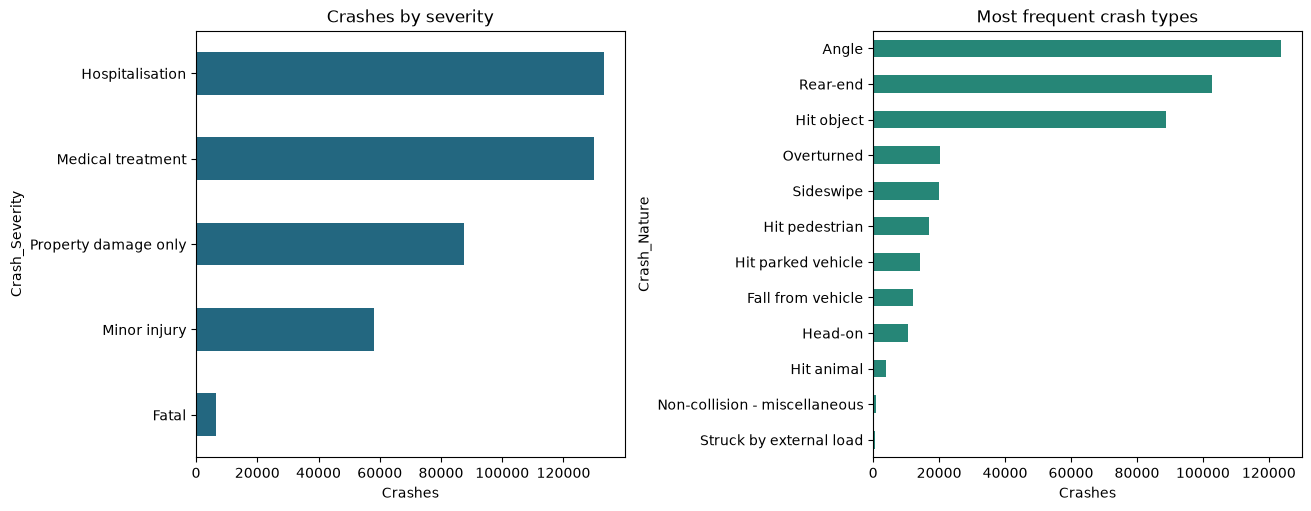

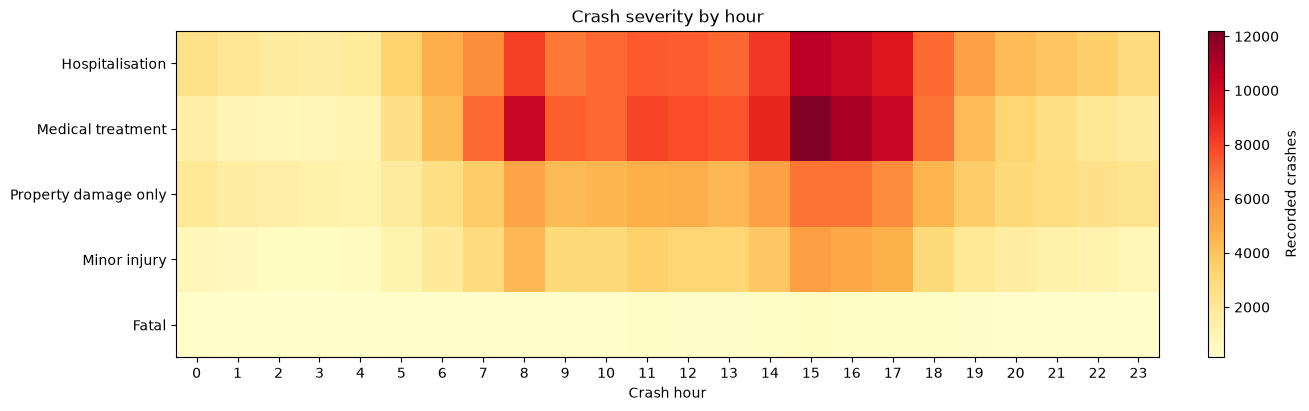

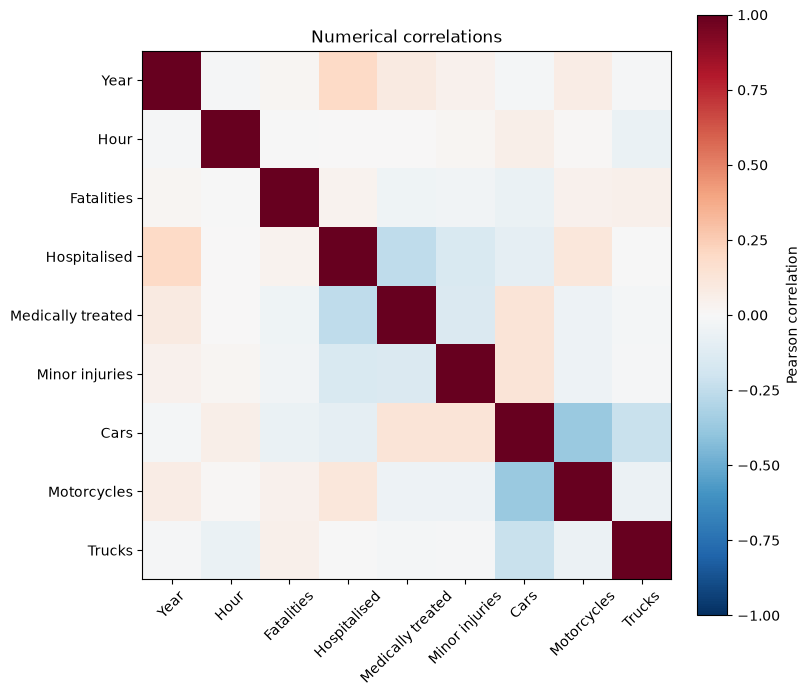

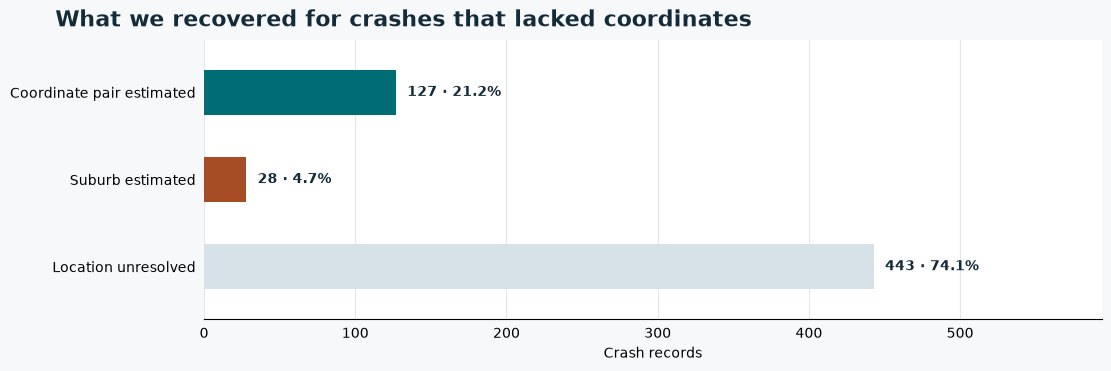

In [12]:
import matplotlib.pyplot as plt

severity = cleaned['Crash_Severity'].value_counts()
display(severity.to_frame('Crashes').assign(Share=(severity / len(cleaned)).map('{:.1%}'.format)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
severity.sort_values().plot.barh(ax=axes[0], color='#236780', title='Crashes by severity')
cleaned['Crash_Nature'].value_counts().head(12).sort_values().plot.barh(
    ax=axes[1], color='#268677', title='Most frequent crash types'
)
for ax in axes:
    ax.set_xlabel('Crashes')
plt.show()

hourly = pd.crosstab(cleaned['Crash_Severity'], cleaned['Crash_Hour']).reindex(severity.index)
fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
image = ax.imshow(hourly, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(len(hourly.columns)), xticklabels=hourly.columns,
       yticks=range(len(hourly)), yticklabels=hourly.index,
       xlabel='Crash hour', title='Crash severity by hour')
fig.colorbar(image, ax=ax, label='Recorded crashes')
plt.show()

numeric_features = [
    'Crash_Year', 'Crash_Hour', 'Count_Casualty_Fatality', 'Count_Casualty_Hospitalised',
    'Count_Casualty_MedicallyTreated', 'Count_Casualty_MinorInjury',
    'Count_Unit_Car', 'Count_Unit_Motorcycle_Moped', 'Count_Unit_Truck',
]
correlations = cleaned[numeric_features].corr()
labels = ['Year', 'Hour', 'Fatalities', 'Hospitalised', 'Medically treated',
          'Minor injuries', 'Cars', 'Motorcycles', 'Trucks']
fig, ax = plt.subplots(figsize=(8, 7), layout='constrained')
image = ax.imshow(correlations, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set(xticks=range(len(labels)), xticklabels=labels,
       yticks=range(len(labels)), yticklabels=labels, title='Numerical correlations')
ax.tick_params(axis='x', labelrotation=45)
fig.colorbar(image, ax=ax, label='Pearson correlation')
plt.show()


# Show what was recovered from the records that started with missing coordinates.
resolved_pair_count = int(available['Coordinate pair'].loc[targets].sum())
suburb_only_count = int((~available['Coordinate pair'] & available['Suburb']).loc[targets].sum())
missing_both_count = len(targets) - resolved_pair_count - suburb_only_count
fig, ax = plt.subplots(figsize=(11, 3.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('What we recovered for crashes that lacked coordinates', x=.045, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
categories = [
    ('Coordinate pair estimated', resolved_pair_count, '#006d75'),
    ('Suburb estimated', suburb_only_count, '#a64d25'),
    ('Location unresolved', missing_both_count, '#d7e1e8'),
]
counts = [count for _, count, _ in categories]
ax.barh(range(len(categories)), counts, color=[color for _, _, color in categories], height=.52)
ax.set(yticks=range(len(categories)), yticklabels=[label for label, _, _ in categories],
       ylim=(2.6, -.6), xlim=(0, max(counts) * 1.34), xlabel='Crash records')
for y, (_, count, _) in enumerate(categories):
    ax.annotate(f'{count:,} · {count / len(targets):.1%}', (count, y), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=10, color='#142b3a', fontweight='bold')
ax.grid(axis='x', color='#e1e8ed', zorder=0)
ax.set_axisbelow(True)
ax.tick_params(length=0, pad=6)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

**What this achieved.** Summarised crash severity, crash types, hour of day, numerical correlations and location recovery. Hospitalisation was the largest recorded severity category, and 15:00 had the most recorded crashes.

#### Map the crashes

Toggle the sampled density and severity layers. Inferred coordinates appear in their own optional layer. Its markers are approximate locations, with the estimation method in each tooltip. Both interactive maps use Esri World Street Map.

**In this cell.** Build a Folium map on an Esri basemap. Show observed crash density as a heatmap, add sampled markers by severity, and place estimated coordinates in their own map layer.

In [13]:
from html import escape

import folium
from folium.plugins import HeatMap

map_points = cleaned.dropna(subset=COORDS)
observed_points = map_points.loc[map_points['Coordinate_Method'].eq('observed')]
inferred_points = map_points.loc[map_points['Coordinate_Method'].ne('observed')]
severity_colors = {
    'Fatal': '#9d2525', 'Hospitalisation': '#db6820', 'Medical treatment': '#8c618f',
    'Minor injury': '#197a8c', 'Property damage only': '#456c46',
}
crash_map = folium.Map(
    location=observed_points[COORDS].median().tolist(), zoom_start=6, tiles='Esri.WorldStreetMap'
)
density_points = observed_points.sample(n=min(5000, len(observed_points)), random_state=SEED)
HeatMap(density_points[COORDS].to_numpy().tolist(), name='Observed crash density', radius=14).add_to(crash_map)

for level, color in severity_colors.items():
    layer = folium.FeatureGroup(name=level, show=False).add_to(crash_map)
    rows = observed_points.loc[observed_points['Crash_Severity'].eq(level), COORDS]
    for point in rows.sample(n=min(180, len(rows)), random_state=SEED).to_numpy().tolist():
        folium.CircleMarker(point, radius=3, color=color, fill=True, fill_opacity=.65,
                            weight=1, tooltip=level).add_to(layer)

estimate_layer = folium.FeatureGroup(name='Inferred coordinates', show=False).add_to(crash_map)
for lat, lon, method in inferred_points[[*COORDS, 'Coordinate_Method']].itertuples(index=False, name=None):
    folium.CircleMarker([lat, lon], radius=3, color='#53389e', fill=True, fill_opacity=.55,
                        weight=1, tooltip=escape(method)).add_to(estimate_layer)
folium.LayerControl(collapsed=False).add_to(crash_map)
display(crash_map)

**What this achieved.** Built an interactive Esri map with observed crash density, sampled severity markers and a separate layer for estimated coordinates.

#### Vehicle involvement and crash severity

Use the aggregate vehicle table and weight by `Count_Crashes`. Compare cases involving a motorcycle or moped, a truck, or a bus with cases without that particular flag. A crash can involve multiple vehicle types. Reported injury crashes are the common basis for severity and trend comparisons because property-damage-only coverage changes over time. The latest five complete years in the locations file set the comparison window. The partial 2025 series is excluded from full-year comparisons.

The fatal and hospitalisation shares describe severity among recorded injury crashes. Vehicle trips, distance travelled, and fleet exposure are outside the source data.

**In this cell.** Weight the vehicle analysis by reported crash counts and compare injury severity with and without each vehicle flag. Use annual trends, paired comparisons, and box plots to show how involvement and severity vary across complete years.

Vehicle severity comparison for 2020–2024


Injury crashes  ...  Fatal or hospitalisation (%)
Vehicle             Status                    ...                              
Motorcycle or moped Involved            8022  ...                         72.36
                    Absent             58602  ...                         46.79
Truck               Involved            4482  ...                         53.06
                    Absent             62142  ...                         49.64
Bus                 Involved             934  ...                         45.07
                    Absent             65690  ...                         49.94

[6 rows x 4 columns]

,Recorded injury crashes
None of these three flags,53437
Motorcycle or moped,7801
Truck,4268
Bus,867
Motorcycle or moped + Truck,184
Motorcycle or moped + Bus,37
Truck + Bus,30


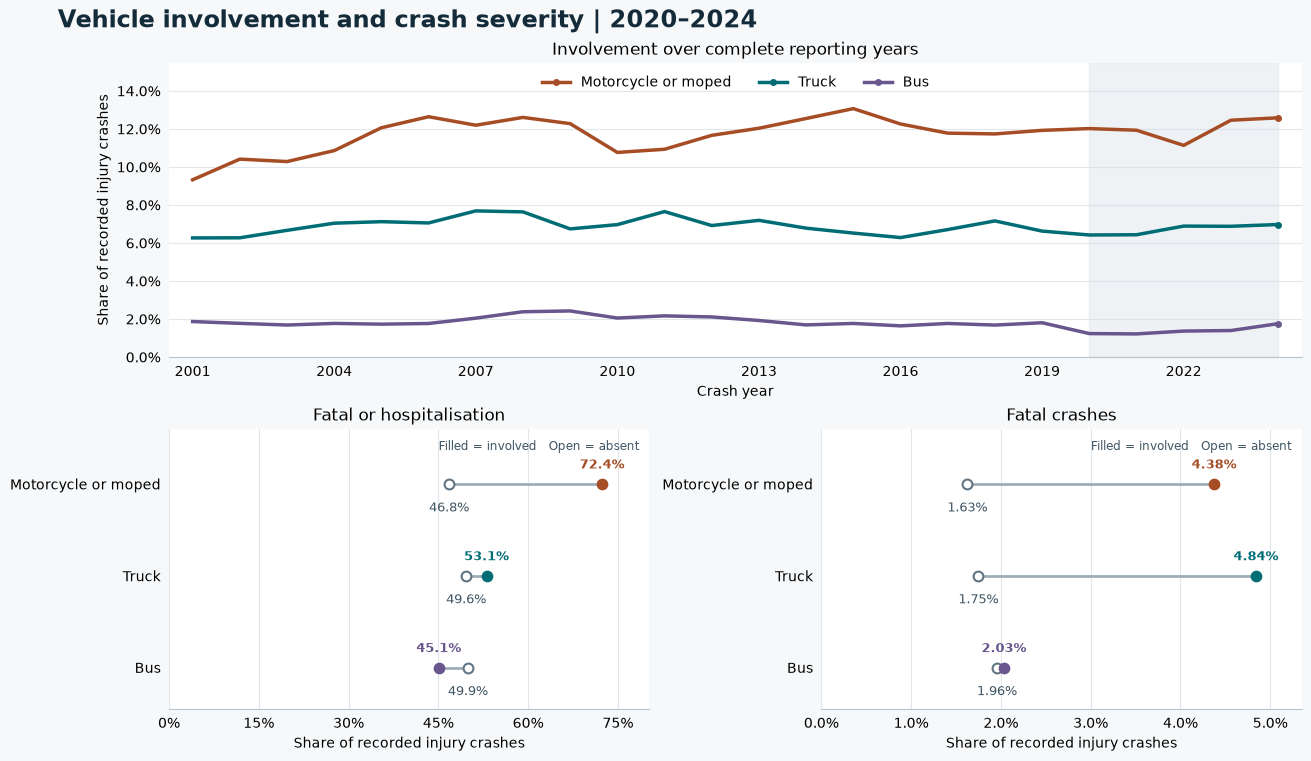

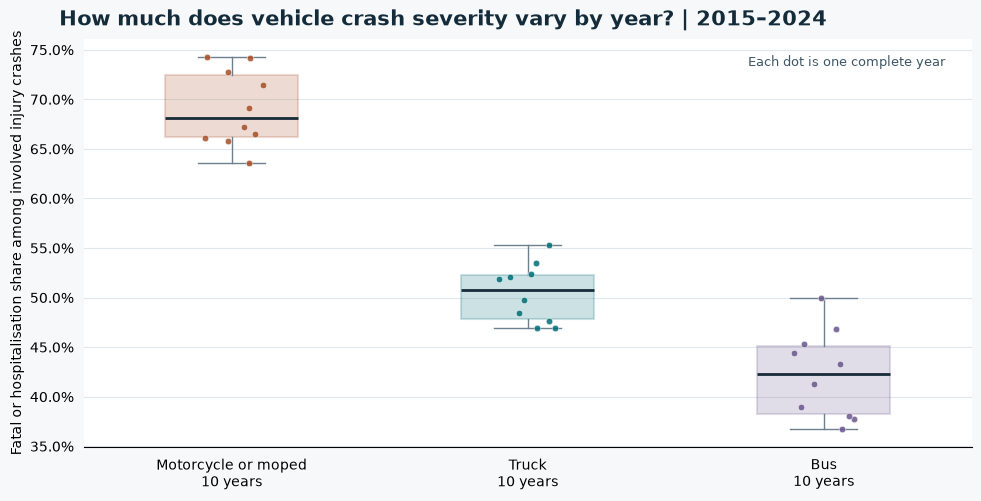

In [14]:
import matplotlib.ticker as mticker

complete_years = raw.groupby('Crash_Year')['Crash_Month'].nunique()
complete_years = complete_years.index[complete_years.eq(12)]
recent_years = complete_years[-5:]
injury_labels = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
severe_labels = ['Fatal', 'Hospitalisation']
vehicle_flags = {
    'Motorcycle or moped': 'Involving_Motorcycle_Moped',
    'Truck': 'Involving_Truck',
    'Bus': 'Involving_Bus',
}
vehicle_injury = regional_sources['Vehicles'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].copy()
vehicle_recent = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(recent_years)]
assert vehicle_recent['Crash_Severity'].isin(injury_labels).all()
vehicle_metrics = []
for kind, flag in vehicle_flags.items():
    for answer, label in [('Yes', 'Involved'), ('No', 'Absent')]:
        cohort = vehicle_recent.loc[vehicle_recent[flag].eq(answer)]
        counts = cohort.groupby('Crash_Severity')['Count_Crashes'].sum().reindex(injury_labels, fill_value=0)
        total = int(counts.sum())
        vehicle_metrics.append({
            'Vehicle': kind, 'Status': label, 'Injury crashes': total,
            'Fatal crashes': int(counts['Fatal']),
            'Fatal share (%)': 100 * counts['Fatal'] / total if total else np.nan,
            'Fatal or hospitalisation (%)': 100 * counts[severe_labels].sum() / total if total else np.nan,
        })
vehicle_severity = pd.DataFrame(vehicle_metrics).set_index(['Vehicle', 'Status'])
print(f'Vehicle severity comparison for {recent_years.min()}–{recent_years.max()}')
display(vehicle_severity.round(2))

annual_vehicle = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(complete_years)]
annual_vehicle_total = annual_vehicle.groupby('Crash_Year')['Count_Crashes'].sum()
vehicle_trends = pd.DataFrame({
    kind: annual_vehicle['Count_Crashes'].where(annual_vehicle[flag].eq('Yes'), 0)
    .groupby(annual_vehicle['Crash_Year']).sum().div(annual_vehicle_total).mul(100)
    for kind, flag in vehicle_flags.items()
})
flag_pattern_counts = vehicle_recent.groupby(list(vehicle_flags.values()))['Count_Crashes'].sum()
flag_labels = [' + '.join(kind for kind, value in zip(vehicle_flags, combination) if value == 'Yes')
               or 'None of these three flags' for combination in flag_pattern_counts.index]
vehicle_overlap = flag_pattern_counts.set_axis(flag_labels).sort_values(ascending=False)
assert vehicle_overlap.sum() == vehicle_recent['Count_Crashes'].sum()
display(vehicle_overlap.to_frame('Recorded injury crashes'))

fig = plt.figure(figsize=(13, 7.5), layout='constrained', facecolor='#f6f8fa')
grid = fig.add_gridspec(2, 2, height_ratios=[1.05, 1])
trend = fig.add_subplot(grid[0, :])
severity_axes = [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
fig.suptitle(f'Vehicle involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.04, ha='left', fontsize=17, fontweight='bold', color='#142b3a')
vehicle_colors = {'Motorcycle or moped': '#a64d25', 'Truck': '#006d75', 'Bus': '#68568d'}

for kind, color in vehicle_colors.items():
    trend.plot(vehicle_trends.index, vehicle_trends[kind], linewidth=2.5, color=color, label=kind,
               marker='o', markersize=4, markevery=[-1])
trend.axvspan(recent_years.min(), recent_years.max(), color='#cfdae4', alpha=.35)
trend.set(title='Involvement over complete reporting years', xlabel='Crash year',
          ylabel='Share of recorded injury crashes')
trend.yaxis.set_major_formatter(mticker.PercentFormatter())
trend.set_xlim(vehicle_trends.index.min() - .5, vehicle_trends.index.max() + .5)
trend.set_ylim(0, float(vehicle_trends.max().max()) + 2.4)
trend.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
trend.legend(loc='upper center', frameon=False, ncols=3, bbox_to_anchor=(.5, 1.0))

for ax, field, title, step in zip(
    severity_axes, ['Fatal or hospitalisation (%)', 'Fatal share (%)'],
    ['Fatal or hospitalisation', 'Fatal crashes'], [15, 1],
):
    by_flag = vehicle_severity[field].unstack().reindex(vehicle_flags)
    for y, (kind, row) in enumerate(by_flag.iterrows()):
        involved, absent = row['Involved'], row['Absent']
        ax.hlines(y, min(involved, absent), max(involved, absent), color='#9eaeb8', lw=2, zorder=2)
        ax.scatter(absent, y, s=50, facecolor='white', edgecolor='#637582', linewidth=1.5, zorder=3)
        ax.scatter(involved, y, s=55, color=vehicle_colors[kind], zorder=4)
        digits = 2 if field == 'Fatal share (%)' else 1
        ax.annotate(f'{absent:.{digits}f}%', (absent, y), xytext=(0, -13), textcoords='offset points',
                    ha='center', va='top', fontsize=9, color='#405664')
        ax.annotate(f'{involved:.{digits}f}%', (involved, y), xytext=(0, 9), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color=vehicle_colors[kind], fontweight='bold')
    ax.set(yticks=range(len(by_flag)), yticklabels=by_flag.index,
           ylim=(len(by_flag)-.55, -.6), xlim=(0, step * (np.ceil(by_flag.max().max()/step) + .35)),
           xlabel='Share of recorded injury crashes', title=title)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(step))
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.text(.98, .96, 'Filled = involved   Open = absent', transform=ax.transAxes,
            va='top', ha='right', fontsize=8.5, color='#405664')

for ax in [trend, *severity_axes]:
    ax.set_facecolor('white')
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#b8c4cc')
    ax.tick_params(length=0, pad=6)
    ax.grid(axis='y' if ax is trend else 'x', color='#e1e8ed', zorder=0)
    ax.set_axisbelow(True)
plt.show()


# Compare variability across years using one within-vehicle rate per complete year.
box_years = complete_years[-10:]
boxes = []
for kind, flag in vehicle_flags.items():
    involved = vehicle_injury.loc[vehicle_injury[flag].eq('Yes') & vehicle_injury['Crash_Year'].isin(box_years)]
    annual_totals = involved.groupby('Crash_Year')['Count_Crashes'].sum()
    annual_severe = involved['Count_Crashes'].where(involved['Crash_Severity'].isin(severe_labels), 0)
    annual_severe = annual_severe.groupby(involved['Crash_Year']).sum()
    boxes.append(annual_severe.div(annual_totals.where(annual_totals.gt(0))).mul(100).dropna().to_numpy())

fig, ax = plt.subplots(figsize=(9.7, 4.9), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'How much does vehicle crash severity vary by year? | {box_years.min()}–{box_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
boxplot = ax.boxplot(boxes, widths=.45, patch_artist=True, showfliers=False,
                     medianprops={'color': '#172b38', 'linewidth': 2},
                     whiskerprops={'color': '#6d808e'}, capprops={'color': '#6d808e'})
jitter = np.random.default_rng(SEED)
for x, ((kind, color), values, box) in enumerate(zip(vehicle_colors.items(), boxes, boxplot['boxes']), start=1):
    box.set(facecolor=color, alpha=.20, edgecolor=color, linewidth=1.5)
    ax.scatter(x + jitter.uniform(-.11, .11, len(values)), values,
               s=22, color=color, alpha=.85, edgecolor='white', linewidth=.4, zorder=3)
ax.set(xticks=range(1, len(boxes) + 1),
       xticklabels=[f'{kind}\n{len(values)} years' for kind, values in zip(vehicle_flags, boxes)],
       ylabel='Fatal or hospitalisation share among involved injury crashes')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(length=0, pad=7)
ax.text(.97, .96, 'Each dot is one complete year', transform=ax.transAxes,
        ha='right', va='top', fontsize=9, color='#405664')
plt.show()

**What this achieved.** Compared injury outcomes for the three vehicle flags using weighted crash counts. The plots show the recent severity contrast, annual involvement trends, and year-to-year variation over complete years.

#### Combine all six sources by crash year and police region

Aggregate each source to one row per year and police region before joining. Preserve each source’s own denominator. A crash can appear in several source summaries and can meet several flags, so use the source totals for their respective rates. Missing groups stay blank. This table uses the reported police regions for consistency across sources.

**In this cell.** Aggregate each source to one row per crash year and police region, then align the six totals on that key. Compare group coverage and retain blanks where a source has no row for a group.

In [15]:
regional_totals = {
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
}
for source_name, count_field in {
    'Factors': 'Count_Crashes', 'Casualties': 'Casualty_Count', 'Vehicles': 'Count_Crashes',
    'Demographics': 'Count_Crashes', 'Restraints': 'Casualty_Count',
}.items():
    regional_totals[source_name] = regional_sources[source_name].groupby(
        group_fields, dropna=False
    )[count_field].sum(min_count=1)

regional_summary = pd.concat(regional_totals, axis=1).sort_index().astype('Int64')
assert regional_summary.index.is_unique
for name, source_total in regional_totals.items():
    assert regional_summary[name].sum() == source_total.sum()
print(f'{len(regional_summary):,} year-region groups | '
      f'{regional_summary.notna().all(axis=1).sum():,} represented in all six files')
display(regional_summary.tail(12))
missing_sources = regional_summary.loc[regional_summary.isna().any(axis=1)]
if not missing_sources.empty:
    display(missing_sources)

186 year-region groups | 184 represented in all six files


Locations  Factors  ...  Demographics  Restraints
Crash_Year Police_Region                      ...                          
2024       Far Northern         723      723  ...           723         882
           North Coast         2745     2745  ...          2745        3382
           Northern             756      756  ...           756         904
           South Eastern       3141     3141  ...          3141        3846
           Southern            1852     1852  ...          1852        2497
2025       Brisbane            1889     1889  ...          1889        2221
           Central              585      585  ...           585         721
           Far Northern         345      345  ...           345         425
           North Coast         1372     1372  ...          1372        1724
           Northern             359      359  ...           359         432
           South Eastern       1529     1529  ...          1529        1896
           Southern             950      950  ...           950        1207

[12 rows x 6 columns]

,,Locations,Factors,Casualties,Vehicles,Demographics,Restraints
Crash_Year,Police_Region,,,,,,
2009,Unknown,7,7,<NA>,7,7,<NA>
2010,Unknown,36,36,<NA>,36,36,<NA>


**What this achieved.** Created a source totals table with one row per year and police region. All six files contribute to 184 of the 186 groups.

##### Explore vehicle involvement, driver characteristics, and safety

The flag table shows the share of each recorded severity group that involved each characteristic within its own source. The restraint table sums casualty counts by recorded restraint or helmet category. These descriptive counts reflect the reporting scope of the source tables.

**In this cell.** Calculate the share of crashes with each vehicle, driver, or contributing-factor flag within each recorded severity group. Summarise restraint categories with weighted casualty counts and plot annual casualty totals.

Crash severity (%)                     Hospitalisation  ...  Fatal
Source       Recorded factor                            ...       
Factors      Drink Driving                         9.5  ...   21.5
             Driver Speed                          5.1  ...   22.8
             Fatigued Driver                       2.9  ...    5.9
             Defective Vehicle                     2.2  ...    2.5
Vehicles     Motorcycle Moped                     17.0  ...   21.3
             Truck                                 7.0  ...   17.0
             Bus                                   1.6  ...    1.8
Demographics Male Driver                          76.3  ...   85.5
             Female Driver                        46.2  ...   27.9
             Young Driver 16-24                   33.4  ...   28.4
             Senior Driver 60plus                 21.1  ...   23.5
             Provisional Driver                   18.5  ...   15.1
             Overseas Licensed Driver              0.8  ...    1.2
             Unlicensed Driver                     7.3  ...   11.8

[14 rows x 5 columns]

Casualty_Severity,Fatality,Hospitalised,Medically treated,Minor injury
Casualty_Restraint_Helmet_Use,,,,
Helmet Not Worn,127,2082,841,445
Helmet Use Not determined,83,1386,1287,1757
Helmet Worn,1357,27944,16312,6043
Not applicable,54,809,704,450
Restrained,2408,94834,117813,61516
Restraint Use Not determined,1280,21456,26085,18976
Unrestrained,884,5135,3462,1618


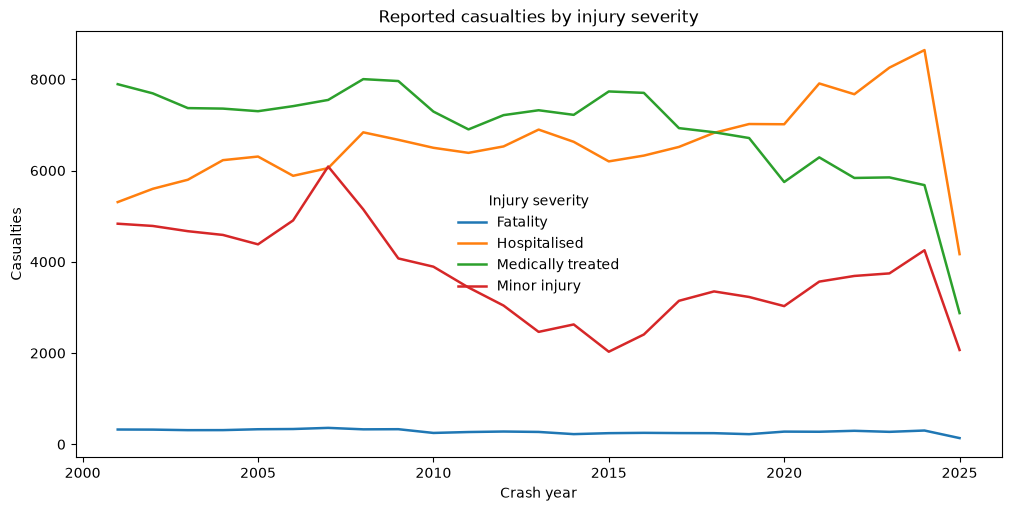

In [16]:
severity_flags = []
for source_name in ['Factors', 'Vehicles', 'Demographics']:
    frame = regional_sources[source_name]
    denominator = frame.groupby('Crash_Severity')['Count_Crashes'].sum()
    for flag in [column for column in frame if column.startswith('Involving_')]:
        yes_counts = (frame['Count_Crashes'].where(frame[flag].eq('Yes'), 0)
                      .groupby(frame['Crash_Severity']).sum())
        percentages = yes_counts.div(denominator.where(denominator.gt(0))).mul(100)
        severity_flags.append(percentages.rename((source_name, flag.removeprefix('Involving_').replace('_', ' '))))
flag_shares = pd.DataFrame(severity_flags)
flag_shares.index = pd.MultiIndex.from_tuples(flag_shares.index, names=['Source', 'Recorded factor'])
display(flag_shares.reindex(columns=severity.index).round(1).rename_axis('Crash severity (%)', axis=1))

safety_rows = regional_sources['Restraints']
restraint_counts = safety_rows.pivot_table(
    index='Casualty_Restraint_Helmet_Use', columns='Casualty_Severity',
    values='Casualty_Count', aggfunc='sum', fill_value=0,
)
display(restraint_counts)
annual_casualties = regional_sources['Casualties'].pivot_table(
    index='Crash_Year', columns='Casualty_Severity', values='Casualty_Count', aggfunc='sum',
)
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
annual_casualties.plot(ax=ax, linewidth=1.8)
ax.set(title='Reported casualties by injury severity', xlabel='Crash year', ylabel='Casualties')
ax.legend(title='Injury severity', frameon=False)
plt.show()

**What this achieved.** Compared weighted vehicle, driver and crash-factor flags by recorded severity and summarised helmet and restraint categories by injury outcome.

##### Compare regional burden, severity and reported contributing factors

Join weighted measures at `Crash_Year` and `Police_Region`, where the sources have common coverage. Compare recorded injury crash volume, the serious crash share, the severe casualty share, speed and fatigue flags, heavy vehicle and motorcycle involvement, young-driver involvement, and protective equipment use. Each measure keeps its own within-source denominator. The protective equipment share uses records with a known helmet or restraint status.

These comparisons can identify regions where several issues warrant closer examination and show whether a high count reflects volume or a higher severity share. Associations between regional summaries do not establish that the same crashes shared those characteristics. The latest five complete years are pooled by summing numerators and denominators. The source category `Unknown` remains in the coverage audit.

**In this cell.** Build regional profiles from within-source numerators and denominators. Use scatter, bubble, and heatmap views to compare crash burden, severity, and reported factors, then summarise changes across two five-year periods.

Combined regional profile, 2020–2024


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Police_Region,,,,,,,,,,
Brisbane,18395,40.1,37.1,2.4,1.3,4.9,6.6,12.5,32.3,2.3
South Eastern,14427,43.8,40.8,3.3,1.7,7.0,5.6,11.1,33.9,3.3
North Coast,13184,52.5,48.2,4.6,2.3,8.2,5.9,12.4,32.9,4.0
Southern,8161,56.9,51.9,4.8,3.2,8.0,8.6,11.1,33.1,4.2
Central,5568,66.5,60.9,5.2,4.6,9.8,9.6,11.2,31.3,5.0
Far Northern,3446,62.5,57.6,5.2,3.3,11.8,6.6,12.8,25.1,7.4
Northern,3443,61.1,56.2,4.6,2.7,9.5,6.1,14.9,30.9,7.2


,Highest police region,Value
Measure,,
Injury crashes,Brisbane,"18,395"
Serious crash (%),Central,66.5%
Speed (%),Far Northern,5.2%
Drink driving (%),Far Northern,11.8%
Truck (%),Central,9.6%
Motorcycle or moped (%),Northern,14.9%
Unrestrained or helmet not worn (%),Far Northern,7.4%


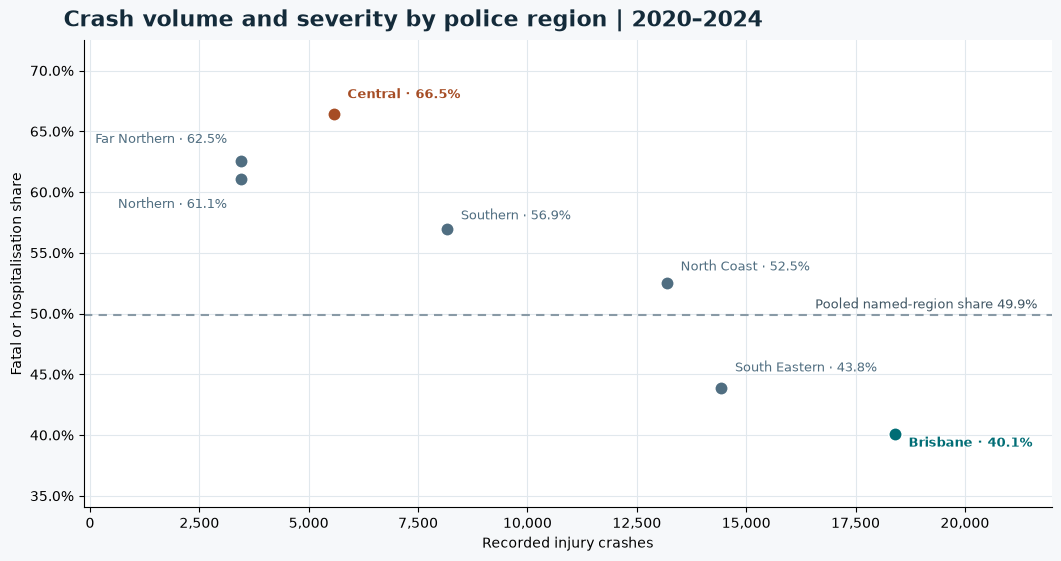

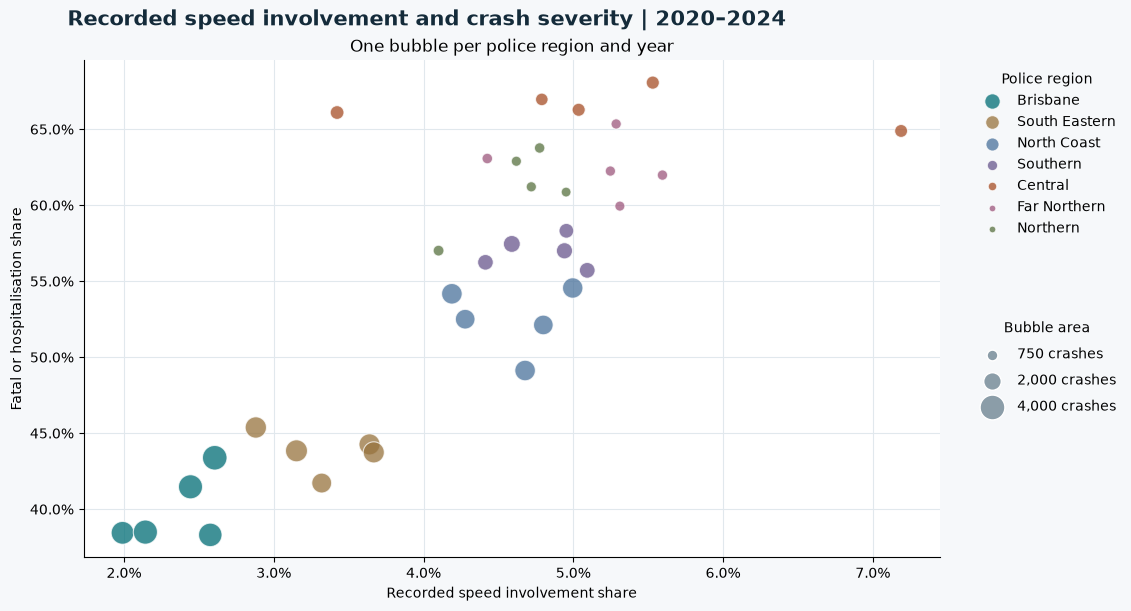

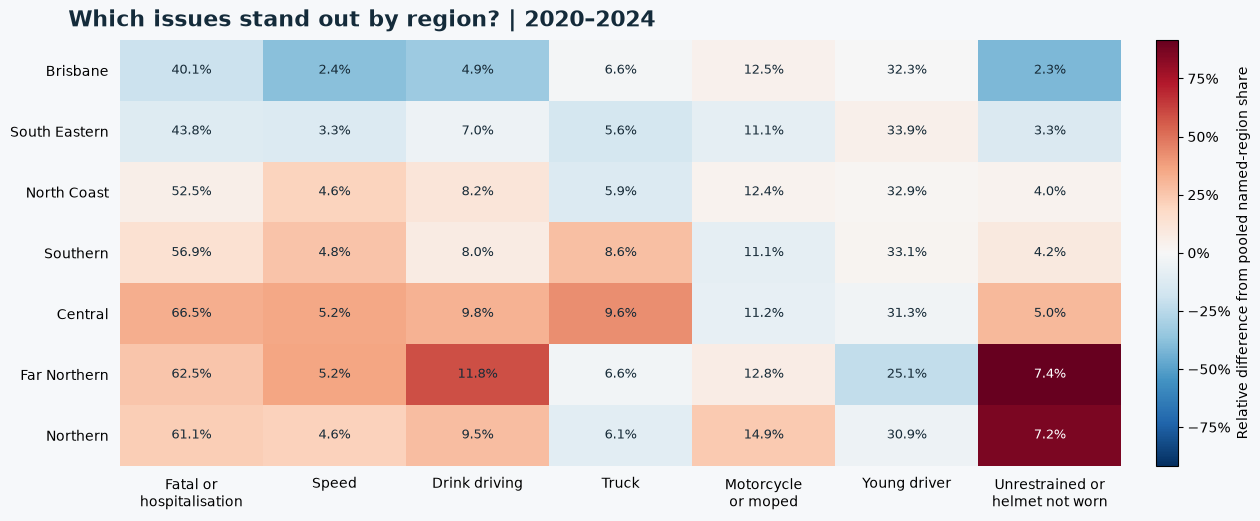

,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Period,,,,,,,,,,
2015–2019,63370,44.0,40.5,3.1,2.1,5.7,6.7,12.1,33.0,3.5
2020–2024,66624,49.9,46.2,3.8,2.3,7.4,6.7,12.0,32.3,3.9


In [17]:
def grouped_rate(frame, count, condition, group, label):
    denominator = frame.groupby(group, dropna=False)[count].sum(min_count=1)
    numerator = frame[count].where(condition, 0).groupby([frame[key] for key in group], dropna=False).sum()
    return pd.concat({f'{label} numerator': numerator, f'{label} denominator': denominator}, axis=1)


location_injury = regional_sources['Locations'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].assign(Records=1)
factor_injury = regional_sources['Factors'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
driver_injury = regional_sources['Demographics'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
casualty_records = regional_sources['Casualties']
known_equipment = safety_rows.loc[safety_rows['Casualty_Restraint_Helmet_Use'].isin([
    'Helmet Worn', 'Helmet Not Worn', 'Restrained', 'Unrestrained'
])]
metrics = {
    'Serious crash': (location_injury, 'Records', location_injury['Crash_Severity'].isin(severe_labels)),
    'Severe casualty': (casualty_records, 'Casualty_Count',
                        casualty_records['Casualty_Severity'].isin(['Fatality', 'Hospitalised'])),
    'Speed': (factor_injury, 'Count_Crashes', factor_injury['Involving_Driver_Speed'].eq('Yes')),
    'Fatigue': (factor_injury, 'Count_Crashes', factor_injury['Involving_Fatigued_Driver'].eq('Yes')),
    'Drink driving': (factor_injury, 'Count_Crashes', factor_injury['Involving_Drink_Driving'].eq('Yes')),
    'Truck': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Truck']].eq('Yes')),
    'Motorcycle or moped': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Motorcycle or moped']].eq('Yes')),
    'Young driver': (driver_injury, 'Count_Crashes', driver_injury['Involving_Young_Driver_16-24'].eq('Yes')),
    'Unrestrained or helmet not worn': (known_equipment, 'Casualty_Count',
        known_equipment['Casualty_Restraint_Helmet_Use'].isin(['Unrestrained', 'Helmet Not Worn'])),
}
regional_profile_counts = pd.concat([
    grouped_rate(frame, count, condition, group_fields, label)
    for label, (frame, count, condition) in metrics.items()
], axis=1)
assert regional_profile_counts.index.is_unique
for label in metrics:
    reported = regional_profile_counts[[f'{label} numerator', f'{label} denominator']].dropna()
    assert reported[f'{label} numerator'].le(reported[f'{label} denominator']).all()

regional_window = regional_profile_counts.loc[
    regional_profile_counts.index.get_level_values('Crash_Year').isin(recent_years)
    & (regional_profile_counts.index.get_level_values('Police_Region') != 'Unknown')
]
pooled_region = regional_window.groupby(level='Police_Region').sum(min_count=1)
regional_profile = pd.DataFrame({'Injury crashes': pooled_region['Serious crash denominator'].astype('Int64')})
for label in metrics:
    denominator = pooled_region[f'{label} denominator']
    regional_profile[f'{label} (%)'] = pooled_region[f'{label} numerator'].div(
        denominator.where(denominator.gt(0))
    ).mul(100)
regional_profile = regional_profile.sort_values('Injury crashes', ascending=False)
print(f'Combined regional profile, {recent_years.min()}–{recent_years.max()}')
display(regional_profile.round(1))

regional_findings = []
for field in ['Injury crashes', 'Serious crash (%)', 'Speed (%)', 'Drink driving (%)', 'Truck (%)',
              'Motorcycle or moped (%)', 'Unrestrained or helmet not worn (%)']:
    region = regional_profile[field].idxmax()
    value = regional_profile.at[region, field]
    formatted = f'{value:,}' if field == 'Injury crashes' else f'{value:.1f}%'
    regional_findings.append({'Measure': field, 'Highest police region': region, 'Value': formatted})
display(pd.DataFrame(regional_findings).set_index('Measure'))

fig, ax = plt.subplots(figsize=(10.5, 5.5), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Crash volume and severity by police region | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
reference = pooled_region['Serious crash numerator'].sum() / pooled_region['Serious crash denominator'].sum() * 100
ax.axhline(reference, color='#899aa6', linestyle=(0, (4, 3)), zorder=1)
ax.text(.985, reference + .55, f'Pooled named-region share {reference:.1f}%',
        transform=ax.get_yaxis_transform(), ha='right', fontsize=9, color='#405664')
label_offsets = {'Central': (10, 9), 'Far Northern': (-10, 11), 'Northern': (-10, -13),
                 'Southern': (10, 5), 'Brisbane': (10, -2), 'South Eastern': (10, 10)}
for region, row in regional_profile.iterrows():
    volume, serious_share = row[['Injury crashes', 'Serious crash (%)']]
    denotation = {'Brisbane': '#006d75', 'Central': '#a64d25'}.get(region, '#506e81')
    ax.scatter(volume, serious_share, s=95, color=denotation, edgecolor='white', linewidth=1.2, zorder=3)
    dx, dy = label_offsets.get(region, (10, 7))
    ax.annotate(f'{region} · {serious_share:.1f}%', (volume, serious_share), xytext=(dx, dy),
                textcoords='offset points', ha='right' if dx < 0 else 'left',
                va='bottom' if dy > 0 else 'top', color=denotation, fontsize=9,
                fontweight='bold' if region in {'Brisbane', 'Central'} else 'normal')
ax.set(xlabel='Recorded injury crashes', ylabel='Fatal or hospitalisation share')
ax.margins(x=.24, y=.23)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# Use one point per year and police region. Circle area represents injury crash volume.
speed_rate = (regional_window['Speed numerator'] / regional_window['Speed denominator'] * 100)
severity_rate = (regional_window['Serious crash numerator'] / regional_window['Serious crash denominator'] * 100)
bubble_data = pd.DataFrame({
    'Speed share': speed_rate, 'Severe share': severity_rate,
    'Injury crashes': regional_window['Serious crash denominator'],
}).dropna().reset_index()
region_colors = dict(zip(regional_profile.index,
                         ['#006d75', '#97733d', '#4a729b', '#68568d', '#a64d25', '#9d577d', '#587240']))
size_per_crash = .08
fig, ax = plt.subplots(figsize=(11.2, 6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Recorded speed involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
for region, color in region_colors.items():
    points = bubble_data[bubble_data['Police_Region'].eq(region)]
    ax.scatter(points['Speed share'], points['Severe share'], s=points['Injury crashes'] * size_per_crash,
               alpha=.75, color=color, edgecolor='white', linewidth=.8, label=region)
ax.set(xlabel='Recorded speed involvement share', ylabel='Fatal or hospitalisation share',
       title='One bubble per police region and year')
for axis in [ax.xaxis, ax.yaxis]:
    axis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
region_legend = ax.legend(title='Police region', bbox_to_anchor=(1.03, 1), loc='upper left',
                          frameon=False, markerscale=.65)
ax.add_artist(region_legend)
size_handles = [ax.scatter([], [], s=volume * size_per_crash, facecolor='#8b9da8', edgecolor='white',
                           label=f'{volume:,} crashes') for volume in [750, 2000, 4000]]
ax.legend(handles=size_handles, title='Bubble area', bbox_to_anchor=(1.03, .50),
          loc='upper left', frameon=False, labelspacing=.85)
plt.show()

from matplotlib.colors import TwoSlopeNorm

profile_fields = ['Serious crash', 'Speed', 'Drink driving', 'Truck', 'Motorcycle or moped', 'Young driver',
                  'Unrestrained or helmet not worn']
field_labels = ['Fatal or\nhospitalisation', 'Speed', 'Drink driving', 'Truck',
                'Motorcycle\nor moped', 'Young driver', 'Unrestrained or\nhelmet not worn']
profile_values = regional_profile[[f'{field} (%)' for field in profile_fields]].astype(float)
state_baseline = np.array([
    100 * pooled_region[f'{field} numerator'].sum() / pooled_region[f'{field} denominator'].sum()
    for field in profile_fields
])
relative = 100 * (profile_values.to_numpy() / state_baseline - 1)
color_limit = max(25, float(np.nanmax(np.abs(relative))))
norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)
fig, ax = plt.subplots(figsize=(12.5, 5.1), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Which issues stand out by region? | {recent_years.min()}–{recent_years.max()}',
             x=.05, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
image = ax.imshow(relative, cmap='RdBu_r', norm=norm, aspect='auto')
ax.set(xticks=range(len(field_labels)), xticklabels=field_labels, yticks=range(len(profile_values)),
       yticklabels=profile_values.index)
ax.tick_params(length=0, pad=8)
for row, col in np.ndindex(relative.shape):
    value = profile_values.iat[row, col]
    color = 'white' if abs(relative[row, col]) > .66 * color_limit else '#172b38'
    ax.text(col, row, f'{value:.1f}%' if np.isfinite(value) else '—',
            ha='center', va='center', color=color, fontsize=9, fontweight='medium')
ax.spines[:].set_visible(False)
scale = fig.colorbar(image, ax=ax, fraction=.033, pad=.035)
scale.set_label('Relative difference from pooled named-region share')
scale.ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.show()

# Compare early and recent periods consistently across all supplements.
recent_start = int(recent_years.min())
prior_years = list(range(recent_start - 5, recent_start))
comparison_years = [prior_years, list(recent_years)]
statewide_profile = []
for years in comparison_years:
    period = regional_profile_counts.loc[regional_profile_counts.index.get_level_values('Crash_Year').isin(years)]
    pooled = period.sum(min_count=1)
    values = {'Period': f'{years[0]}–{years[-1]}', 'Injury crashes': int(pooled['Serious crash denominator'])}
    for label in metrics:
        numerator, denominator = pooled[[f'{label} numerator', f'{label} denominator']]
        values[f'{label} (%)'] = 100 * numerator / denominator if pd.notna(denominator) and denominator > 0 else np.nan
    statewide_profile.append(values)
display(pd.DataFrame(statewide_profile).set_index('Period').round(1))

**What this achieved.** Compared regional crash volume, serious outcomes and reported factors with separate source denominators. For 2020–2024, Brisbane had the most injury crashes and Central had the highest fatal-or-hospitalisation share.

#### Export a flat file for casualty, restraint, driver and crash context

The CSV has one row per **crash year and police region**. Each set of columns is calculated from its own source before joining. The casualty and restraint files can be checked at a finer shared level using age group, recorded gender, road-user type, injury severity, year, and region. Road casualties reports drivers and passengers separately. The restraint file groups them as vehicle occupants.

The column prefixes identify their units and source:

- `casualty_` counts casualties from Road casualties, including separate driver and passenger totals by recorded gender.
- `seatbelt_`, `bicycle_helmet_`, and `motorcycle_helmet_` count casualties by equipment status and recorded gender from the restraint file. Columns ending in `_fatalities` count only fatalities within that category. Unknown and inapplicable status have their own columns.
- `driver_` and `factor_` count crashes with a reported flag from their respective files. A crash can meet more than one flag.
- `weather_` counts crashes and people killed by the atmospheric condition recorded in Road crash locations. Weather totals are available for the region and year as a whole.

A zero means the source reports the group and no records meet the condition. A blank means the source lacks that year-region group. Pool counts before calculating percentages. This dataset supports restraint-by-gender analysis among vehicle-occupant casualties and weather-by-fatality analysis overall. The files contain no joint breakdown linking gender, restraint status, and weather for the same casualty.

**In this cell.** Reconcile the casualty and restraint files by year, region, age, gender, road user, and injury severity. Aggregate the aligned data and the separate driver, crash-factor, and weather measures into a flat year–region export.

In [18]:
def count_flows_by_region(frame, value_column, masks):
    measures = pd.DataFrame({
        name: frame[value_column].where(mask, 0) for name, mask in masks.items()
    }, index=frame.index)
    return measures.groupby([frame[key] for key in group_fields], dropna=False).sum(min_count=1)


casualty_source = regional_sources['Casualties']
equipment_source = regional_sources['Restraints']
road_user_column = 'Casualty_Road_User_Type'
casualty_for_alignment = casualty_source.rename(columns={'Casualty_RoadUserType': road_user_column}).copy()
casualty_for_alignment[road_user_column] = casualty_for_alignment[road_user_column].replace(
    {'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'}
)
equipment_users = equipment_source[road_user_column].unique()
detail_key = [*group_fields, 'Casualty_AgeGroup', 'Casualty_Gender', road_user_column, 'Casualty_Severity']
casualty_equipment_detail = pd.concat({
    'Road casualties': casualty_for_alignment.loc[casualty_for_alignment[road_user_column].isin(equipment_users)]
        .groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
    'Restraint and helmet records': equipment_source.groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
}, axis=1).sort_index().astype('Int64')
detail_matches = casualty_equipment_detail['Road casualties'].fillna(0).eq(
    casualty_equipment_detail['Restraint and helmet records'].fillna(0)
)
print(f'Detailed casualty/equipment reconciliation: {int(detail_matches.sum()):,} of {len(detail_matches):,} groups match.')

gender_groups = ['Female', 'Male', 'Unknown']
any_casualty = casualty_source['Casualty_Count'].notna()
fatal_casualty = casualty_source['Casualty_Severity'].eq('Fatality')
casualty_masks = {'casualty_total': any_casualty, 'casualty_fatalities': fatal_casualty}
for gender in gender_groups:
    group = casualty_source['Casualty_Gender'].eq(gender)
    casualty_masks[f'casualty_{gender.lower()}_total'] = group
    casualty_masks[f'casualty_{gender.lower()}_fatalities'] = group & fatal_casualty
    for user in ['Driver', 'Passenger', 'Pedestrian', 'Bicyclist', 'Motorcyclist', 'Other']:
        belongs = group & casualty_source['Casualty_RoadUserType'].eq(user)
        prefix = f'casualty_{gender.lower()}_{user.lower()}'
        casualty_masks[f'{prefix}_total'] = belongs
        casualty_masks[f'{prefix}_fatalities'] = belongs & fatal_casualty
casualty_by_region = count_flows_by_region(casualty_source, 'Casualty_Count', casualty_masks)

seatbelt_labels = {
    'Restrained': 'restrained', 'Unrestrained': 'unrestrained',
    'Restraint Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
helmet_labels = {
    'Helmet Worn': 'worn', 'Helmet Not Worn': 'not_worn',
    'Helmet Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
equipment_masks = {}
equipment_fatal = equipment_source['Casualty_Severity'].eq('Fatality')
for road_user_type, prefix, labels in [
    ('Vehicle Occupant', 'seatbelt', seatbelt_labels),
    ('Bicyclist', 'bicycle_helmet', helmet_labels),
    ('Motorcyclist', 'motorcycle_helmet', helmet_labels),
]:
    for gender in gender_groups:
        group = equipment_source[road_user_column].eq(road_user_type) & equipment_source['Casualty_Gender'].eq(gender)
        equipment_masks[f'{prefix}_{gender.lower()}_total'] = group
        for reported, name in labels.items():
            state = group & equipment_source['Casualty_Restraint_Helmet_Use'].eq(reported)
            column = f'{prefix}_{gender.lower()}_{name}'
            equipment_masks[column] = state
            equipment_masks[f'{column}_fatalities'] = state & equipment_fatal
equipment_by_region = count_flows_by_region(equipment_source, 'Casualty_Count', equipment_masks)

crash_context = []
for source_name, prefix in [('Demographics', 'driver'), ('Factors', 'factor')]:
    frame = regional_sources[source_name]
    masks = {f'{prefix}_total_crashes': frame['Count_Crashes'].notna()}
    for field in frame.columns[frame.columns.str.startswith('Involving_')]:
        name = field.removeprefix('Involving_').lower().replace('-', '_')
        flagged = frame[field].eq('Yes')
        masks[f'{prefix}_{name}_crashes'] = flagged
        masks[f'{prefix}_{name}_fatal_crashes'] = flagged & frame['Crash_Severity'].eq('Fatal')
    crash_context.append(count_flows_by_region(frame, 'Count_Crashes', masks))

weather_source = regional_sources['Locations'].assign(One_Crash=1)
weather_masks = {'weather_total_crashes': weather_source['One_Crash'].eq(1)}
weather_fatality_masks = {'weather_total_fatalities': weather_source['One_Crash'].eq(1)}
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    suffix = condition.lower().replace('/', '_').replace(' ', '_')
    in_weather = weather_source['Crash_Atmospheric_Condition'].eq(condition)
    weather_masks[f'weather_{suffix}_crashes'] = in_weather
    weather_masks[f'weather_{suffix}_fatal_crashes'] = in_weather & weather_source['Crash_Severity'].eq('Fatal')
    weather_fatality_masks[f'weather_{suffix}_fatalities'] = in_weather
weather_counts = count_flows_by_region(weather_source, 'One_Crash', weather_masks)
weather_fatalities = count_flows_by_region(weather_source, 'Count_Casualty_Fatality', weather_fatality_masks)

casualty_context_flat = pd.concat([
    casualty_by_region, equipment_by_region, *crash_context, weather_counts, weather_fatalities,
], axis=1).sort_index().astype('Int64')
assert casualty_context_flat.index.is_unique and casualty_context_flat.columns.is_unique
assert casualty_context_flat['casualty_total'].sum() == casualty_source['Casualty_Count'].sum()
assert casualty_context_flat[[column for column in equipment_masks if column.endswith('_total')]].sum().sum() == equipment_source['Casualty_Count'].sum()
assert casualty_context_flat['weather_total_crashes'].sum() == len(raw)
assert casualty_context_flat['weather_total_fatalities'].sum() == raw['Count_Casualty_Fatality'].sum()
casualty_context_flat.insert(0, 'Complete_Year_in_Locations', casualty_context_flat.index.get_level_values('Crash_Year').isin(complete_years))
context_export = DATA_DIR / 'Traffic casualty restraint and crash context V3.csv'
write_csv(casualty_context_flat.reset_index(), context_export)
print(f'Exported {len(casualty_context_flat):,} year-region groups to {context_export.name}.')

Detailed casualty/equipment reconciliation: 23,375 of 23,375 groups match.
Exported 186 year-region groups to Traffic casualty restraint and crash context V3.csv.


**What this achieved.** Reconciled the casualty and equipment tables at their shared demographic grain. All 23,375 comparable groups agree. Exported a 186-row context table with one row per year and police region.

##### Examples the flat file can answer

Compare the share of female or male vehicle-occupant casualties who were unrestrained among those with a known seatbelt status. The same table shows outcomes among fatal casualties. For weather, compare total fatalities and fatalities per 100 recorded crashes across atmospheric conditions, for all people combined. Both examples use the latest five complete crash years.

**In this cell.** Pool the latest five complete years before calculating seatbelt non-use shares by recorded gender. Calculate weather-specific fatality counts and rates separately for all people.

In [19]:
context_recent = casualty_context_flat.loc[
    casualty_context_flat.index.get_level_values('Crash_Year').isin(recent_years)
].drop(columns='Complete_Year_in_Locations')
context_totals = context_recent.sum(min_count=1)
belt_examples = []
for gender in ['female', 'male']:
    prefix = f'seatbelt_{gender}'
    fastened = int(context_totals[f'{prefix}_restrained'])
    unfastened = int(context_totals[f'{prefix}_unrestrained'])
    fatal_fastened = int(context_totals[f'{prefix}_restrained_fatalities'])
    fatal_unfastened = int(context_totals[f'{prefix}_unrestrained_fatalities'])
    belt_examples.append({
        'Recorded gender': gender.title(),
        'Occupant casualties with known status': fastened + unfastened,
        'Unrestrained': unfastened,
        'Unrestrained share (%)': 100 * unfastened / (fastened + unfastened),
        'Fatalities with known status': fatal_fastened + fatal_unfastened,
        'Unrestrained fatalities': fatal_unfastened,
        'Unrestrained share of fatalities with known status (%)': 100 * fatal_unfastened / (fatal_fastened + fatal_unfastened),
    })
display(pd.DataFrame(belt_examples).set_index('Recorded gender').round(2))

weather_examples = []
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    field = condition.lower().replace('/', '_').replace(' ', '_')
    crashes = int(context_totals[f'weather_{field}_crashes'])
    deaths = int(context_totals[f'weather_{field}_fatalities'])
    weather_examples.append({
        'Atmospheric condition': condition,
        'Crashes': crashes,
        'Fatalities, all people': deaths,
        'Fatalities per 100 recorded crashes': 100 * deaths / crashes if crashes else np.nan,
    })
display(pd.DataFrame(weather_examples).set_index('Atmospheric condition').sort_values('Crashes', ascending=False).round(2))

,Occupant casualties with known status,Unrestrained,Unrestrained share (%),Fatalities with known status,Unrestrained fatalities,Unrestrained share of fatalities with known status (%)
Recorded gender,,,,,,
Female,31696,778,2.45,232,48,20.69
Male,28440,1116,3.92,464,140,30.17


,Crashes,"Fatalities, all people",Fatalities per 100 recorded crashes
Atmospheric condition,,,
Clear,59763,1264,2.12
Raining,6382,140,2.19
Fog,375,17,4.53
Smoke/Dust,104,3,2.88
Unknown,0,0,NaN


**What this achieved.** Calculated separate restraint and weather examples for 2020–2024. Among female occupant casualties with known restraint status, 778 of 31,696 were unrestrained. Weather counts cover all people in the locations file.

##### Charts and Esri maps for the flat file

These visuals use the latest five complete years. The seatbelt chart and bubble map use **vehicle-occupant casualties with known seatbelt status**. The weather chart and shaded police-region map describe **fatalities among all people**. The maps display the 2026 QPS boundary layer for the named police regions.

**In this cell.** Draw paired bars for known-status seatbelt non-use among all and fatal occupant casualties. Plot weather conditions as bubbles, with recorded crash volume on the horizontal axis and fatalities represented by bubble area.

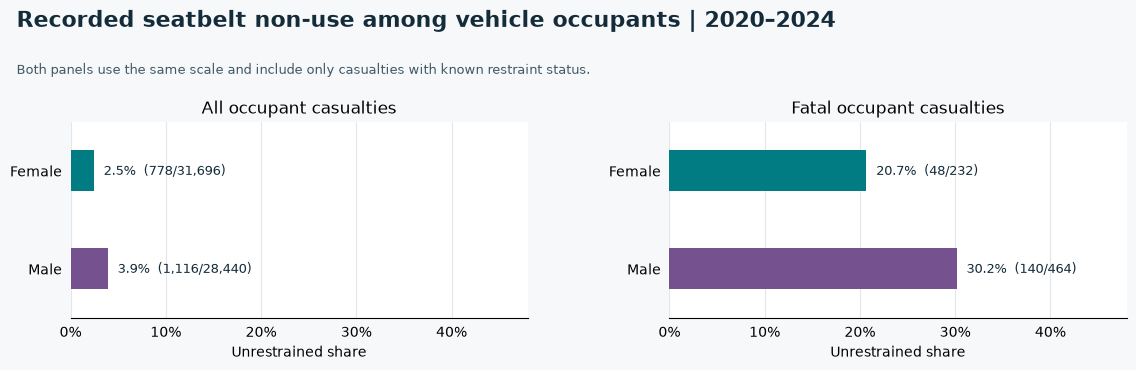

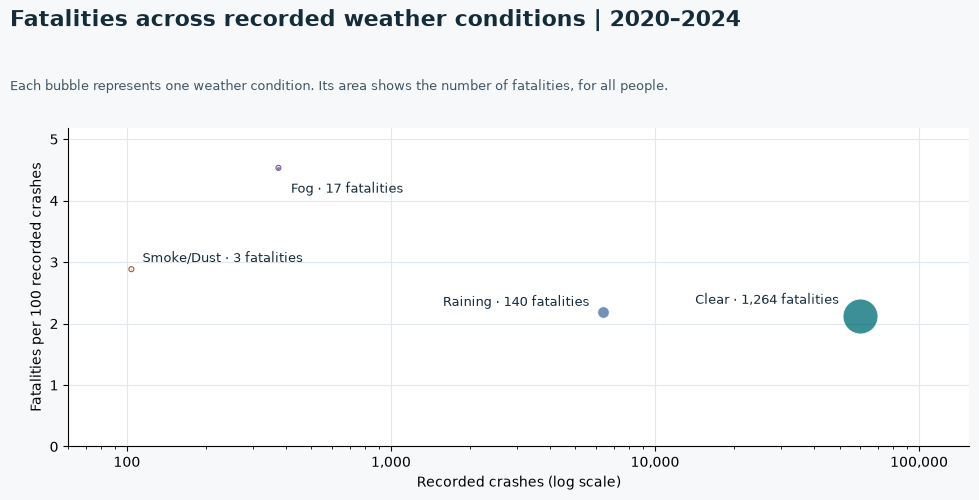

In [20]:
# Use the flat-file aggregates and pool counts before deriving shares.
context_period = f'{recent_years.min()}–{recent_years.max()}'
belt_chart = pd.DataFrame(belt_examples).set_index('Recorded gender')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.10, right=.98, bottom=.21, top=.70, wspace=.31)
fig.suptitle(f'Recorded seatbelt non-use among vehicle occupants | {context_period}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055,.82,'Both panels use the same scale and include only casualties with known restraint status.',
         fontsize=9.5,color='#405664')
for ax, percent, numerator, denominator, title in [
    (axes[0], 'Unrestrained share (%)', 'Unrestrained', 'Occupant casualties with known status',
     'All occupant casualties'),
    (axes[1], 'Unrestrained share of fatalities with known status (%)',
     'Unrestrained fatalities', 'Fatalities with known status', 'Fatal occupant casualties'),
]:
    y=np.arange(len(belt_chart))
    ax.barh(y,belt_chart[percent],height=.42,color=['#007c82','#76518f'])
    ax.set(yticks=y, yticklabels=belt_chart.index, ylim=(len(y)-.5,-.5),
           xlim=(0, 48),title=title,xlabel='Unrestrained share')
    for pos, (_, row) in enumerate(belt_chart.iterrows()):
        ax.annotate(f"{row[percent]:.1f}%  ({int(row[numerator]):,}/{int(row[denominator]):,})",
                    (row[percent],pos),xytext=(7,0),textcoords='offset points',
                    color='#142b3a',va='center',fontsize=9)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.spines[['top','right','left']].set_visible(False)
    ax.grid(axis='x',color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.tick_params(length=0,pad=6)
plt.show()

weather_chart = pd.DataFrame(weather_examples).loc[lambda d:d['Crashes'].gt(0)]
weather_palette = {'Clear':'#006d75','Raining':'#4a729b','Fog':'#76518f','Smoke/Dust':'#a64d25'}
fig, ax = plt.subplots(figsize=(10.6,5.4),facecolor='#f6f8fa')
fig.subplots_adjust(left=.11,right=.96,bottom=.17,top=.76)
fig.suptitle(f'Fatalities across recorded weather conditions | {context_period}',
             x=.055,ha='left',fontsize=16,fontweight='bold',color='#142b3a')
fig.text(.055,.83,'Each bubble represents one weather condition. Its area shows the number of fatalities, for all people.',
         fontsize=9.5,color='#405664')
weather_offsets = {'Clear':(-15,12),'Raining':(-10,7),'Fog':(9,-15),'Smoke/Dust':(8,8)}
for row in weather_chart.to_dict('records'):
    label = row['Atmospheric condition']
    x, y = row['Crashes'], row['Fatalities per 100 recorded crashes']
    color = weather_palette[label]
    ax.scatter(x, y, s=row['Fatalities, all people']/2, color=color, alpha=.77,
               edgecolor='white', linewidth=.7, zorder=4)
    if row['Fatalities, all people'] < 20:
        ax.scatter(x, y, s=13, facecolor='none', edgecolor=color, linewidth=.75, zorder=5)
    dx, dy = weather_offsets[label]
    ax.annotate(f"{label} · {row['Fatalities, all people']:,} fatalities", (x,y), xytext=(dx,dy),
                textcoords='offset points', ha='right' if dx<0 else 'left', va='center',
                fontsize=9, color='#142b3a')
ax.set(xscale='log', xlim=(60,155000), ylim=(0,max(weather_chart['Fatalities per 100 recorded crashes'])+.65),
       xlabel='Recorded crashes (log scale)',ylabel='Fatalities per 100 recorded crashes')
ax.xaxis.set_major_locator(mticker.FixedLocator([100,1000,10000,100000]))
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
plt.show()

**What this achieved.** Plotted known-status restraint shares for all and fatal occupant casualties and compared all-person fatality counts and rates by weather.

##### Map restraint and weather patterns by region

**In this cell.** Build two Esri maps using police-region boundaries and pooled counts. Size the restraint bubbles by the number of female occupant casualties with known status, and shade regions in the weather map by the share of all fatalities recorded in rain.

In [21]:
import folium
from branca.colormap import LinearColormap
from html import escape as escape_map_text
from shapely.geometry import mapping

context_regions = context_recent.groupby(level='Police_Region').sum(min_count=1)
context_regions = context_regions.loc[context_regions.index != 'Unknown']
context_regions['female_known'] = context_regions['seatbelt_female_restrained'] + context_regions['seatbelt_female_unrestrained']
context_regions['female_unrestrained_share'] = (
    context_regions['seatbelt_female_unrestrained']
    .div(context_regions['female_known'].where(context_regions['female_known'].gt(0))).mul(100)
)
context_regions['rain_fatality_share'] = (
    context_regions['weather_raining_fatalities']
    .div(context_regions['weather_total_fatalities'].where(context_regions['weather_total_fatalities'].gt(0))).mul(100)
)

region_shapes = {}
for (region,), geometry in shapefile_polygons(SPATIAL_DIR / 'police.zip', ('REGION',)):
    region_shapes.setdefault(region.title(), []).append(geometry)
region_shapes = {
    region: union_all(parts).simplify(.008, preserve_topology=True)
    for region, parts in region_shapes.items() if region in context_regions.index
}
assert set(region_shapes) == set(context_regions.index)


def context_esri_map(title, detail):
    view = folium.Map(location=[-22.6, 146.8], zoom_start=5, tiles='Esri.WorldStreetMap',
                      control_scale=True)
    header = folium.Element(
        '<div style="position:absolute;top:12px;left:52px;z-index:1000;max-width:340px;'
        'padding:8px 11px;background:#fbfdff;color:#173347;'
        'border:1px solid #b9c9d5;border-radius:5px;box-shadow:0 1px 4px #33445550;font-size:12px">'
        f'<strong>{escape_map_text(title)}</strong><br>{escape_map_text(detail)}</div>'
    )
    view.get_root().html.add_child(header)
    return view


belt_bubble_map = context_esri_map(
    f'Female occupant restraint records | {context_period}',
    'Bubble area shows casualties with known status. Colour shows the unrestrained share.',
)
belt_scale = LinearColormap(['#e9f3f5','#55a6aa','#056572'], vmin=0,
                            vmax=float(context_regions['female_unrestrained_share'].max()),
                            caption='% of female occupant casualties unrestrained among known status')
folium.GeoJson({
    'type':'FeatureCollection',
    'features':[{'type':'Feature','geometry':mapping(shape),'properties':{'region':region}}
                for region,shape in region_shapes.items()],
}, style_function=lambda feature: {'fillOpacity':0,'color':'#58788d','weight':1,'opacity':.65},
    name='Police regions').add_to(belt_bubble_map)
max_known = context_regions['female_known'].max()
for region, row in context_regions.iterrows():
    point = region_shapes[region].representative_point()
    rate = float(row['female_unrestrained_share'])
    label = folium.Tooltip(
        f"<b>{escape_map_text(region)}</b><br>{int(row['seatbelt_female_unrestrained']):,} of "
        f"{int(row['female_known']):,} with known status ({rate:.1f}%)"
    )
    folium.CircleMarker([point.y,point.x],radius=25*np.sqrt(row['female_known']/max_known),
                        color='#193e51',weight=1.25,fill=True,fill_color=belt_scale(rate),
                        fill_opacity=.9,tooltip=label).add_to(belt_bubble_map)
belt_scale.add_to(belt_bubble_map)
display(belt_bubble_map)

rain_region_map = context_esri_map(
    f'Fatalities recorded in rain | {context_period}',
    'Each police region is shaded by the share of all recorded fatalities that occurred in rain.',
)
rain_scale = LinearColormap(['#b8d7e8','#5486ad','#234d7c'], vmin=0,
                            vmax=float(context_regions['rain_fatality_share'].max()),
                            caption='% of fatalities recorded in rain, all people')
rain_shapes=[]
for region in context_regions.index:
    row=context_regions.loc[region]
    rate=float(row['rain_fatality_share'])
    rain_shapes.append({
        'type':'Feature','geometry':mapping(region_shapes[region]),
        'properties':{'region':region,'rain':int(row['weather_raining_fatalities']),
                      'total':int(row['weather_total_fatalities']),'percent':f'{rate:.1f}%',
                      'color':rain_scale(rate)},
    })
folium.GeoJson(
    {'type':'FeatureCollection','features':rain_shapes},
    style_function=lambda feature: {'fillColor':feature['properties']['color'],'fillOpacity':.67,
                                    'color':'#23445d','weight':1.15},
    tooltip=folium.GeoJsonTooltip(fields=['region','rain','total','percent'],
                                   aliases=['Police region','Fatalities in rain','All fatalities','Share in rain']),
).add_to(rain_region_map)
rain_scale.add_to(rain_region_map)
display(rain_region_map)

**What this achieved.** Built two interactive Esri maps for the seven named police regions. The bubble map shows female occupant restraint records. The shaded map shows the share of all recorded fatalities that occurred in rain.

#### Two- and three-level Sankey diagrams

Both diagrams cover the latest five complete reporting years. The two-level vehicle diagram assigns every injury crash with at least one of the three vehicle flags to one vehicle group, then shows its crash severity. The three-level safety diagram shows road-user type, reported restraint or helmet status, and injury severity for casualties with known equipment status. Band widths show recorded counts. Adjacent bands summarize the categories on either side of that stage.

**In this cell.** Build Sankey diagrams from weighted counts across two or three categories. Reconcile totals at each stage so the band widths reflect the counts moving between adjacent categories.

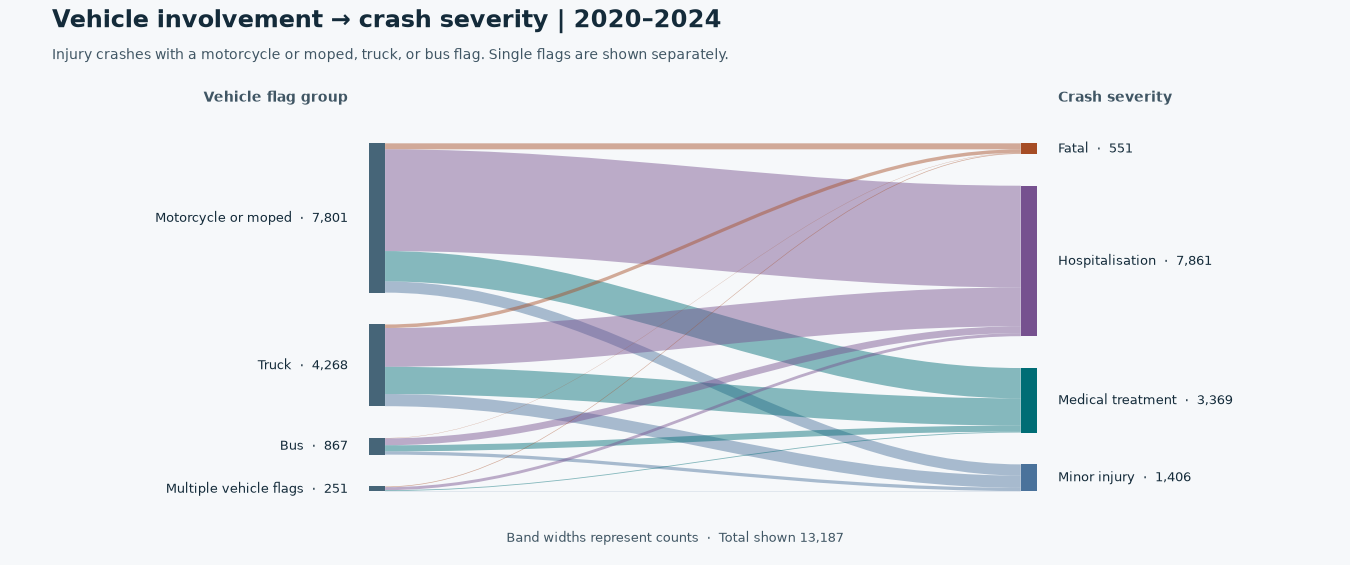

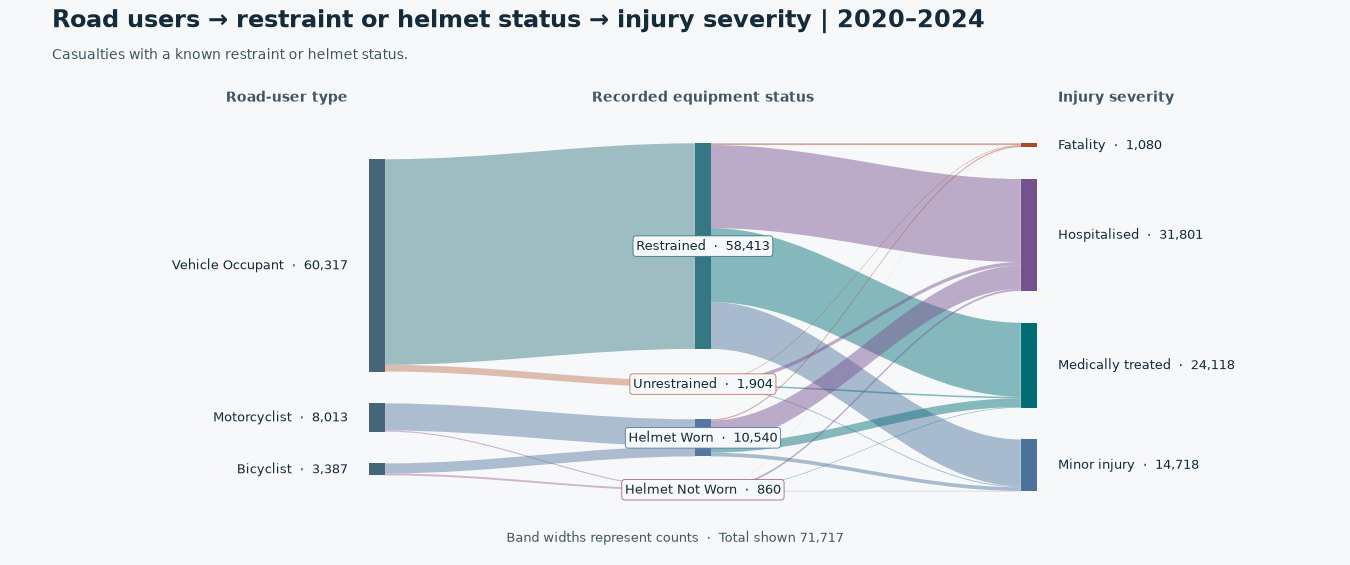

In [22]:
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch, Rectangle


def count_sankey(records, levels, orders, headers, title, caption):
    assert 2 <= len(levels) <= 3
    total = int(records['Count'].sum())
    node_totals = [
        records.groupby(field)['Count'].sum().reindex(order).fillna(0).astype(int)
        for field, order in zip(levels, orders)
    ]
    node_totals = [values.loc[values.gt(0)] for values in node_totals]
    assert total > 0 and all(values.sum() == total for values in node_totals)

    outcome_colors = dict(zip(orders[-1], ['#a64d25', '#76518f', '#006d75', '#4a729b']))
    equipment_colors = dict(zip(orders[-2], ['#357884', '#c27754', '#5678a0', '#a06693']))
    stage_colors = ([{}, outcome_colors] if len(levels) == 2 else
                    [{}, equipment_colors, outcome_colors])
    gap, width = .065, .012
    height_per_record = (.71 - gap * (max(map(len, node_totals)) - 1)) / total
    xs = np.linspace(.27, .76, len(levels))

    def node_bottoms(totals):
        heights = totals * height_per_record
        occupied = heights.sum() + gap * (len(heights) - 1)
        return .485 + occupied / 2 - (heights + gap).cumsum() + gap

    bottoms = [node_bottoms(totals) for totals in node_totals]
    fig, ax = plt.subplots(figsize=(14, 5.8), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.025, right=.975, bottom=.035, top=.88)
    fig.text(.055, .945, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.055, .89, caption, fontsize=10, color='#405664')
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')

    for stage, (left_field, right_field) in enumerate(zip(levels, levels[1:])):
        left_totals, right_totals = node_totals[stage:stage+2]
        links = records.pivot_table(index=left_field, columns=right_field, values='Count',
                                    aggfunc='sum', fill_value=0)
        links = links.reindex(index=left_totals.index, columns=right_totals.index, fill_value=0)
        assert links.sum(axis=1).equals(left_totals) and links.sum(axis=0).equals(right_totals)
        left_top = bottoms[stage] + left_totals * height_per_record
        right_top = bottoms[stage + 1] + right_totals * height_per_record
        x0, x1 = xs[stage] + width, xs[stage + 1]
        control0, control1 = x0 + .36 * (x1 - x0), x1 - .36 * (x1 - x0)
        for start, destinations in links.iterrows():
            for end, count in destinations.items():
                if count <= 0:
                    continue
                height = count * height_per_record
                a, b = left_top[start], right_top[end]
                vertices = [(x0, a), (control0, a), (control1, b), (x1, b),
                            (x1, b-height), (control1, b-height),
                            (control0, a-height), (x0, a-height), (x0, a)]
                path = PlotPath(vertices, [PlotPath.MOVETO, *([PlotPath.CURVE4] * 3),
                                           PlotPath.LINETO, *([PlotPath.CURVE4] * 3), PlotPath.CLOSEPOLY])
                ax.add_patch(PathPatch(path, facecolor=stage_colors[stage + 1][end],
                                       edgecolor='none', alpha=.46))
                left_top[start] -= height
                right_top[end] -= height

    for stage, (x, totals, header, colors) in enumerate(zip(xs, node_totals, headers, stage_colors)):
        align = 'right' if stage == 0 else 'left' if stage == len(levels) - 1 else 'center'
        label_x = x - .016 if align == 'right' else x + width + .016 if align == 'left' else x + width / 2
        ax.text(label_x, .925, header, ha=align, color='#405664', fontweight='bold')
        for label, count in totals.items():
            bottom = bottoms[stage][label]
            height = count * height_per_record
            ax.add_patch(Rectangle((x, bottom), width, height, facecolor=colors.get(label, '#466578')))
            box = {'facecolor': '#f6f8fa', 'edgecolor': colors.get(label, '#466578'),
                   'boxstyle': 'round,pad=.24', 'linewidth': .6} if align == 'center' else None
            ax.text(label_x, bottom + height / 2, f'{label}  ·  {count:,}',
                    ha=align, va='center', fontsize=9.5, color='#142b3a', bbox=box)
    ax.text(.5, .035, f'Band widths represent counts  ·  Total shown {total:,}',
            ha='center', va='center', fontsize=9, color='#405664')
    plt.show()


vehicle_groups = ['Motorcycle or moped', 'Truck', 'Bus', 'Multiple vehicle flags']
vehicle_flag_values = vehicle_recent[list(vehicle_flags.values())].eq('Yes')
flag_counts = vehicle_flag_values.sum(axis=1)
vehicle_group = pd.Series(pd.NA, dtype='string', index=vehicle_recent.index)
for label, column in vehicle_flags.items():
    vehicle_group.loc[flag_counts.eq(1) & vehicle_flag_values[column]] = label
vehicle_group.loc[flag_counts.gt(1)] = vehicle_groups[-1]
vehicle_records = (vehicle_recent.assign(Vehicle_group=vehicle_group)
                   .dropna(subset='Vehicle_group')
                   .rename(columns={'Count_Crashes': 'Count'}))
assert int(vehicle_records['Count'].sum()) == vehicle_recent.loc[flag_counts.gt(0), 'Count_Crashes'].sum()
period = f'{recent_years.min()}–{recent_years.max()}'
count_sankey(
    vehicle_records, ['Vehicle_group', 'Crash_Severity'], [vehicle_groups, injury_labels],
    ['Vehicle flag group', 'Crash severity'],
    f'Vehicle involvement → crash severity | {period}',
    'Injury crashes with a motorcycle or moped, truck, or bus flag. Single flags are shown separately.',
)

restraint_categories = ['Restrained', 'Unrestrained', 'Helmet Worn', 'Helmet Not Worn']
restraint_window = safety_rows.loc[
    safety_rows['Crash_Year'].isin(recent_years)
    & safety_rows['Casualty_Restraint_Helmet_Use'].isin(restraint_categories)
].rename(columns={'Casualty_Count': 'Count'})
count_sankey(
    restraint_window, ['Casualty_Road_User_Type', 'Casualty_Restraint_Helmet_Use', 'Casualty_Severity'],
    [['Vehicle Occupant', 'Motorcyclist', 'Bicyclist'], restraint_categories,
     ['Fatality', 'Hospitalised', 'Medically treated', 'Minor injury']],
    ['Road-user type', 'Recorded equipment status', 'Injury severity'],
    f'Road users → restraint or helmet status → injury severity | {period}',
    'Casualties with a known restraint or helmet status.',
)


**What this achieved.** Plotted weighted flows from the recorded vehicle flag group to crash severity, and from road-user type through equipment status to injury severity.

##### Sankey of recorded gender, seatbelt status and injury severity

Flow widths use observed casualty counts for vehicle occupants with known restraint status. The restraint file directly records all three variables. The road casualties file reconciles the totals at a shared demographic level. Driver flags, crash factors, and weather remain year-and-region context.

**In this cell.** Filter to vehicle-occupant casualties with a known restraint status. Reconcile the female and male totals against the flat file, then plot flows from recorded gender through belt status to injury severity.

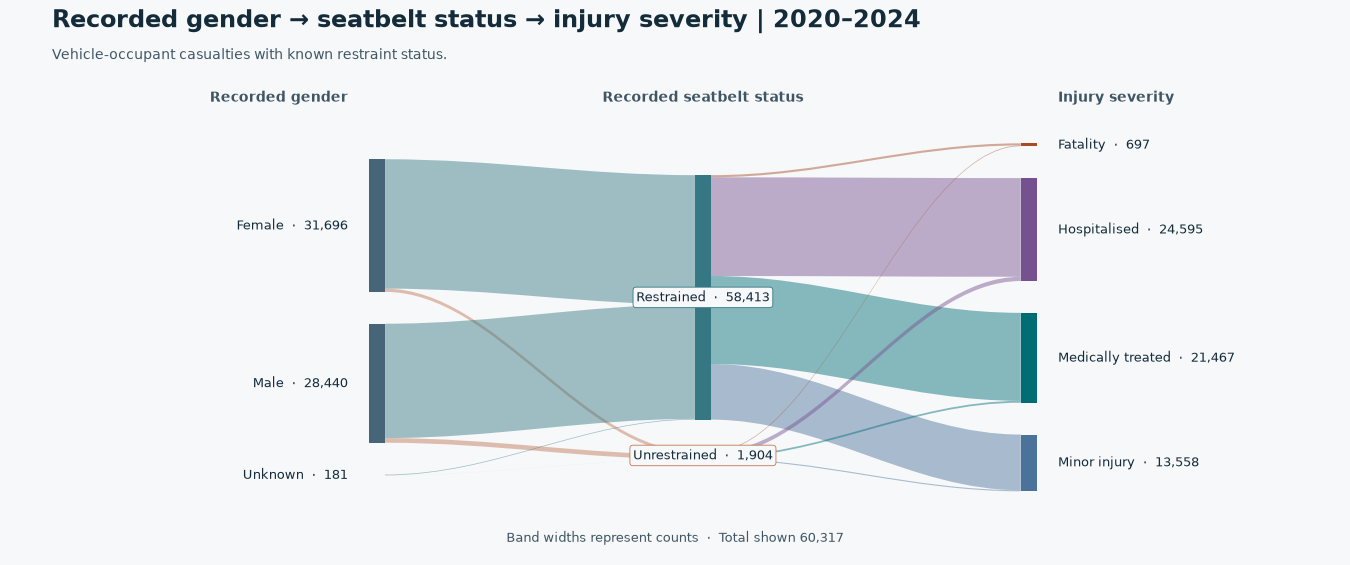

In [23]:
belt_sankey_records = equipment_source.loc[
    equipment_source['Crash_Year'].isin(recent_years)
    & equipment_source[road_user_column].eq('Vehicle Occupant')
    & equipment_source['Casualty_Restraint_Helmet_Use'].isin(['Restrained','Unrestrained'])
].rename(columns={'Casualty_Count':'Count'})
belt_record_counts = belt_sankey_records.groupby('Casualty_Gender')['Count'].sum()
assert belt_record_counts['Female'] == context_totals['seatbelt_female_restrained'] + context_totals['seatbelt_female_unrestrained']
assert belt_record_counts['Male'] == context_totals['seatbelt_male_restrained'] + context_totals['seatbelt_male_unrestrained']
count_sankey(
    belt_sankey_records, ['Casualty_Gender','Casualty_Restraint_Helmet_Use','Casualty_Severity'],
    [['Female','Male','Unknown'],['Restrained','Unrestrained'],
     ['Fatality','Hospitalised','Medically treated','Minor injury']],
    ['Recorded gender','Recorded seatbelt status','Injury severity'],
    f'Recorded gender → seatbelt status → injury severity | {context_period}',
    'Vehicle-occupant casualties with known restraint status.',
)

**What this achieved.** Plotted recorded gender, known seatbelt status and injury severity together using occupant casualty counts. The female and male totals agree with the flat-file values.

#### Treemaps of crash counts and severity

Each outlined group contains smaller tiles for the severity categories. Areas are proportional to recorded injury crash counts and colours identify severity. The regional treemap shows the named police regions. The vehicle treemap shows crashes with at least one motorcycle or moped, truck, or bus flag. Single-flag crashes and crashes with multiple flags occupy separate groups.

**In this cell.** Lay out nested treemap tiles proportional to recorded injury crash counts. Group tiles by police region or vehicle flag group, with severity shown by colour.

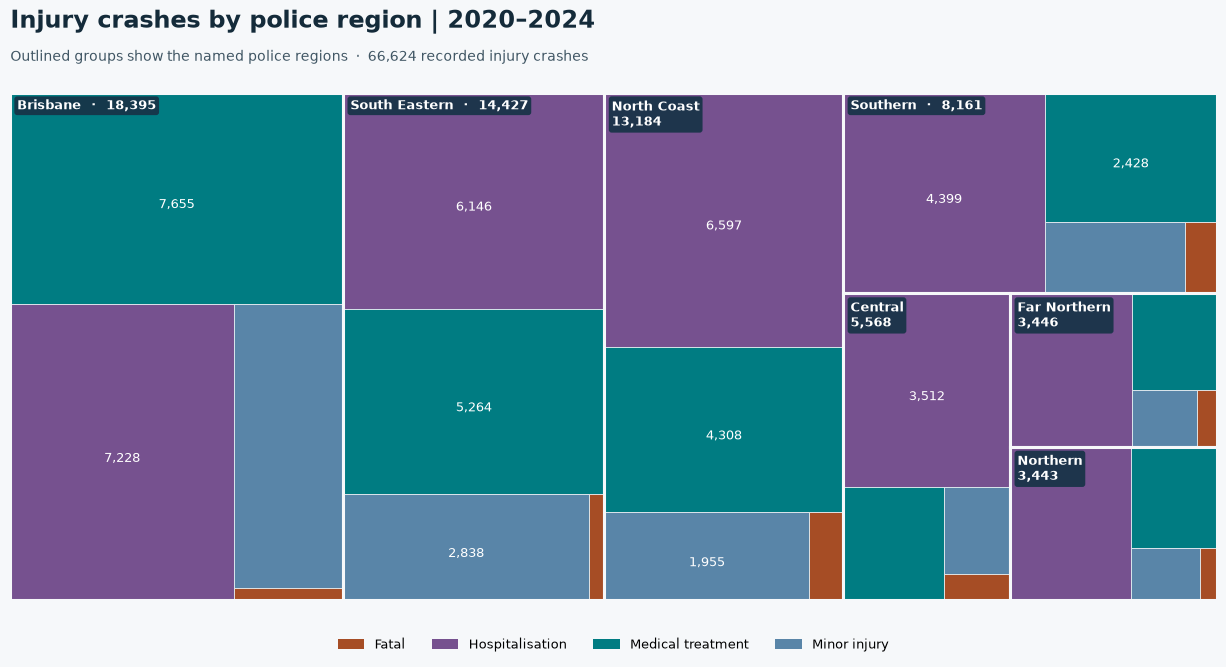

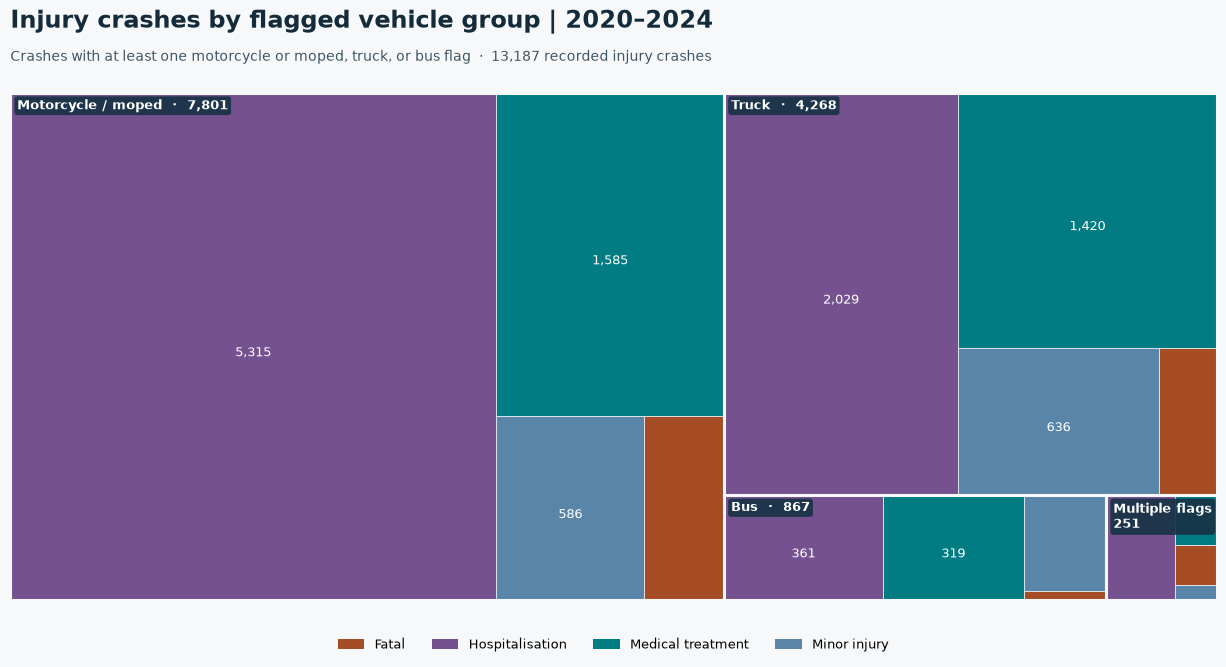

In [24]:
from matplotlib.patches import Patch


def area_tiles(groups, x, y, width, height):
    # Split the larger dimension in proportion to recorded counts.
    if len(groups) == 1:
        yield groups[0][0], x, y, width, height
        return
    values = np.array([count for _, count in groups])
    total = values.sum()
    split = int(np.abs(values.cumsum()[:-1] - total / 2).argmin()) + 1
    fraction = values[:split].sum() / total
    if width >= height:
        edge = width * fraction
        yield from area_tiles(groups[:split], x, y, edge, height)
        yield from area_tiles(groups[split:], x + edge, y, width - edge, height)
    else:
        edge = height * fraction
        yield from area_tiles(groups[:split], x, y + height - edge, width, edge)
        yield from area_tiles(groups[split:], x, y, width, height - edge)


def count_treemap(counts, title, subtitle):
    colors = {'Fatal': '#a64d25', 'Hospitalisation': '#76518f',
              'Medical treatment': '#007c82', 'Minor injury': '#5985a8'}
    totals = counts.sum(axis=1)
    groups = totals.loc[totals.gt(0)].sort_values(ascending=False)
    assert len(groups) and counts.ge(0).all(axis=None)
    total = int(groups.sum())
    width, height = 12.6, 5.3
    fig, ax = plt.subplots(figsize=(13.4, 7.05), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.035, right=.965, bottom=.135, top=.855)
    fig.text(.05, .947, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.05, .9, f'{subtitle}  ·  {total:,} recorded injury crashes',
             fontsize=10, color='#405664')
    ax.set(xlim=(0, width), ylim=(0, height), aspect='equal')
    ax.axis('off')
    outer_area = 0
    for group, x, y, group_width, group_height in area_tiles(list(groups.items()), 0, 0, width, height):
        outer_area += group_width * group_height
        values = counts.loc[group].loc[lambda row: row.gt(0)].sort_values(ascending=False)
        assert np.isclose(group_width * group_height, width * height * groups[group] / total)
        for severity_label, sx, sy, sw, sh in area_tiles(list(values.items()), x, y, group_width, group_height):
            assert np.isclose(sw * sh, width * height * values[severity_label] / total)
            ax.add_patch(Rectangle((sx, sy), sw, sh, facecolor=colors[severity_label],
                                   edgecolor='#e4edf1', linewidth=.6))
            if sw >= 1.30 and sh >= .85:
                ax.text(sx + sw / 2, sy + sh / 2 - .07, f'{values[severity_label]:,}',
                        color='white', ha='center', va='center', fontsize=9)
        ax.add_patch(Rectangle((x, y), group_width, group_height, fill=False,
                               edgecolor='#f6f8fa', linewidth=2.2))
        short_names = {'Motorcycle or moped': 'Motorcycle / moped',
                       'Multiple vehicle flags': 'Multiple flags'}
        name = short_names.get(group, group)
        label = f'{name}  ·  {groups[group]:,}'
        if group_width < 2.65:
            label = f'{name}\n{groups[group]:,}'
        ax.text(x + .075, y + group_height - .07, label, ha='left', va='top',
                color='white', fontsize=9, fontweight='bold', zorder=5,
                bbox=dict(facecolor='#173347', edgecolor='none', boxstyle='round,pad=.23', alpha=.92))
    assert np.isclose(outer_area, width * height)
    fig.legend(handles=[Patch(facecolor=color, label=label) for label, color in colors.items()],
               loc='lower center', bbox_to_anchor=(.5, .045), ncols=4, frameon=False, fontsize=9.5)
    plt.show()


treemap_region = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
]
region_tiles = pd.crosstab(treemap_region['Police_Region'], treemap_region['Crash_Severity'])
assert region_tiles.to_numpy().sum() == len(treemap_region)
count_treemap(region_tiles, f'Injury crashes by police region | {period}',
              'Outlined groups show the named police regions')

vehicle_tiles = vehicle_records.pivot_table(
    index='Vehicle_group', columns='Crash_Severity', values='Count', aggfunc='sum', fill_value=0,
)
assert vehicle_tiles.to_numpy().sum() == vehicle_records['Count'].sum()
count_treemap(vehicle_tiles, f'Injury crashes by flagged vehicle group | {period}',
              'Crashes with at least one motorcycle or moped, truck, or bus flag')

**What this achieved.** Built treemaps sized by injury crash counts. Tiles show the severity mix within each named police region and flagged vehicle group.

#### Pie charts of severity and location recovery

The severity pie uses recorded injury crashes from the latest five complete years. The recovery pie uses all crash records that originally lacked coordinates. Each chart shows mutually exclusive outcomes and its own total.

**In this cell.** Create two pie charts from separate totals. Use complete-year injury crashes for the severity mix and the records originally lacking coordinates for the location-recovery breakdown.

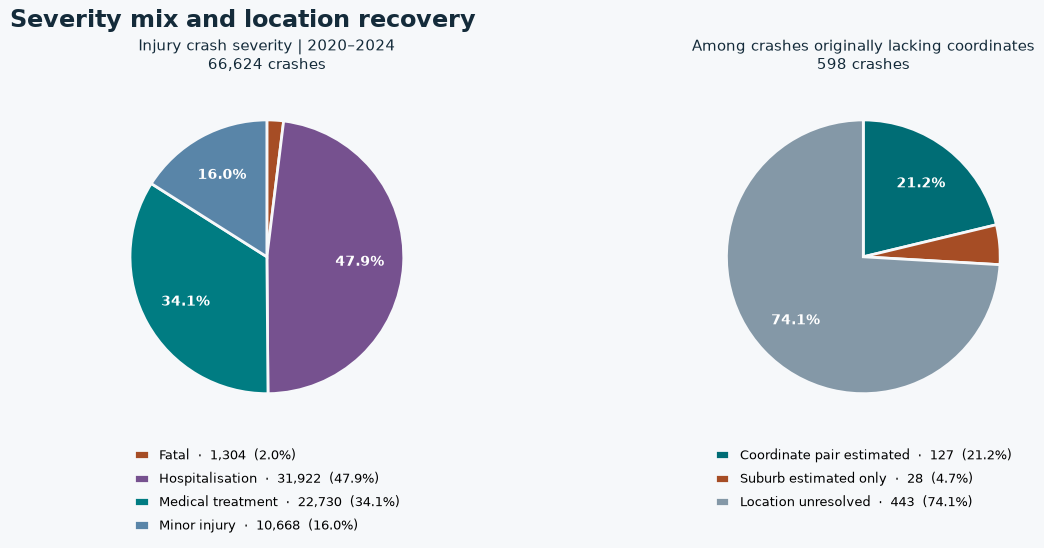

In [25]:
severity_pie = (location_injury.loc[location_injury['Crash_Year'].isin(recent_years), 'Crash_Severity']
                .value_counts().reindex(injury_labels, fill_value=0))
recovered_pair = available['Coordinate pair'].loc[targets]
recovered_suburb = ~recovered_pair & available['Suburb'].loc[targets]
recovery_pie = pd.Series({
    'Coordinate pair estimated': int(recovered_pair.sum()),
    'Suburb estimated only': int(recovered_suburb.sum()),
    'Location unresolved': int((~recovered_pair & ~recovered_suburb).sum()),
})
assert recovery_pie.sum() == len(targets)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.9), facecolor='#f6f8fa')
fig.subplots_adjust(left=.06, right=.94, bottom=.27, top=.85, wspace=.25)
fig.suptitle('Severity mix and location recovery', x=.045, ha='left',
             fontsize=17, fontweight='bold', color='#142b3a')
for ax, values, title, colors in [
    (axes[0], severity_pie, f'Injury crash severity | {period}',
     ['#a64d25', '#76518f', '#007c82', '#5985a8']),
    (axes[1], recovery_pie, 'Among crashes originally lacking coordinates',
     ['#006d75', '#a64d25', '#8498a7']),
]:
    total = int(values.sum())
    wedges, _, annotations = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=.68,
        autopct=lambda pct: f'{pct:.1f}%' if pct >= 7 else '',
        wedgeprops={'edgecolor': '#f6f8fa', 'linewidth': 2},
        textprops={'fontsize': 10, 'color': 'white', 'weight': 'bold'},
    )
    ax.set_title(f'{title}\n{total:,} crashes', fontsize=11, pad=12, color='#142b3a')
    details = [f'{label}  ·  {count:,}  ({count/total:.1%})' for label, count in values.items()]
    ax.legend(wedges, details, loc='upper center', bbox_to_anchor=(.5, -.025),
              frameon=False, fontsize=9.5, labelspacing=.7, handlelength=1.1)
plt.show()

**What this achieved.** Showed the injury severity mix for 2020–2024 and the three location-recovery outcomes for the 598 crashes that originally lacked coordinates.

#### Associations that change when we compare like with like

These figures use 2020–2024, the latest five complete years. They compare regional patterns, crash-level combinations of lighting and road surface, and flag associations within their original source tables. These are descriptive comparisons. Travel exposure and many other differences between crashes are unavailable.

**In this cell.** Compare the pooled speed–severity correlation across region-years with the correlation of residuals after accounting for region and year using least squares. Plot both views side by side.

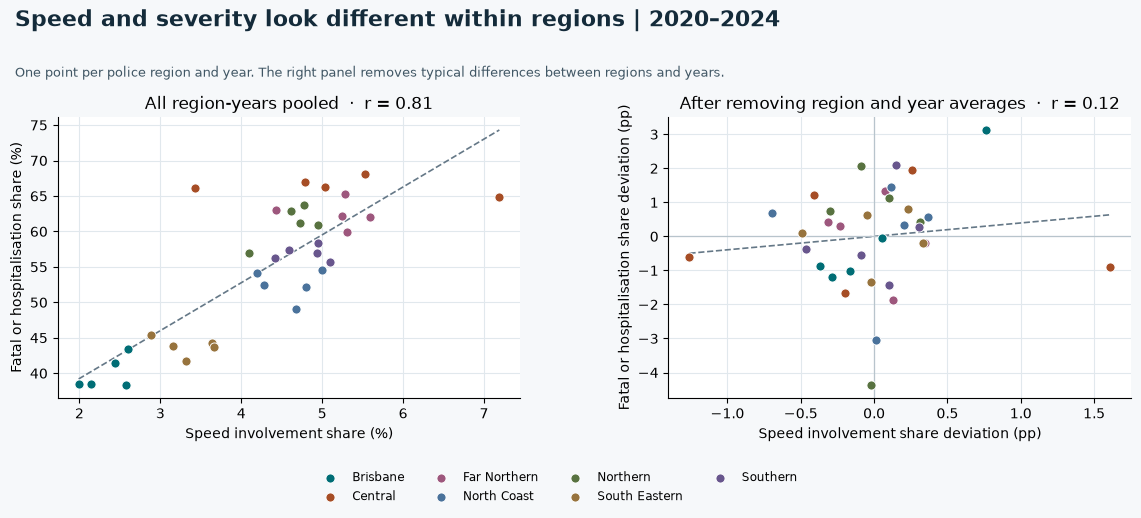

In [26]:
# Compare the pooled region-year pattern with deviations from typical region and year levels.
within_fields = ['Speed', 'Serious crash']
regional_rates = pd.DataFrame({
    label: regional_window[f'{label} numerator'].div(
        regional_window[f'{label} denominator'].where(regional_window[f'{label} denominator'].gt(0))
    ).mul(100) for label in within_fields
}).dropna().reset_index()
indicators = pd.get_dummies(
    regional_rates[['Crash_Year', 'Police_Region']].astype(str), drop_first=True, dtype=float
)
design = np.column_stack([np.ones(len(indicators)), indicators.to_numpy()])
observed_rates = regional_rates[within_fields].to_numpy()
residual_rates = observed_rates - design @ np.linalg.lstsq(design, observed_rates, rcond=None)[0]
pooled_r = float(np.corrcoef(observed_rates.T)[0, 1])
within_r = float(np.corrcoef(residual_rates.T)[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.09, right=.97, bottom=.26, top=.78, wspace=.32)
fig.suptitle(f'Speed and severity look different within regions | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .855, 'One point per police region and year. The right panel removes typical differences between regions and years.',
         fontsize=9.5, color='#405664')
for ax, values, heading, r, suffix in [
    (axes[0], observed_rates, 'All region-years pooled', pooled_r, ' (%)'),
    (axes[1], residual_rates, 'After removing region and year averages', within_r, ' deviation (pp)'),
]:
    for region, rows in regional_rates.groupby('Police_Region'):
        positions = rows.index
        ax.scatter(values[positions, 0], values[positions, 1], s=43,
                   color=region_colors[region], edgecolor='white', linewidth=.65, label=region, zorder=3)
    x_values = np.array([values[:, 0].min(), values[:, 0].max()])
    ax.plot(x_values, np.polyval(np.polyfit(values[:, 0], values[:, 1], 1), x_values),
            linestyle='--', color='#657887', linewidth=1.2)
    ax.set(title=f'{heading}  ·  r = {r:.2f}', xlabel=f'Speed involvement share{suffix}',
           ylabel=f'Fatal or hospitalisation share{suffix}')
    ax.grid(color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(0, color='#b8c4cc', linewidth=.9)
axes[1].axvline(0, color='#b8c4cc', linewidth=.9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, .045),
           ncols=4, frameon=False, fontsize=8.8)
plt.show()

**What this achieved.** Compared pooled region-year speed and severity shares with their deviations after accounting for region and year. The correlation fell from 0.81 to 0.12.

##### Lighting and wet-road comparisons

**In this cell.** Use direct standardisation to compare wet and dry sealed roads under the same police-region and speed-zone mix. Show severe crash shares and the wet-minus-dry difference for each lighting condition.

Crash_Road_Surface_Condition,Sealed - Dry,Sealed - Wet,Wet − dry (pp)
Crash_Lighting_Condition,,,
Daylight,44.3,46.1,1.8
Darkness - Lighted,54.7,51.9,-2.9
Darkness - Not lighted,64.3,64.0,-0.2


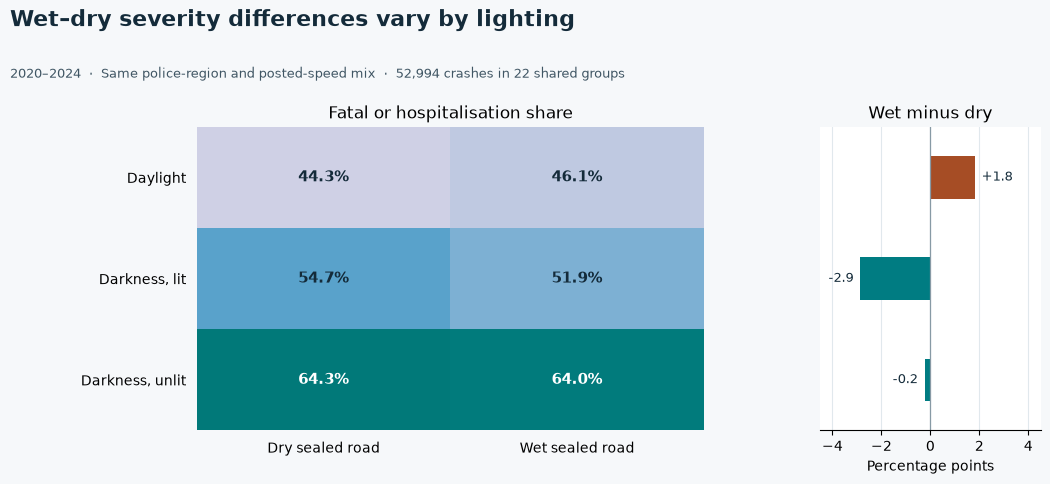

In [27]:
# Compare six lighting/surface combinations under one regional and speed-zone mix.
lights = ['Daylight', 'Darkness - Lighted', 'Darkness - Not lighted']
surfaces = ['Sealed - Dry', 'Sealed - Wet']
light_field, surface_field = 'Crash_Lighting_Condition', 'Crash_Road_Surface_Condition'
road_conditions = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
    & location_injury[light_field].isin(lights) & location_injury[surface_field].isin(surfaces)
    & location_injury['Crash_Speed_Limit'].notna()
].copy()
condition_order = pd.MultiIndex.from_product([surfaces, lights], names=[surface_field, light_field])
condition_counts = road_conditions.assign(Serious=road_conditions['Crash_Severity'].isin(severe_labels)).groupby(
    ['Police_Region', 'Crash_Speed_Limit', surface_field, light_field]
)['Serious'].agg(['size', 'sum'])
counts = condition_counts['size'].unstack([surface_field, light_field]).reindex(columns=condition_order)
serious = condition_counts['sum'].unstack([surface_field, light_field]).reindex(columns=condition_order)
common = counts.ge(10).all(axis=1)
supported = counts.loc[common]
weighted_count = supported.sum(axis=1)
weight = weighted_count / weighted_count.sum()
standardised = serious.loc[common].div(supported).mul(weight, axis=0).sum().mul(100)
standardised = standardised.unstack(surface_field).reindex(index=lights, columns=surfaces)
contrasts = standardised[surfaces[1]] - standardised[surfaces[0]]
assert standardised.notna().all(axis=None) and supported.ge(10).all(axis=None)
display(standardised.assign(**{'Wet − dry (pp)': contrasts}).round(1))

fig = plt.figure(figsize=(11.4, 4.9), facecolor='#f6f8fa')
grid = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], left=.22, right=.96, bottom=.12, top=.74, wspace=.32)
ax, contrast_ax = [fig.add_subplot(grid[0, i]) for i in range(2)]
fig.suptitle('Wet–dry severity differences vary by lighting', x=.056, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.056, .84, f'{recent_years.min()}–{recent_years.max()}  ·  Same police-region and posted-speed mix  ·  '
         f'{int(weighted_count.sum()):,} crashes in {int(common.sum())} shared groups',
         fontsize=9.5, color='#405664')

values = standardised.to_numpy()
ax.imshow(values, cmap='PuBuGn', vmin=35, vmax=72, aspect='auto')
ax.set(xticks=[0, 1], xticklabels=['Dry sealed road', 'Wet sealed road'],
       yticks=range(len(lights)), yticklabels=['Daylight', 'Darkness, lit', 'Darkness, unlit'],
       title='Fatal or hospitalisation share')
for i, j in np.ndindex(values.shape):
    ax.text(j, i, f'{values[i, j]:.1f}%', ha='center', va='center',
            color='white' if values[i, j] > 58 else '#142b3a', fontweight='bold', fontsize=11)
ax.tick_params(length=0, pad=8)
ax.spines[:].set_visible(False)

contrast_ax.barh(range(len(lights)), contrasts,
                 color=np.where(contrasts >= 0, '#a64d25', '#007c82'), height=.42)
contrast_ax.axvline(0, color='#879aa5', lw=.9)
contrast_ax.set(ylim=(len(lights)-.5, -.5), yticks=[], xlim=(-4.5, 4.5),
                xlabel='Percentage points', title='Wet minus dry')
for i, value in enumerate(contrasts):
    contrast_ax.annotate(f'{value:+.1f}', (value, i), xytext=(5 if value>=0 else -5, 0),
                         textcoords='offset points', va='center', ha='left' if value>=0 else 'right',
                         color='#142b3a', fontsize=9)
contrast_ax.grid(axis='x', color='#e1e8ed')
contrast_ax.set_axisbelow(True)
contrast_ax.spines[['top','right','left']].set_visible(False)
plt.show()

**What this achieved.** Standardised wet and dry sealed-road severity shares to a common region and speed-zone mix. In unlit darkness, both shares were about 64%.

##### Matched odds of serious crash outcomes

**In this cell.** Build two-by-two tables of flag presence and serious outcomes within each year and police region. Compare pooled odds ratios with Mantel–Haenszel estimates that combine evidence across those groups.

Groups compared  ...  Matched-region/year odds ratio
Source       Flag                                  ...                                
Vehicles     Motorcycle or moped               35  ...                            3.06
Factors      Speed                             35  ...                            2.79
             Drink driving                     35  ...                            2.57
Demographics Unlicensed driver                 35  ...                            1.75
Factors      Fatigued driver                   35  ...                            1.60
Vehicles     Truck                             35  ...                            1.10
Demographics Young driver                      35  ...                            0.86
Vehicles     Bus                               35  ...                            0.84

[8 rows x 3 columns]

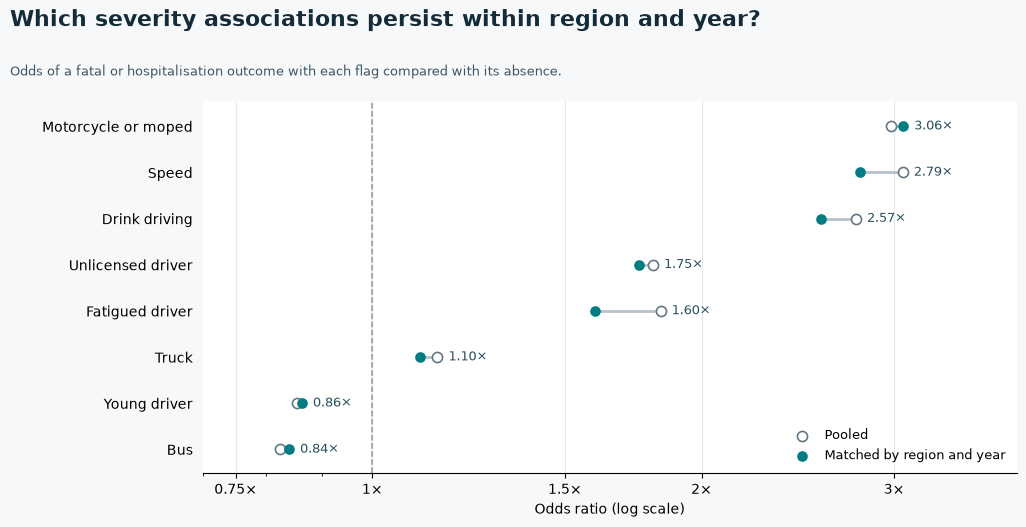

In [28]:
# Mantel–Haenszel odds ratios compare cases within the same year and police region.
association_inputs = [
    ('Factors', factor_injury, 'Involving_Driver_Speed', 'Speed'),
    ('Factors', factor_injury, 'Involving_Drink_Driving', 'Drink driving'),
    ('Factors', factor_injury, 'Involving_Fatigued_Driver', 'Fatigued driver'),
    ('Vehicles', vehicle_injury, vehicle_flags['Motorcycle or moped'], 'Motorcycle or moped'),
    ('Vehicles', vehicle_injury, vehicle_flags['Truck'], 'Truck'),
    ('Vehicles', vehicle_injury, vehicle_flags['Bus'], 'Bus'),
    ('Demographics', driver_injury, 'Involving_Young_Driver_16-24', 'Young driver'),
    ('Demographics', driver_injury, 'Involving_Unlicensed_Driver', 'Unlicensed driver'),
]
odds_results = []
for source_name, source, flag, label in association_inputs:
    records = source.loc[
        source['Crash_Year'].isin(recent_years) & source['Police_Region'].ne('Unknown')
        & source[flag].isin(['Yes', 'No'])
    ]
    col_order = pd.MultiIndex.from_product([['Yes', 'No'], [True, False]])
    strata = records.assign(Serious=records['Crash_Severity'].isin(severe_labels)).pivot_table(
        index=group_fields, columns=[flag, 'Serious'], values='Count_Crashes', aggfunc='sum', fill_value=0,
    ).reindex(columns=col_order, fill_value=0)
    a, b, c, d = strata.to_numpy(dtype=float).T
    usable = ((a+b)>0) & ((c+d)>0) & ((a+c)>0) & ((b+d)>0)
    totals = (a+b+c+d)[usable]
    a,b,c,d = a[usable],b[usable],c[usable],d[usable]
    adjusted_denominator = np.sum(b*c/totals)
    crude_denominator = b.sum()*c.sum()
    if adjusted_denominator and crude_denominator:
        odds_results.append({
            'Source': source_name, 'Flag': label, 'Groups compared': int(usable.sum()),
            'Pooled odds ratio': a.sum()*d.sum()/crude_denominator,
            'Matched-region/year odds ratio': np.sum(a*d/totals)/adjusted_denominator,
        })

severity_odds = pd.DataFrame(odds_results).sort_values('Matched-region/year odds ratio', ascending=False)
display(severity_odds.set_index(['Source', 'Flag']).round(2))
fig, ax = plt.subplots(figsize=(11.0, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.23, right=.97, bottom=.12, top=.81)
fig.suptitle('Which severity associations persist within region and year?',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .857, 'Odds of a fatal or hospitalisation outcome with each flag compared with its absence.',
         fontsize=9.5, color='#405664')
order = np.arange(len(severity_odds))
crude = severity_odds['Pooled odds ratio']
adjusted = severity_odds['Matched-region/year odds ratio']
ax.axvline(1, color='#879aa5', linewidth=1.1, linestyle='--')
ax.hlines(order, np.minimum(crude, adjusted), np.maximum(crude, adjusted), color='#b7c3ca', linewidth=2)
ax.scatter(crude, order, facecolor='white', edgecolor='#647884', linewidth=1.2, s=53, label='Pooled', zorder=3)
ax.scatter(adjusted, order, color='#007c82', s=44, label='Matched by region and year', zorder=4)
for y, value, pooled in zip(order, adjusted, crude):
    ax.annotate(f'{value:.2f}×', (max(value, pooled), y), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, color='#28505c')
ax.set(xscale='log', yticks=order, yticklabels=severity_odds['Flag'],
       ylim=(len(order)-.48, -.55), xlabel='Odds ratio (log scale)')
ax.set_xlim(min(.72, float(min(crude.min(),adjusted.min()))*.85),
            float(max(crude.max(),adjusted.max()))*1.27)
ax.xaxis.set_major_locator(mticker.FixedLocator([.75, 1, 1.5, 2, 3, 4]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f'{value:g}×'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

**What this achieved.** Compared pooled and region-year-matched odds ratios for reported flags. The matched fatal-or-hospitalisation odds ratios were 3.06 for motorcycle or moped involvement and 2.79 for recorded speed involvement.

## Phase 3 · Modelling

Develop the supervised severity classifier and the exploratory clustering and rule models. The classifier uses a time-ordered split. The clustering and rules describe patterns in the recorded data.

### Train the severity classifiers

Fit a Random Forest with the original training distribution and a second Random Forest with SMOTENC applied to the training data. Use four injury severity classes and keep the latest three crash years for evaluation. The model uses documented crash and road conditions with casualty outcome fields excluded.

**In this cell.** Train two Random Forest classifier pipelines using one-hot encoding for categorical features. Apply SMOTENC to the training data for one model and reserve later crash years for evaluation.

In [29]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

categorical = [
    'Crash_Nature', 'Crash_Type', 'Crash_Day_Of_Week', 'Crash_Speed_Limit',
    'Crash_Lighting_Condition', 'Crash_Atmospheric_Condition',
    'Crash_Road_Surface_Condition', 'Crash_Traffic_Control',
]
numeric = ['Crash_Hour']
target = 'Crash_Severity'
test_years = [int(year) for year in sorted(raw[YEAR].unique())[-3:]]
injury_crashes = raw.loc[raw[target].ne('Property damage only')]
train = injury_crashes.loc[~injury_crashes[YEAR].isin(test_years)]
test = injury_crashes.loc[injury_crashes[YEAR].isin(test_years)]
if len(train) > 60_000:
    train, _ = train_test_split(train, train_size=60_000, stratify=train[target], random_state=SEED)

def predictors(frame):
    # Use recorded data and explicit unknown categories for the model.
    features = frame[[*numeric, *categorical]].copy()
    features[categorical] = features[categorical].fillna('Unknown').astype(object)
    return features

X_train, X_test = predictors(train), predictors(test)
y_train, y_test = train[target], test[target]
fitted_models = {}
for label, sampler in [
    ('Random Forest', 'passthrough'),
    ('Random Forest + SMOTENC', SMOTENC(categorical_features=categorical, random_state=SEED)),
]:
    encoder = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('hour', 'passthrough', numeric),
    ])
    model = Pipeline([
        ('rebalance', sampler),
        ('encode', encoder),
        ('forest', RandomForestClassifier(n_estimators=80, max_depth=15, min_samples_leaf=5,
                                          random_state=SEED, n_jobs=4)),
    ])
    model.fit(X_train, y_train)
    fitted_models[label] = model

print(f"Training rows: {len(train):,} | Test rows: {len(test):,} | Test years: {test_years}")

Training rows: 60,000 | Test rows: 35,009 | Test years: [2023, 2024, 2025]


**What this achieved.** Fitted the two classifier pipelines on 60,000 sampled training rows and held back 35,009 later records. The fitted pipelines are available in the session for evaluation.

### Cluster crash locations and timing

Fit five K-Means clusters to standardized longitude, latitude, crash hour, and crash year. Ensure the fit uses observed locations, then assign estimated locations to the fitted clusters. Cluster IDs identify groups within this run. Hour is represented as in V2, so midnight sits at the boundary of the hour scale.

**In this cell.** Standardise coordinate, hour, and year features and fit five K-Means clusters to crashes with observed coordinates. Assign eligible records to those clusters and display a sample on an Esri map.

In [30]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

cluster_features = ['Crash_Longitude', 'Crash_Latitude', 'Crash_Hour', 'Crash_Year']
training_points = observed_points[cluster_features].dropna()
cluster_points = map_points[cluster_features].dropna().copy()
scaler = StandardScaler().fit(training_points)
with threadpool_limits(limits=4):
    kmeans = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(scaler.transform(training_points))
    cluster_points['Cluster'] = kmeans.predict(scaler.transform(cluster_points))
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=cluster_features)
centers['Assigned crashes'] = cluster_points['Cluster'].value_counts()
display(centers.round(2).rename_axis('Cluster'))

cluster_map = folium.Map(
    location=observed_points[COORDS].median().tolist(), zoom_start=6, tiles='Esri.WorldStreetMap'
)
for cluster, color in enumerate(['#236780', '#b05a28', '#2c7e52', '#865db1', '#a3394d']):
    layer = folium.FeatureGroup(name=f'Cluster {cluster}').add_to(cluster_map)
    rows = cluster_points.loc[cluster_points['Cluster'].eq(cluster), COORDS]
    for point in rows.sample(n=min(240, len(rows)), random_state=SEED).to_numpy().tolist():
        folium.CircleMarker(point, radius=3, color=color, fill=True, fill_opacity=.65,
                            weight=1, tooltip=f'Cluster {cluster}').add_to(layer)
folium.LayerControl().add_to(cluster_map)
display(cluster_map)

,Crash_Longitude,Crash_Latitude,Crash_Hour,Crash_Year,Assigned crashes
Cluster,,,,,
0,152.74,-27.08,7.54,2018.91,56898
1,152.75,-27.11,16.43,2006.06,127638
2,146.42,-19.06,12.81,2010.61,65760
3,152.81,-27.18,16.27,2018.95,82436
4,152.73,-27.07,7.29,2006.18,82204


**What this achieved.** Fitted five K-Means clusters using recorded coordinates and standardised spatial and time features. Assigned eligible records to the fitted clusters and saved an Esri map of the sampled results.

### Find associations among crash factors

Use Apriori to identify common combinations of severity, crash nature, lighting, speed zone, and weather. Require at least 5% support and 40% confidence, then rank rules with a severity outcome by lift. Lift compares the severity rate among records matching the rule with its overall rate. Use these associations to describe co-occurrence in the recorded crashes.

**In this cell.** Encode recorded crash characteristics as indicator variables and use Apriori to find frequent combinations. Filter severity-outcome association rules by support and confidence, then rank them by lift.

In [31]:
from mlxtend.frequent_patterns import apriori, association_rules

rule_fields = [
    'Crash_Severity', 'Crash_Nature', 'Crash_Lighting_Condition',
    'Crash_Speed_Limit', 'Crash_Atmospheric_Condition',
]
transactions = pd.get_dummies(
    cleaned[rule_fields].fillna('Unknown'), prefix_sep=' = ', dtype=bool, sparse=True
)
itemsets = apriori(transactions, min_support=.05, use_colnames=True, max_len=3, low_memory=True)
rules = association_rules(
    itemsets, num_itemsets=len(transactions), metric='confidence', min_threshold=.40
)
severity_rules = rules.loc[rules['consequents'].map(
    lambda items: len(items) == 1 and next(iter(items)).startswith('Crash_Severity = ')
)].sort_values(['lift', 'support'], ascending=False).head(12)
rule_table = severity_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
for column in ['antecedents', 'consequents']:
    rule_table[column] = rule_table[column].map(lambda items: ' + '.join(sorted(items)))
display(rule_table.round(3).reset_index(drop=True))

,antecedents,consequents,support,confidence,lift
0,Crash_Nature = Rear-end + Crash_Speed_Limit = ...,Crash_Severity = Medical treatment,0.065,0.453,1.446
1,Crash_Lighting_Condition = Daylight + Crash_Na...,Crash_Severity = Medical treatment,0.090,0.445,1.421
2,Crash_Atmospheric_Condition = Clear + Crash_Na...,Crash_Severity = Medical treatment,0.099,0.443,1.416
3,Crash_Nature = Rear-end,Crash_Severity = Medical treatment,0.109,0.440,1.403
4,Crash_Atmospheric_Condition = Clear + Crash_Na...,Crash_Severity = Hospitalisation,0.068,0.402,1.254


**What this achieved.** Ranked Apriori rules for recorded crash characteristics. The leading displayed rule linked rear-end crashes in a 60 km/h zone with medical treatment, with lift of about 1.45.

## Phase 4 · Evaluation and quality decisions

Evaluate the classifier on its held-out later records. Review the trade-off between fatal-class detection and false positives before choosing a model or threshold.

### Evaluate held-out severity predictions

Compare accuracy, macro F1, fatal-class recall and the class-level report. Review the confusion matrix and impurity-based feature importance. The test spans 2023–2025 and includes the partial 2025 release.

**In this cell.** Score both classifiers on the held-out later years. Compare accuracy, macro F1, and fatal-class recall, then inspect the class-level report, normalised confusion matrix, and impurity-based feature importance.

,Accuracy,Macro F1,Fatal recall
Model,,,
Random Forest,0.499,0.274,0.000
Random Forest + SMOTENC,0.335,0.284,0.495


,precision,recall,f1-score,support
Crash_Severity,,,,
Hospitalisation,0.597,0.347,0.439,17202.0
Medical treatment,0.374,0.290,0.327,11126.0
Minor injury,0.223,0.367,0.277,6021.0
Fatal,0.050,0.495,0.091,660.0


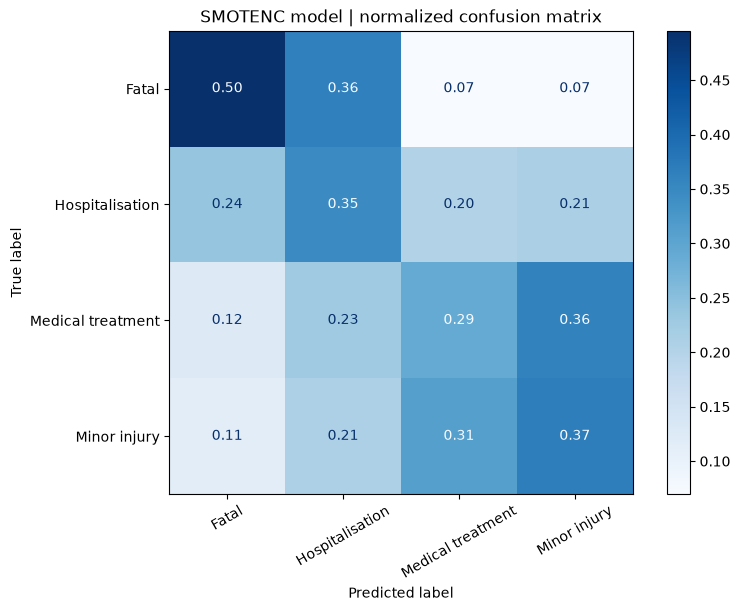

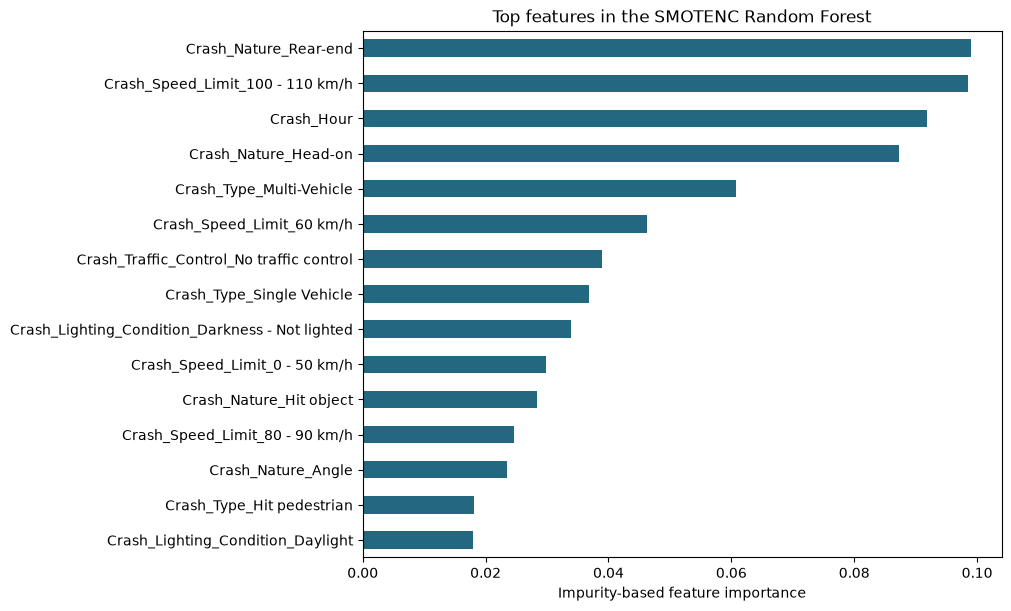

In [32]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score

model_results = []
models = {}
for label, model in fitted_models.items():
    predicted = model.predict(X_test)
    report = classification_report(y_test, predicted, output_dict=True, zero_division=0)
    model_results.append({
        'Model': label, 'Accuracy': accuracy_score(y_test, predicted),
        'Macro F1': f1_score(y_test, predicted, average='macro'), 'Fatal recall': report['Fatal']['recall'],
    })
    models[label] = (model, predicted, report)

display(pd.DataFrame(model_results).set_index('Model').round(3))
balanced_model, balanced_prediction, balanced_report = models['Random Forest + SMOTENC']
display(pd.DataFrame(balanced_report).T.reindex(y_test.value_counts().index).round(3))

fig, ax = plt.subplots(figsize=(8, 6), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    y_test, balanced_prediction, normalize='true', xticks_rotation=30,
    cmap='Blues', values_format='.2f', ax=ax,
)
ax.set_title('SMOTENC model | normalized confusion matrix')
plt.show()

feature_names = balanced_model.named_steps['encode'].get_feature_names_out()
importance = pd.Series(balanced_model.named_steps['forest'].feature_importances_, index=feature_names)
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
importance.nlargest(15).sort_values().rename(index=lambda name: name.split('__', 1)[1]).plot.barh(
    ax=ax, color='#236780', title='Top features in the SMOTENC Random Forest'
)
ax.set_xlabel('Impurity-based feature importance')
plt.show()

**What this achieved.** SMOTENC increased fatal recall from 0.000 to 0.495 and macro F1 from 0.274 to 0.284. Fatal precision was about 0.05, and overall accuracy fell from 0.499 to 0.335. The low precision makes false alerts an important criterion before any operational use.

### Results at a glance

The following summaries come from the calculations above. For maps or location-sensitive analyses, use `Coordinate_Method` to select observed locations or include the estimates deliberately.

**In this cell.** Collect the main findings from spatial recovery, model evaluation, association rules, and regional comparisons into a single run summary.

In [33]:
print(f"Most common severity: {severity.index[0]} ({severity.iloc[0]:,} crashes).")
print(f"Peak recorded hour across severity levels: {hourly.sum().idxmax():02}:00.")
print(f"Crash records with both coordinates estimated: {len(targets) - cleaned.loc[targets, COORDS].isna().any(axis=1).sum():,}.")
print(f"Additional coordinate pairs estimated in the second pass: {int(second_pass.sum()):,}.")
print(f"Review-only coordinate candidates: {cleaned['Second_pass_review_latitude'].notna().sum():,}.")
print(f"Coordinate pairs still missing: {int((~available['Coordinate pair']).sum()):,}.")
print(f"Other crash attributes inferred before the public spatial match: {missing_audit.drop(index=COORDS)['Values inferred'].sum():,}.")
both_location_fields = ~recorded['Suburb'] & ~recorded['Council area'] & available['Suburb'] & available['Council area']
print(f"Crashes with both suburb and council area recovered: {both_location_fields.sum():,}.")
for result in model_results:
    print(f"{result['Model']}: macro F1 {result['Macro F1']:.3f}, fatal recall {result['Fatal recall']:.3f}.")
if not rule_table.empty:
    strongest = rule_table.iloc[0]
    print(f"Top displayed severity rule: {strongest['antecedents']} → {strongest['consequents']} "
          f"(lift {strongest['lift']:.2f}).")
print(f"All six files contribute to {regional_summary.notna().all(axis=1).sum():,} "
      f"of {len(regional_summary):,} year-and-police-region groups.")

suburb_recovered = int(cleaned['Suburb_Only_Name'].notna().sum())
print(f"Suburbs recovered separately for crashes without coordinates: {suburb_recovered:,}.")
print(f"Crashes still missing both a suburb and coordinates: {int((~available['Suburb'] & ~available['Coordinate pair']).sum()):,}.")

vehicle_fatal = vehicle_severity['Fatal share (%)'].unstack()
for kind in ['Truck', 'Motorcycle or moped']:
    involved, absent = vehicle_fatal.loc[kind, ['Involved', 'Absent']]
    print(f"{kind} fatal share among injury crashes: {involved:.1f}% with the flag and {absent:.1f}% without.")

volume_region = regional_profile['Injury crashes'].idxmax()
severity_region = regional_profile['Serious crash (%)'].idxmax()
print(f"Highest recorded injury crash volume: {volume_region} "
      f"({regional_profile.at[volume_region, 'Injury crashes']:,}).")
print(f"Highest fatal or hospitalisation share: {severity_region} "
      f"({regional_profile.at[severity_region, 'Serious crash (%)']:.1f}%).")

Most common severity: Hospitalisation (133,287 crashes).
Peak recorded hour across severity levels: 15:00.
Crash records with both coordinates estimated: 127.
Additional coordinate pairs estimated in the second pass: 1.
Review-only coordinate candidates: 5.
Coordinate pairs still missing: 471.
Other crash attributes inferred before the public spatial match: 2.
Crashes with both suburb and council area recovered: 127.
Random Forest: macro F1 0.274, fatal recall 0.000.
Random Forest + SMOTENC: macro F1 0.284, fatal recall 0.495.
Top displayed severity rule: Crash_Nature = Rear-end + Crash_Speed_Limit = 60 km/h → Crash_Severity = Medical treatment (lift 1.45).
All six files contribute to 184 of 186 year-and-police-region groups.
Suburbs recovered separately for crashes without coordinates: 28.
Crashes still missing both a suburb and coordinates: 443.
Truck fatal share among injury crashes: 4.8% with the flag and 1.7% without.
Motorcycle or moped fatal share among injury crashes: 4.4% with

**What this achieved.** Brought the saved data quality, descriptive and model findings together. The results support exploration and follow-up validation before any operational model decision.

## Phase 5 · Deployment readiness

The notebook and CSVs provide a local analytical release. An operational model release would need a versioned bundle with its fitted preprocessing, training configuration, dependency lock, input schema, and evaluation report. Choose the delivery mode once the intended user and decision are agreed. For a batch release, verify input/output contracts, reproduce predictions after reloading the bundle, and rehearse rollback to the previous approved version.

## Phase 6 · Monitoring and maintenance

For periodic data refreshes, track source coverage, reporting lag, missing fields, unknown categories, cross-file count differences, and spatial match rates. If the classifier is used operationally, monitor input and prediction drift, fatal precision and recall once actual labels arrive, and performance by region and reporting period. Assign owners and thresholds, document the response to a failed check, and require validation and approval before replacing a model.

### Missing process elements

| Stage | What to complete | Evidence to record |
|---|---|---|
| **Before further model selection** | Agree who uses the result, what action it informs, when the prediction is made and which inputs are available then. Agree acceptable fatal-class precision and recall and the cost of missed cases and false alerts. | A signed-off use case, feature availability list and measurable acceptance criteria. |
| **Before repeatable releases** | Version the six source extracts and spatial layers. Record checksums, source dates, cutoffs, the environment, configuration and random seed. Turn the existing ID, tally and coordinate checks into automated pipeline checks. | A run manifest and a repeatable validation report with explicit pass conditions. |
| **Before operational model use** | Compare with a simple baseline and class-weighted alternatives. Use rolling time splits, keep a final period for one independent evaluation, and check the partial-year reporting effect. Measure fatal precision–recall, calibration if probabilities are used, and performance by region, year and available conditions. Report uncertainty for small samples. | A model evaluation report and a decision against the agreed thresholds. |
| **Before applying exploratory findings** | Check cluster stability across years and configurations and confirm whether the association rules recur in later periods. Check spatial recovery errors by method and locality, particularly in groups with few validation matches. | Stability and coverage tables with review decisions. |
| **If a model moves into use** | Package and register the approved pipeline, test it on representative inputs, establish a release and rollback procedure, then assign monitoring and retraining ownership. Add automated integration, delivery or training where the release cadence warrants it. | A versioned model bundle, release checklist, monitoring plan and documented triggers for investigation and revalidation. |

The next decision is whether V3 will remain a research and reporting notebook or support a defined operational prediction. That decision determines which production steps are needed.

## Practical use cases for the Queensland crash analysis

The examples below use recorded crashes or casualties. The regional, restraint, and adjusted severity comparisons cited here cover 2020–2024. Traffic volumes or distance travelled would be needed to compare risk per trip or kilometre.

### Common use cases

- **Plan patrol and incident-response coverage.** Use the severity-by-hour heatmap and the observed-location Esri layers to shortlist areas and times for a coverage review. The most crashes were recorded at 15:00 across all severity levels. Check that the pattern holds by police region, day of week, and recent reporting year before changing shifts.
- **Prioritise road safety inspections.** Use the crash-type bars and observed-location map to shortlist corridors for field checks. Brisbane recorded the most injury crashes (18,395), while Central had the highest fatal-or-hospitalisation share (66.5%). Use counts to assess service demand and the severity share to flag areas for investigation. Confirm the locations and review road design and traffic volumes before choosing treatments.
- **Target and evaluate restraint campaigns.** Use the road-user and equipment Sankey to choose which seatbelt or helmet messages warrant review, and use the female occupant bubble map to compare known-status counts and shares by region. Among female occupant casualties with known seatbelt status, 778 of 31,696 were recorded as unrestrained. Track the known-status share and the amount of missing status together when comparing periods.

### Less obvious use cases

- **Audit lighting at unlit sites in both wet and dry conditions.** After standardising the region and speed-zone mix, about 64% of recorded injury crashes in unlit darkness were fatal or required hospitalisation on both wet and dry sealed roads. Use the lighting and surface heatmap to shortlist sites for a night inspection of lighting, delineation and signage. Check exposure and site history before selecting a treatment.
- **Check whether a statewide pattern holds locally before targeting enforcement.** The correlation between reported speed involvement and serious-outcome shares fell from 0.81 in the pooled region-year comparison to 0.12 after accounting for typical region and year differences. Use the paired scatter plots to question statewide rankings, then consult local speed surveys and crash records before allocating corridor-level enforcement.
- **Use location recovery to triage data-quality work.** Of the 598 crashes originally missing coordinates, 127 gained estimated coordinate pairs and another 28 gained a suburb only. Include suburb-only records in suburb-level summaries where appropriate. For site-level reviews, start with observed coordinates and check how estimates change the shortlist. Use the 443 records still missing both fields to prioritise searches for original location evidence.